# Unsupervised Patient Profiling and Longitudinal Disease-State Analysis in Diabetic Retinopathy

This standalone PBL-2 notebook covers **Unit 3 (clustering)** and **Unit 4 (sequential/Markov models)** using Protocol AA. It is separate from the Unit 1/Unit 2 notebook. Findings are exploratory—not validated clinical subtypes, prognoses, or causal treatment effects.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import display, Image

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
TABLES = ROOT / 'outputs' / 'pbl2' / 'tables'
FIGURES = ROOT / 'outputs' / 'pbl2' / 'figures'
from src.pbl2.data_loader import discover_archive
from src.pbl2.data_validation import build_longitudinal_dataset
from src.pbl2.preprocessing import build_baseline_dataset, CLUSTER_FEATURES
from pbl2_main import main as run_pipeline

archive = discover_archive(ROOT)
run_pipeline()
print('Archive:', archive.relative_to(ROOT))
print('Tables:', len(list(TABLES.glob('*.csv'))), 'Figures:', len(list(FIGURES.glob('*.png'))))

{
  "raw_severity_rows": 11628,
  "canonical_annual_rows_including_ungradable": 3280,
  "ungradable_rows_excluded": 124,
  "valid_graded_visits": 3156,
  "unique_patients": 388,
  "unique_patient_eyes": 772,
  "sequences_at_least_2": 697,
  "sequences_at_least_3": 640,
  "sequences_at_least_4": 585,
  "complete_5_visit_sequences": 462,
  "unmatched_grade_visit_rows": 0,
  "missing_dates_in_canonical_grades": 0,
  "canonical_template": "UWF_with_Mask"
}
Selected K-Means K=2; hierarchical=ward, K=6; ARI=0.099
Generated 24 figures and 23 tables
Archive: data/Protocol_AA.zip
Tables: 23 Figures: 24


## 1. Introduction and Research Objectives

Unit 3 compares hierarchical and partitional clustering through structure, metrics, stability, and interpretation. Unit 4 distinguishes sequential data, estimates empirical transitions, and evaluates first- versus second-order dependence.

In [2]:
eligibility = pd.read_csv(TABLES / 'longitudinal_eligibility.csv')
display(eligibility.T.rename(columns={0: 'verified_value'}))

,verified_value
raw_severity_rows,11628
canonical_annual_rows_including_ungradable,3280
ungradable_rows_excluded,124
valid_graded_visits,3156
unique_patients,388
unique_patient_eyes,772
sequences_at_least_2,697
sequences_at_least_3,640
sequences_at_least_4,585
complete_5_visit_sequences,462


## 2. PBL-1 Research Continuity

PBL-1 studied supervised classification in the cross-sectional Debrecen dataset. PBL-2 uses a distinct cohort for unsupervised profiling and longitudinal state analysis; their metrics are not direct benchmarks.

In [3]:
print((ROOT / 'reports' / 'pbl1_pbl2_continuity.md').read_text())

# PBL-1 to PBL-2 Research Continuity

PBL-1 used the cross-sectional Debrecen extracted-feature dataset for supervised classification, conditional-independence analysis, and SVM kernel geometry. PBL-2 uses the distinct Protocol AA cohort for unsupervised baseline profiling and longitudinal DR state transitions. Classification answers label-prediction questions; clustering explores feature-based similarity; Markov analysis describes temporal dependence. The cohorts, features, and outcomes are not harmonized, so PBL-1 accuracy is not a benchmark for PBL-2.



## 3. Protocol AA Dataset Selection

Protocol AA provides documented baseline measurements and annual eye-level DR grading through four years.

In [4]:
inventory = pd.read_csv(TABLES / 'dataset_inventory.csv')
display(inventory[['table','rows','columns','unique_patients','duplicate_rows']])

,table,rows,columns,unique_patients,duplicate_rows
0,AABaselineOcuMedHx.txt,388,48,388,0
1,AABaselineOcularExam.txt,388,43,388,0
2,AABldPress.txt,1690,8,388,0
3,AAChorThickOCT.txt,1565,11,377,0
4,AADRSSData.txt,11628,8,388,0
5,AAEnrollment.txt,388,20,388,0
6,AAFUOcularExam.txt,1302,42,354,0
7,AAFUOcularMedUp.txt,1266,37,353,0
8,AAJoslinRCGradingResult.txt,1126265,10,388,0
9,AALab.txt,1654,14,388,0


## 4. Dataset Description and Validation

The pipeline selects the consistently available `UWF_with_Mask` annual grade, preserves original grades, excludes ungradable code 90, and validates unique keys and dates.

In [5]:
baseline, rationale = build_baseline_dataset(archive)
longitudinal, audit = build_longitudinal_dataset(archive)
print(json.dumps(audit, indent=2))
display(pd.read_csv(TABLES / 'visit_completeness.csv'))
display(rationale)

{
  "raw_severity_rows": 11628,
  "canonical_annual_rows_including_ungradable": 3280,
  "ungradable_rows_excluded": 124,
  "valid_graded_visits": 3156,
  "unique_patients": 388,
  "unique_patient_eyes": 772,
  "sequences_at_least_2": 697,
  "sequences_at_least_3": 640,
  "sequences_at_least_4": 585,
  "complete_5_visit_sequences": 462,
  "unmatched_grade_visit_rows": 0,
  "missing_dates_in_canonical_grades": 0,
  "canonical_template": "UWF_with_Mask"
}


,Visit,visit_records,dated_visits,explicitly_missed,valid_graded_eyes,graded_patients
0,Baseline,388,388,0,742,381
1,1 year,358,345,13,645,335
2,2 year,340,330,10,631,321
3,3 year,322,307,15,588,301
4,4 year,284,284,0,550,283


,feature,role,reason
0,age,clustering_input,Baseline numerical measurement; no future info...
1,diabetes_duration,clustering_input,Baseline numerical measurement; no future info...
2,bmi,clustering_input,Baseline numerical measurement; no future info...
3,systolic_bp,clustering_input,Baseline numerical measurement; no future info...
4,diastolic_bp,clustering_input,Baseline numerical measurement; no future info...
5,hba1c,clustering_input,Baseline numerical measurement; no future info...
6,visual_acuity_letters,clustering_input,Baseline numerical measurement; no future info...
7,oct_central_thickness,clustering_input,Baseline numerical measurement; no future info...
8,original_dr_grade/dro,interpretation_only,Excluded from inputs to avoid outcome-driven c...
9,creatinine/eGFR/urine,excluded,Substantially lower baseline availability


## 5. Exploratory Data Analysis

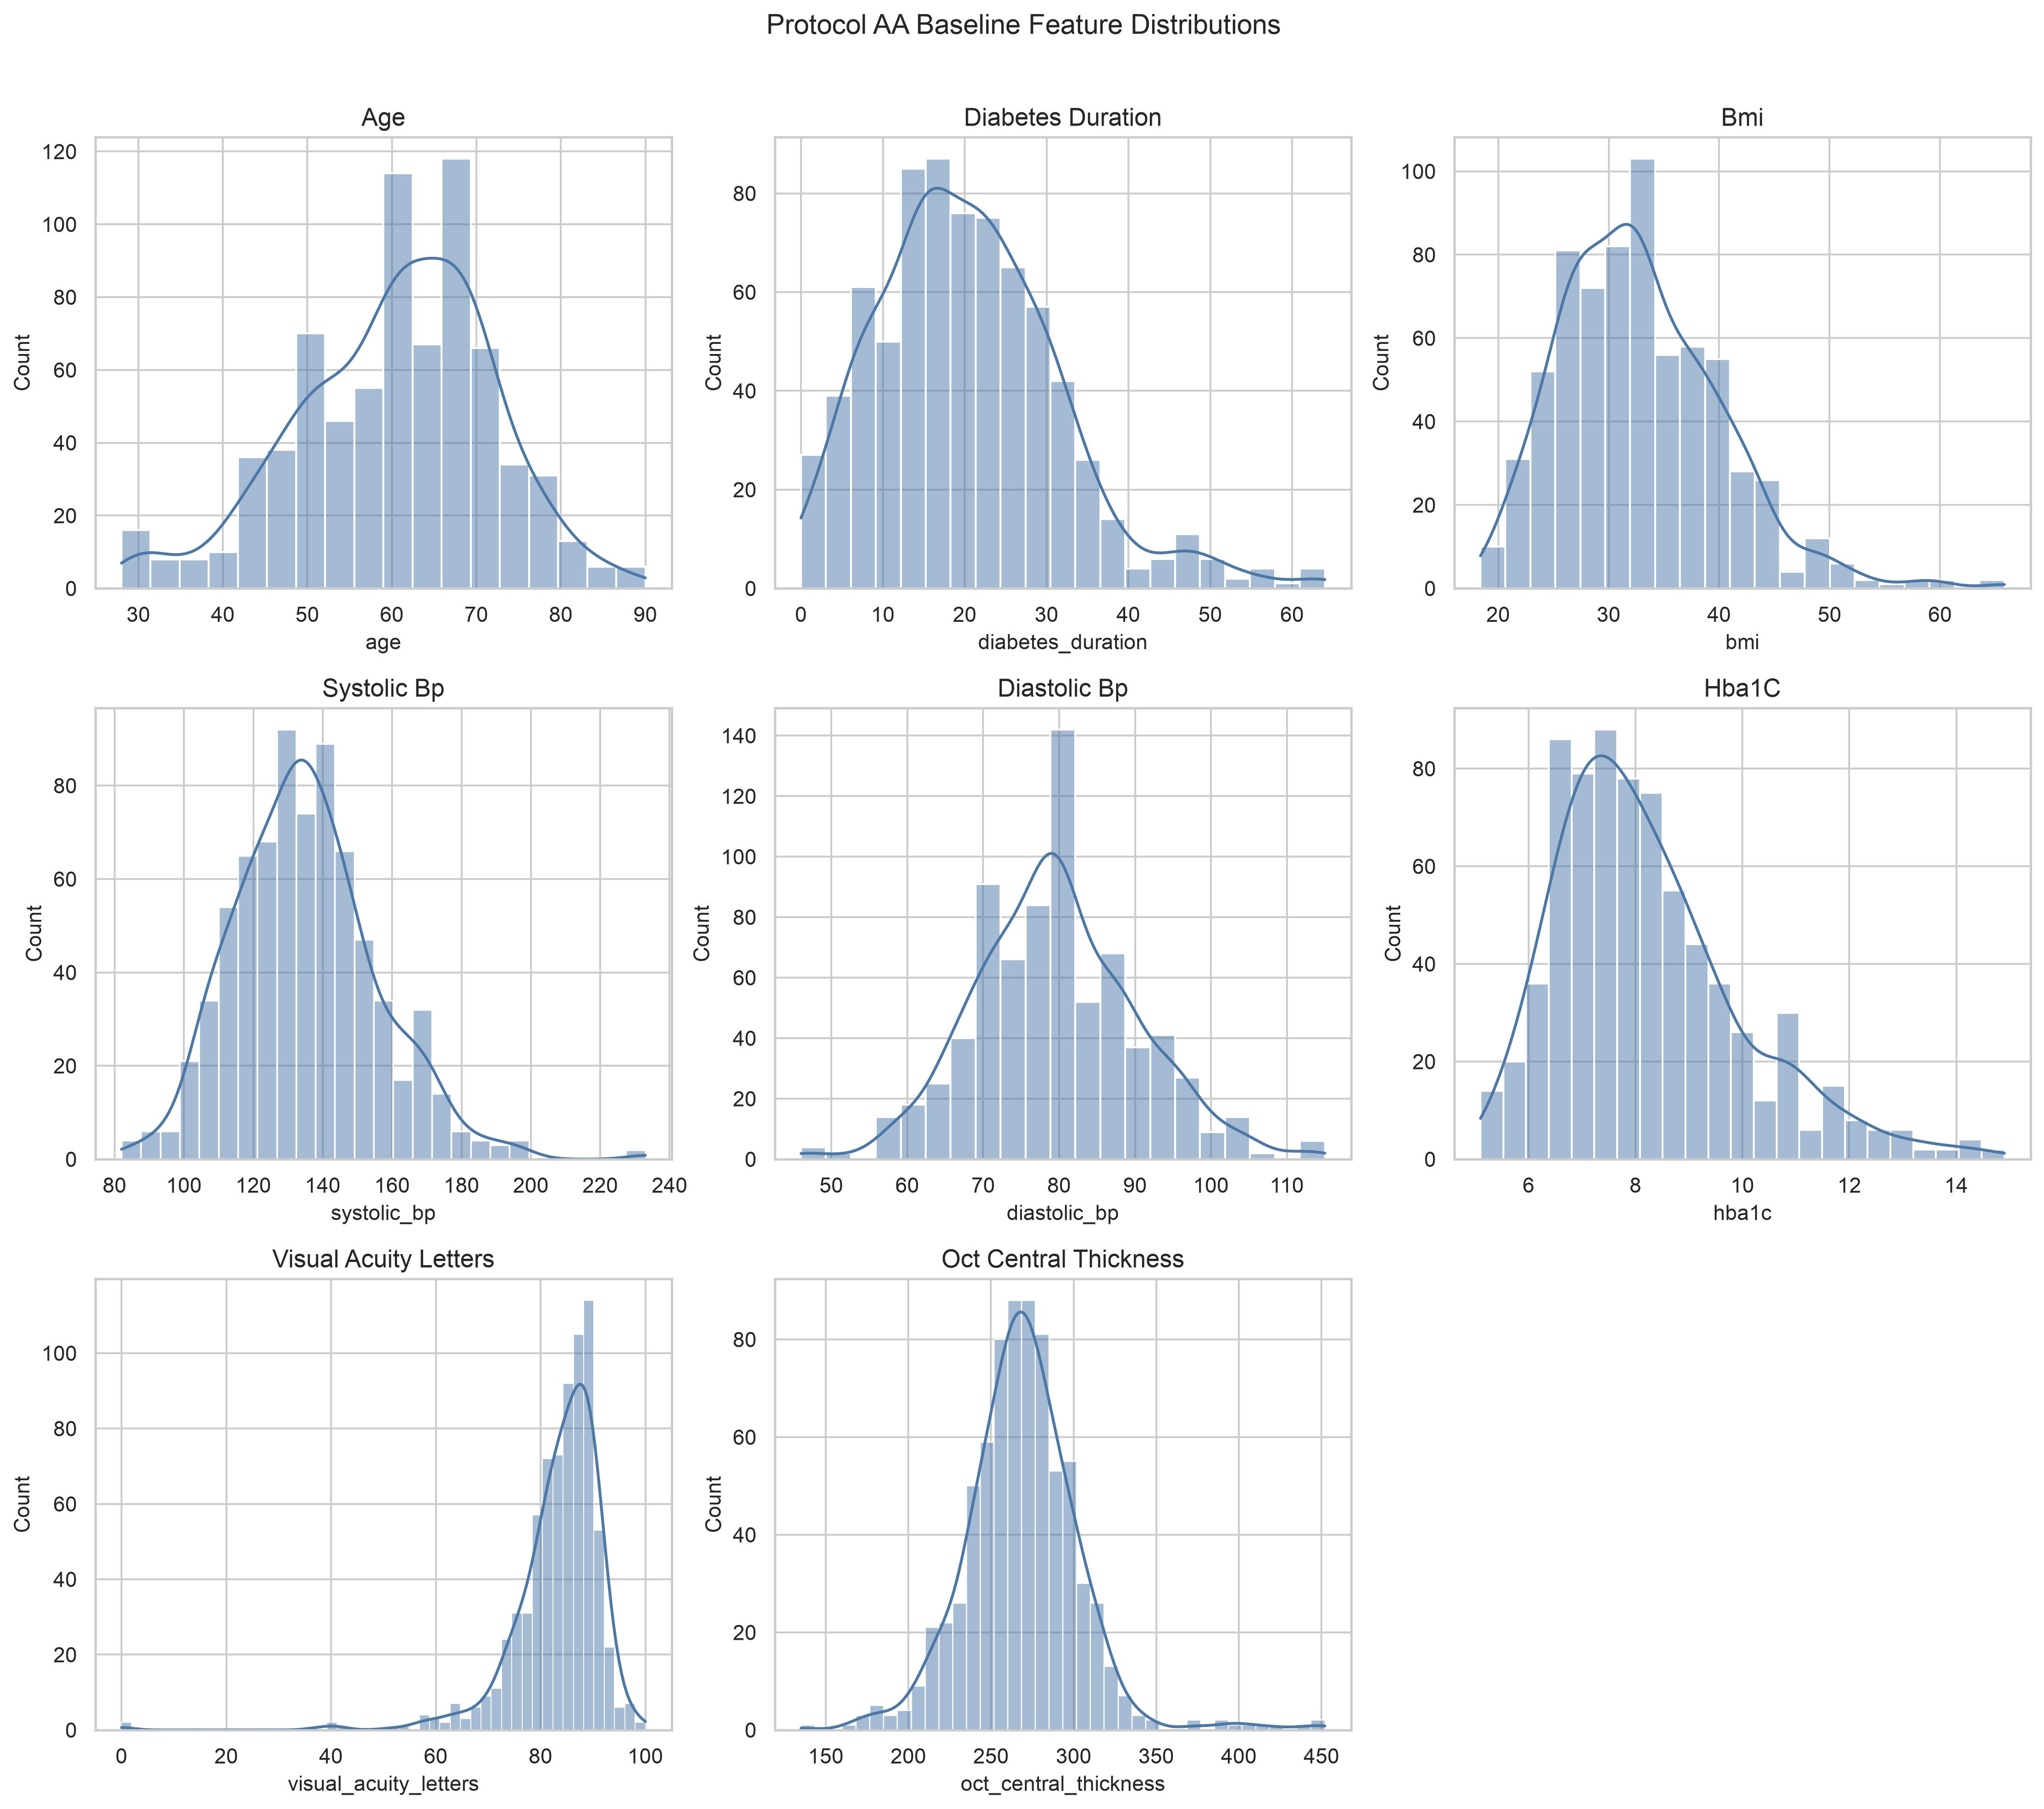

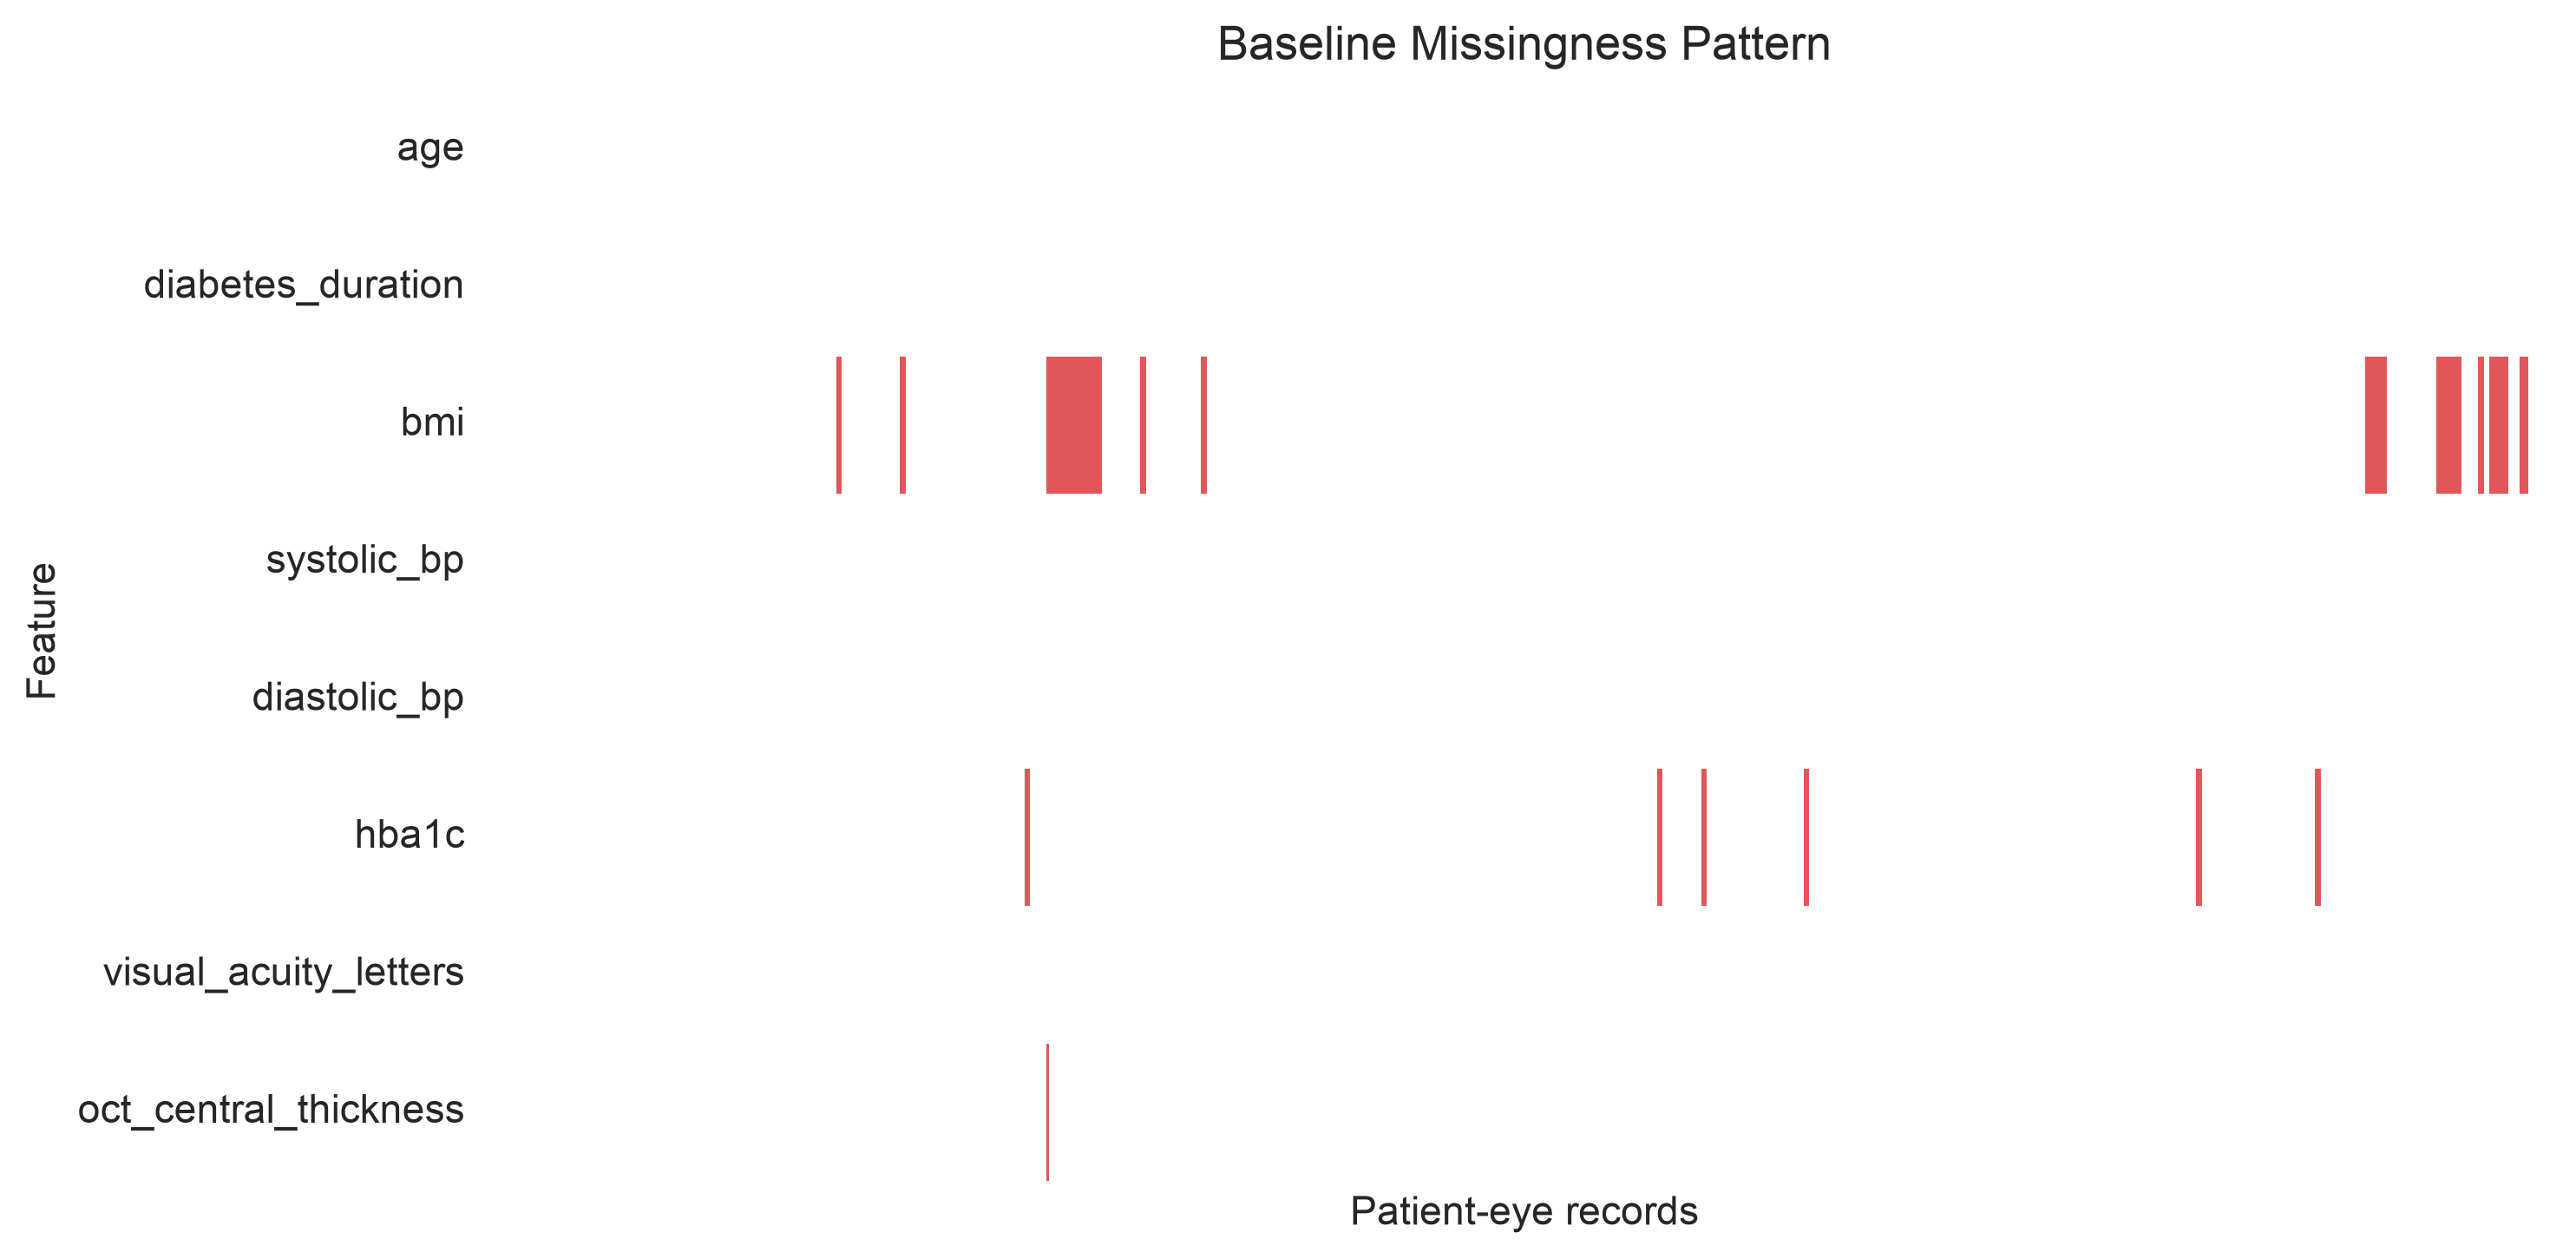

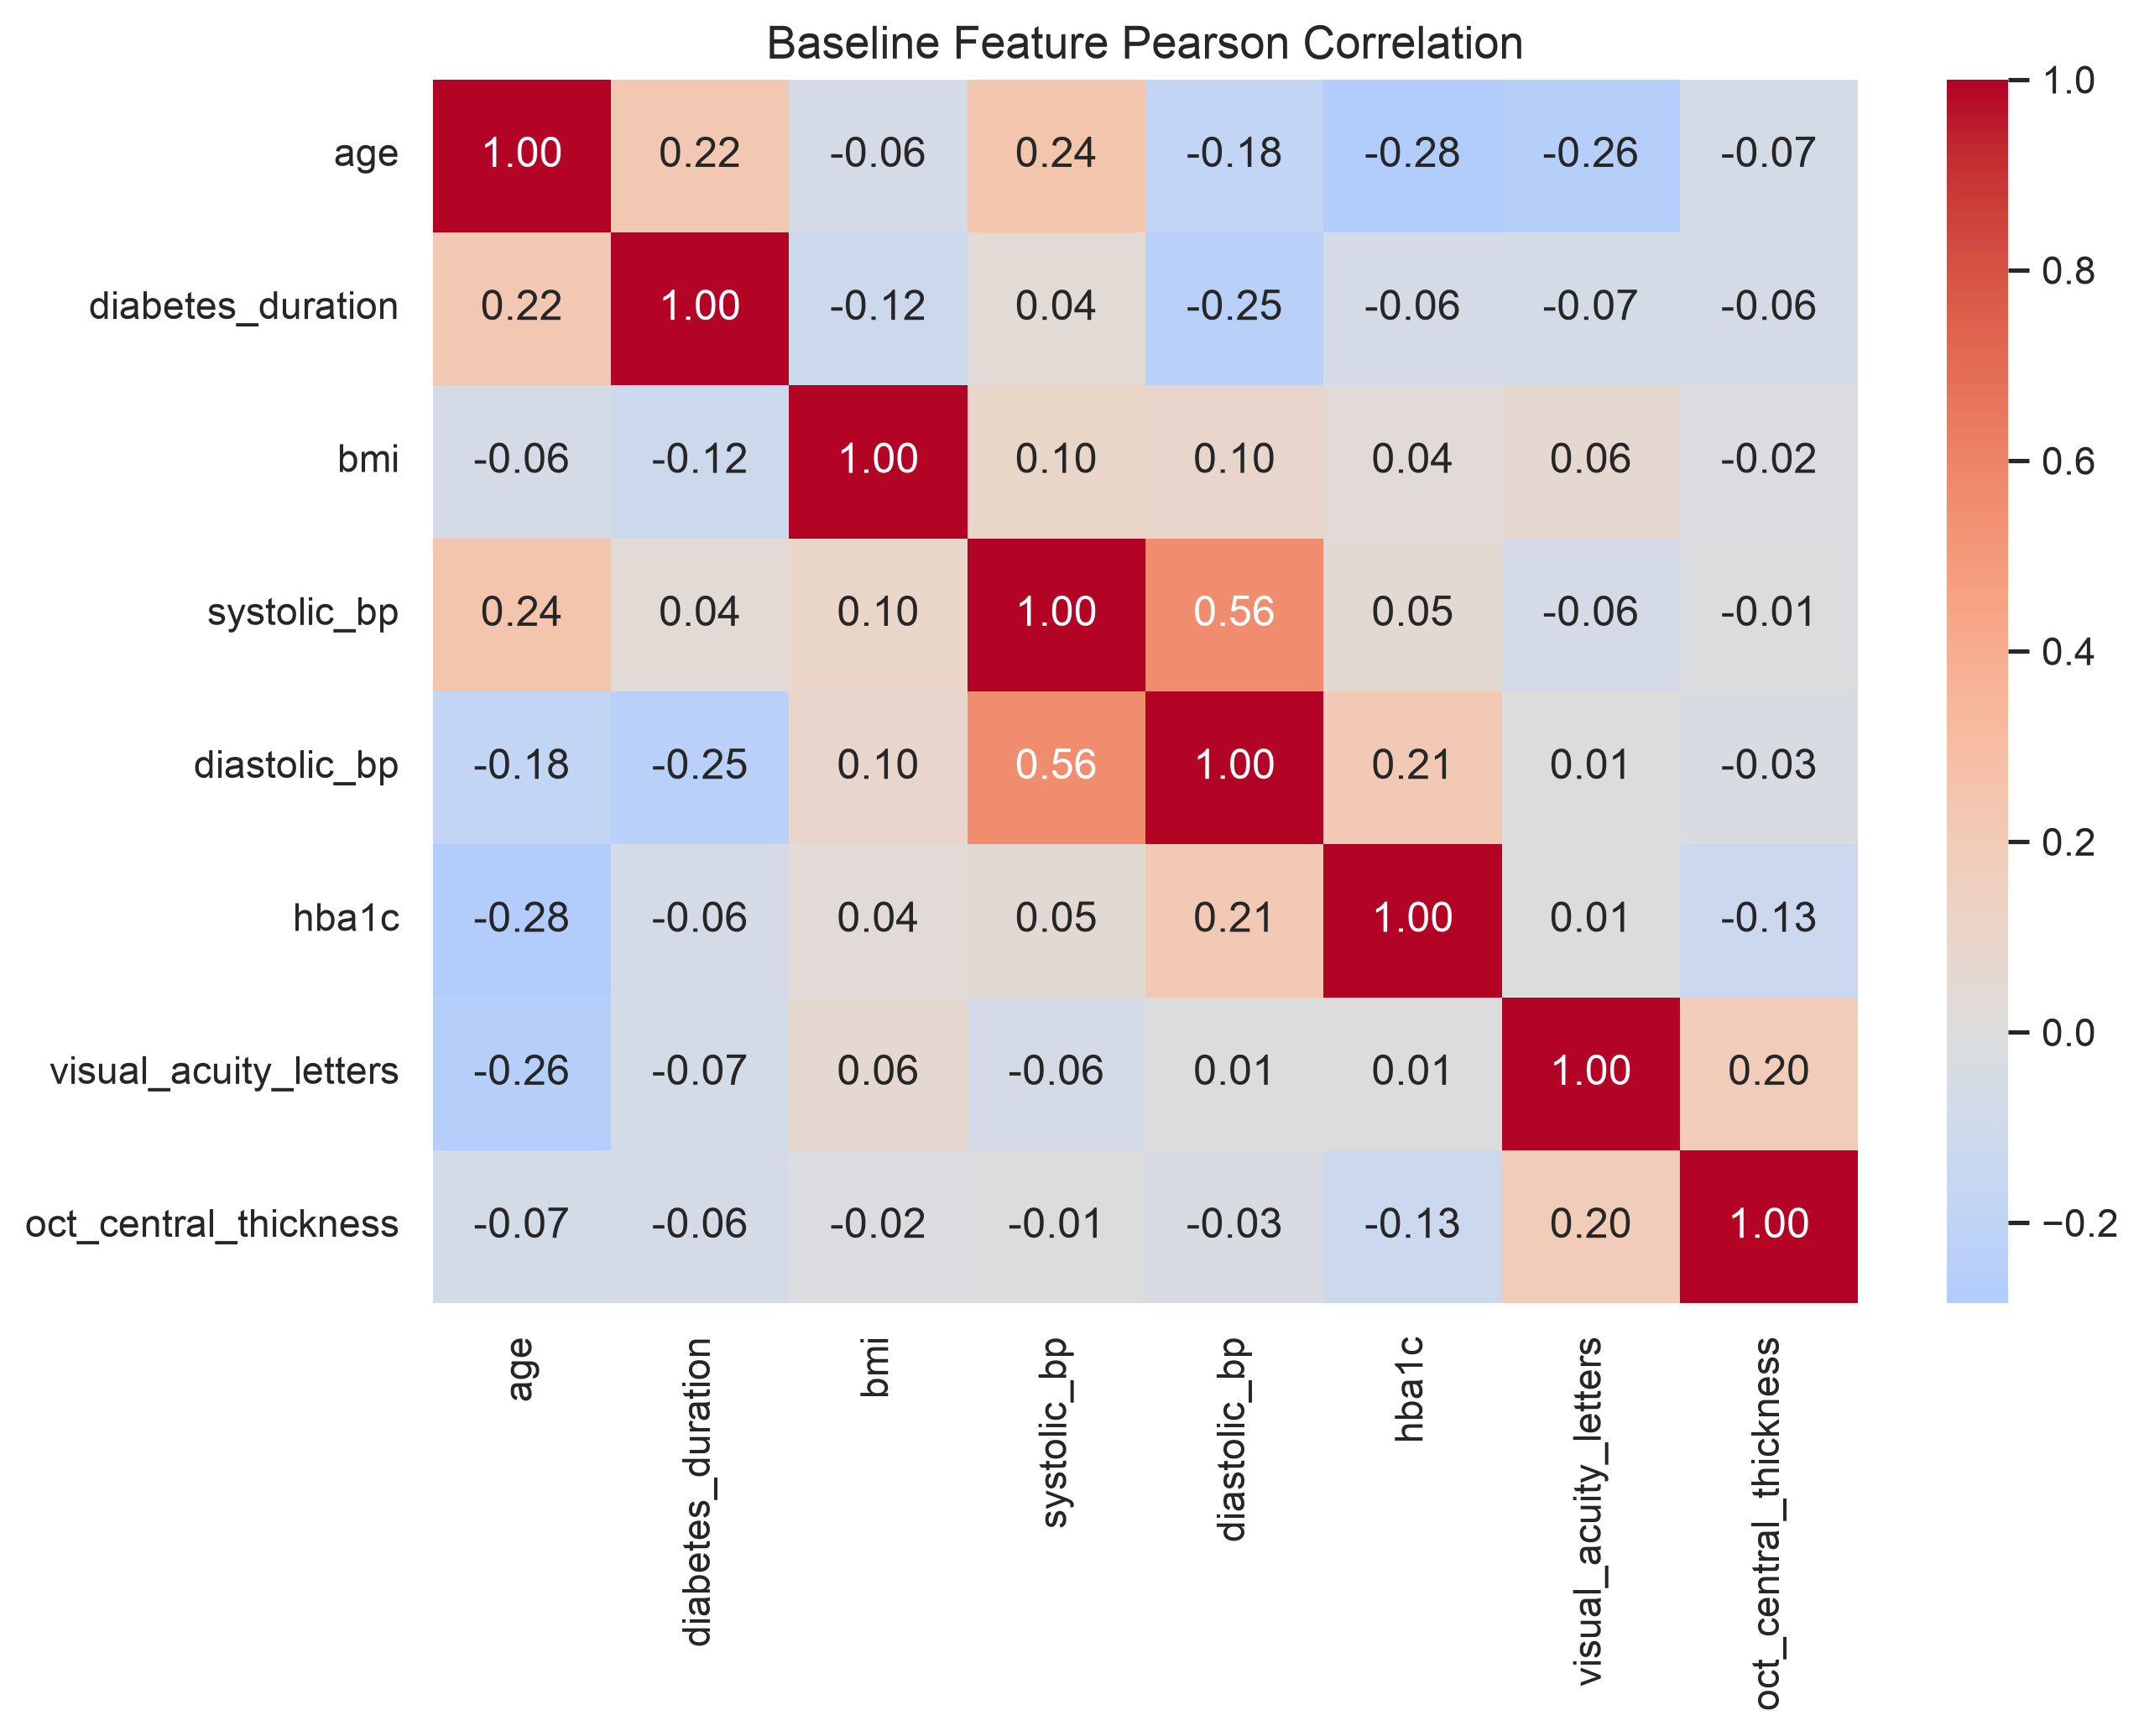

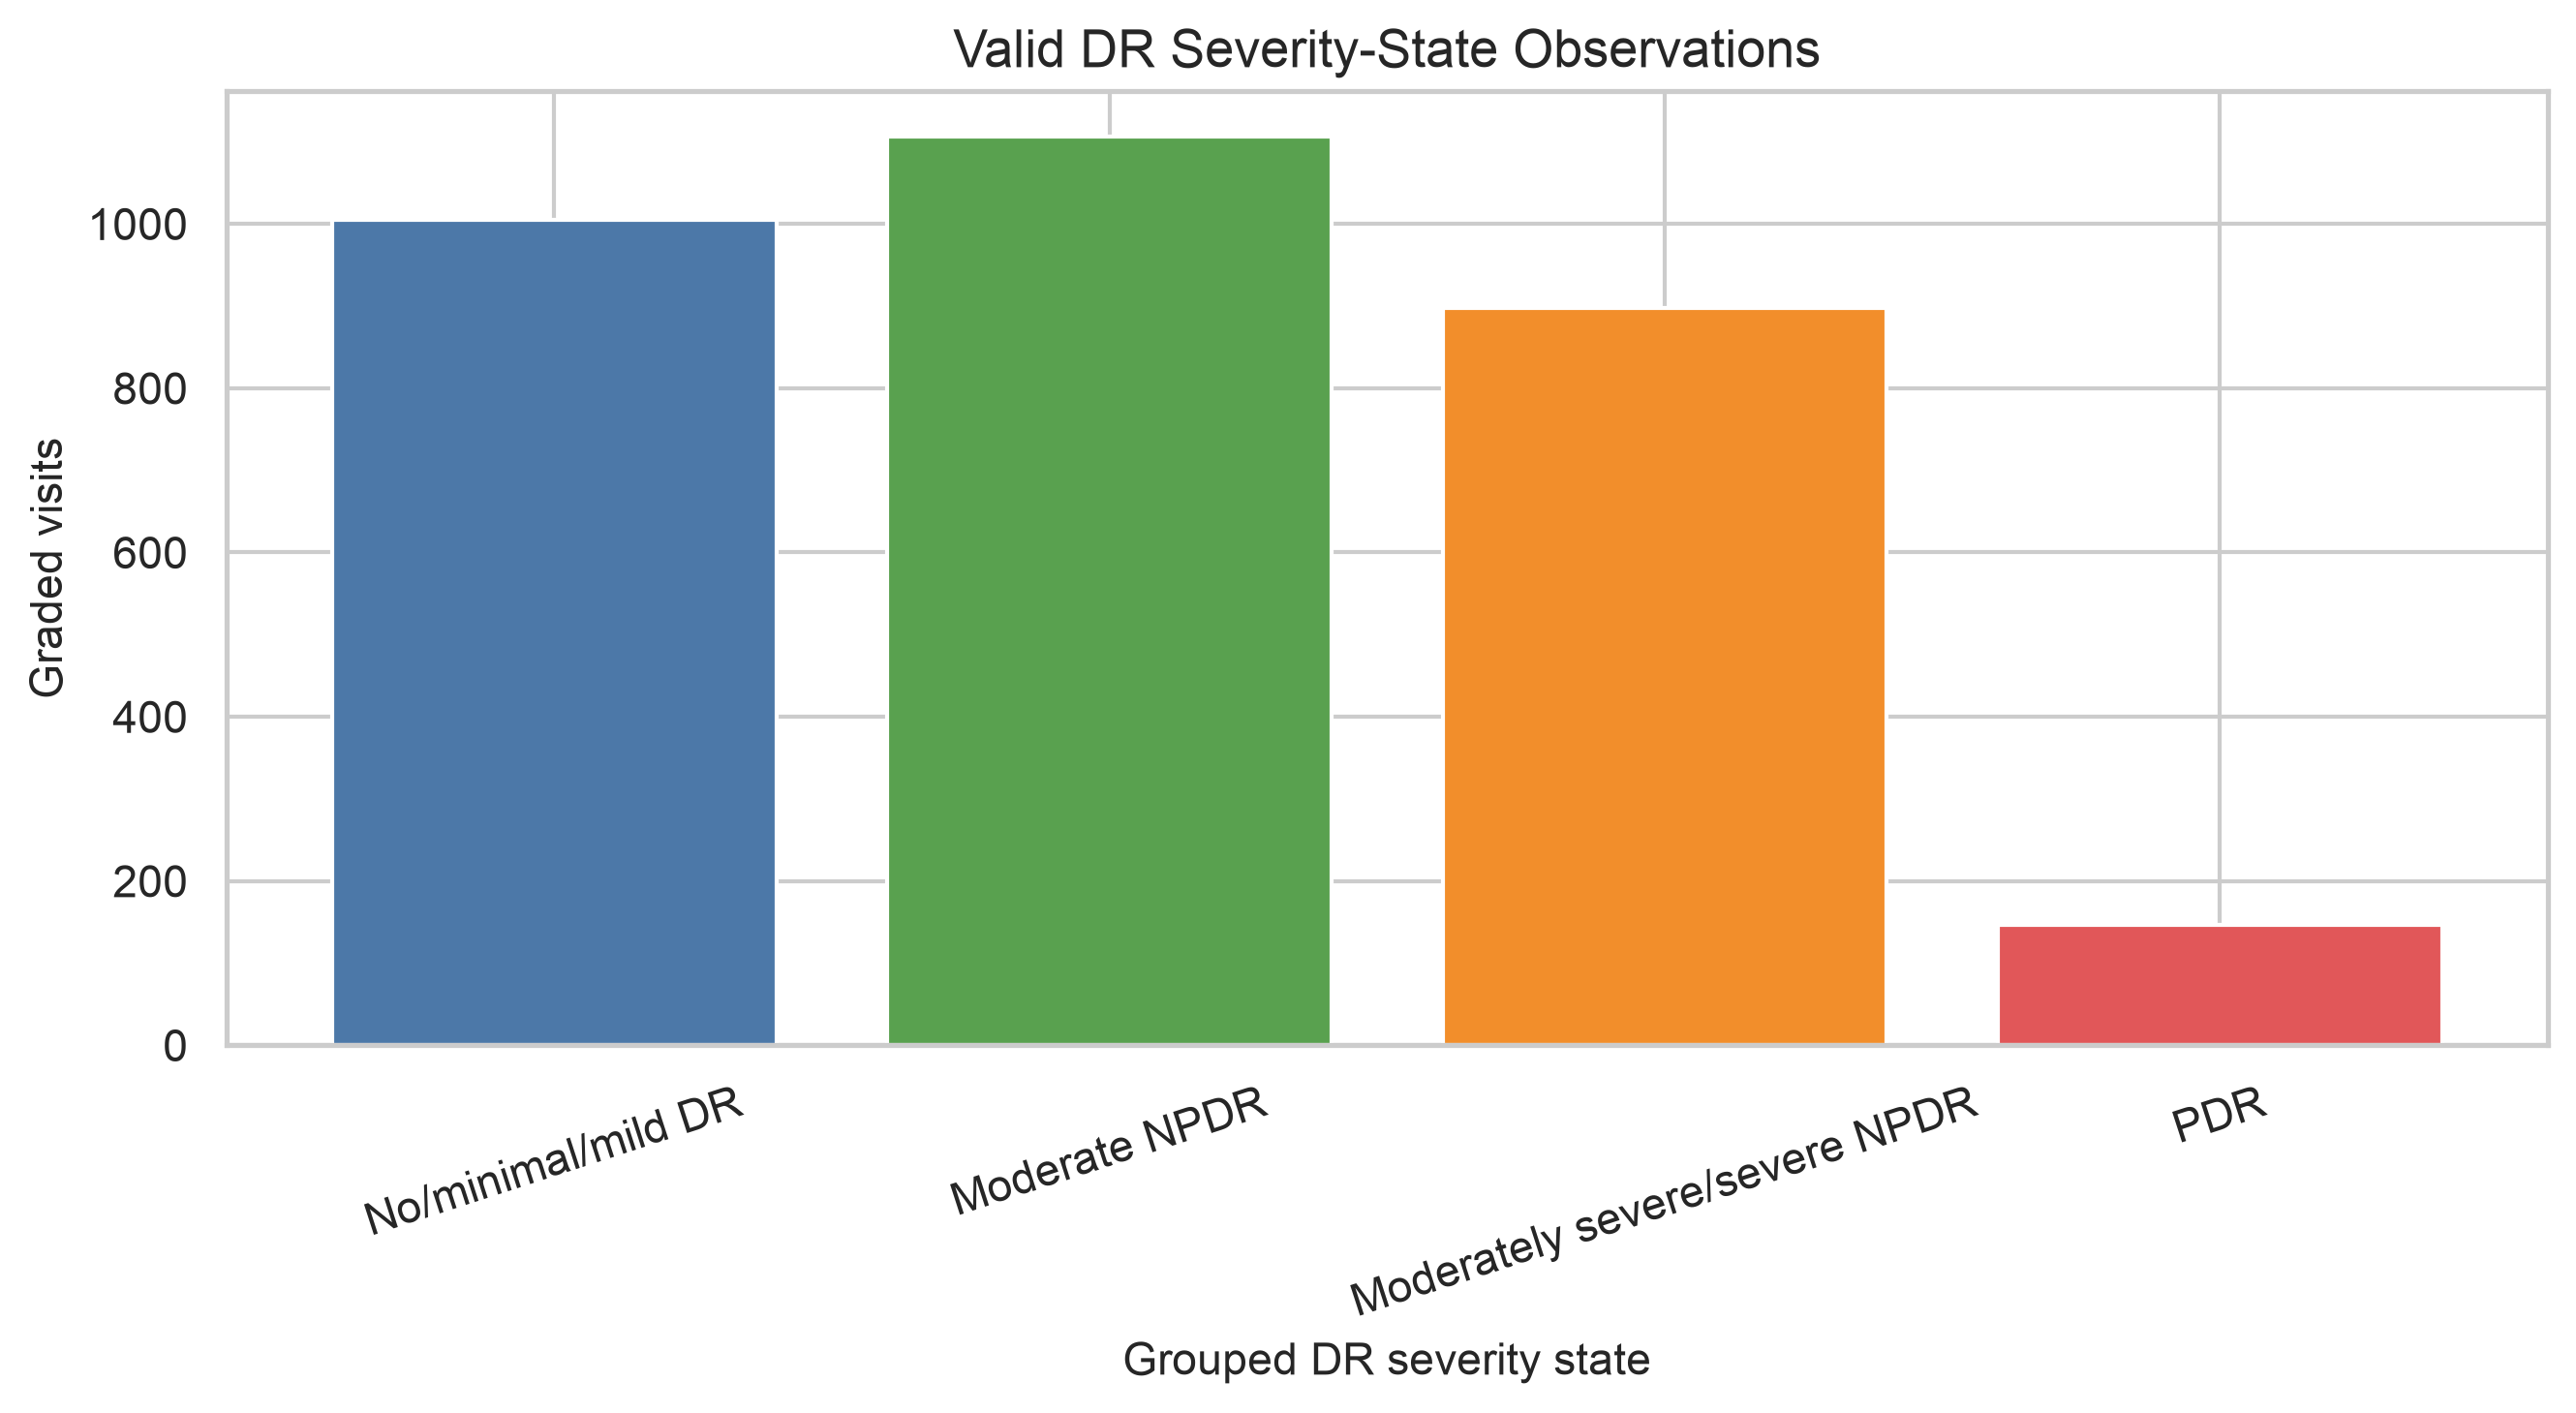

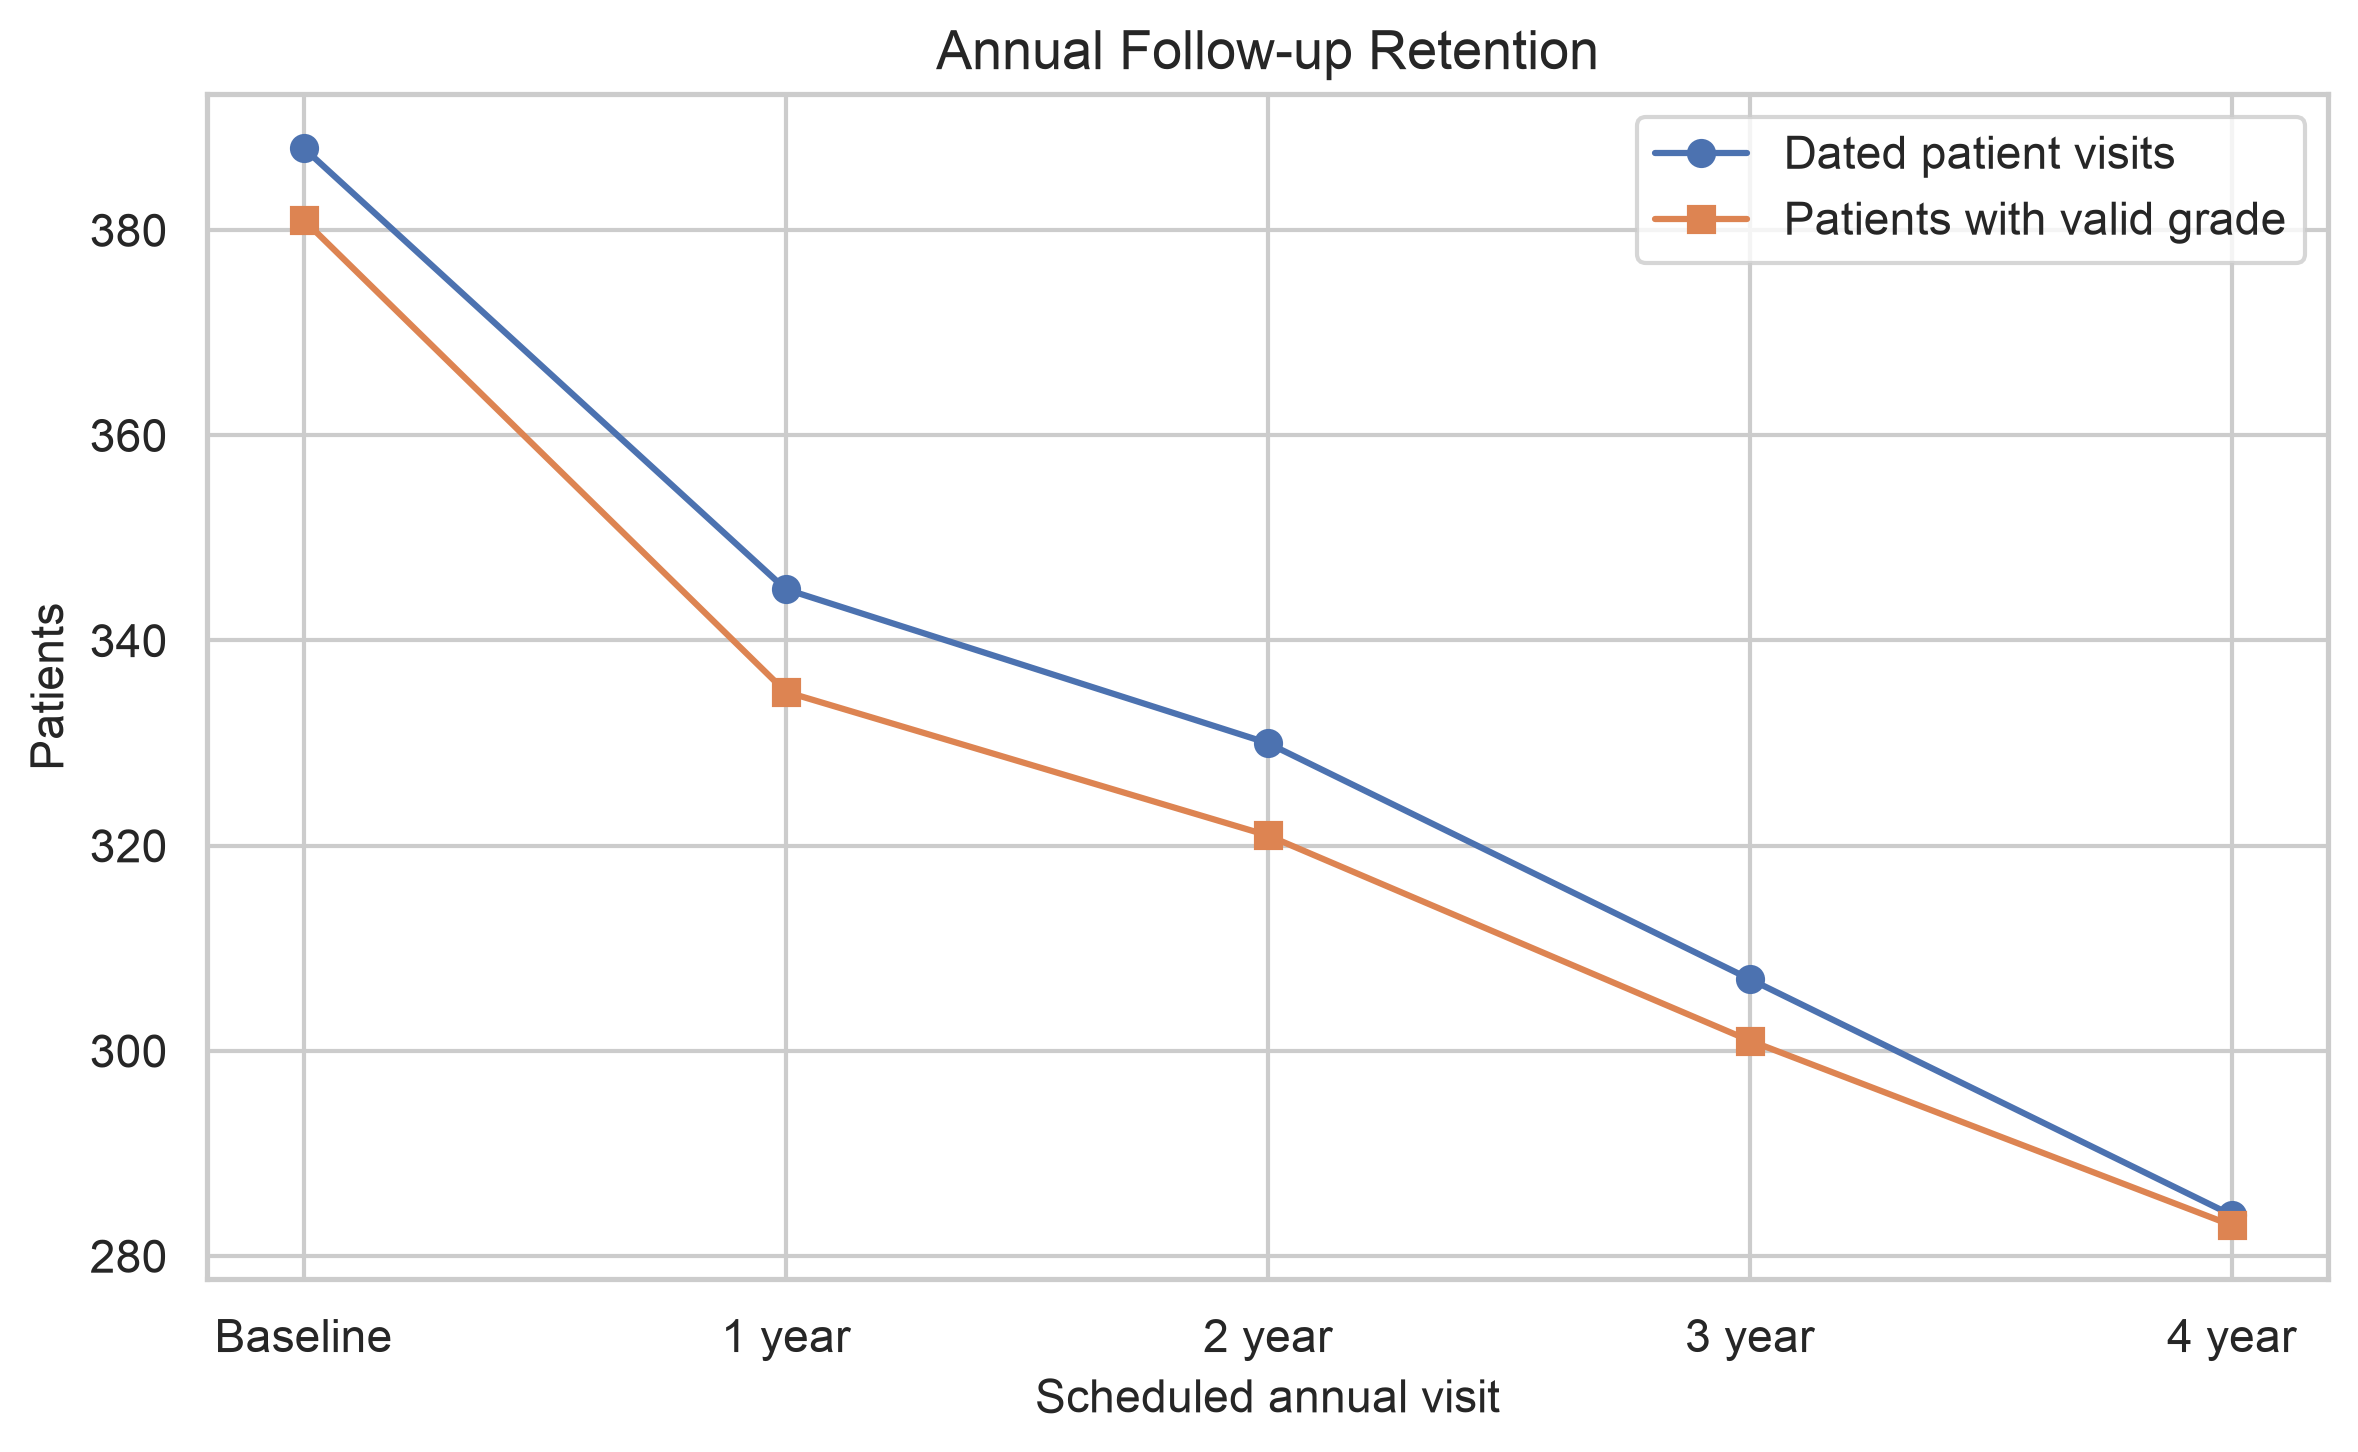

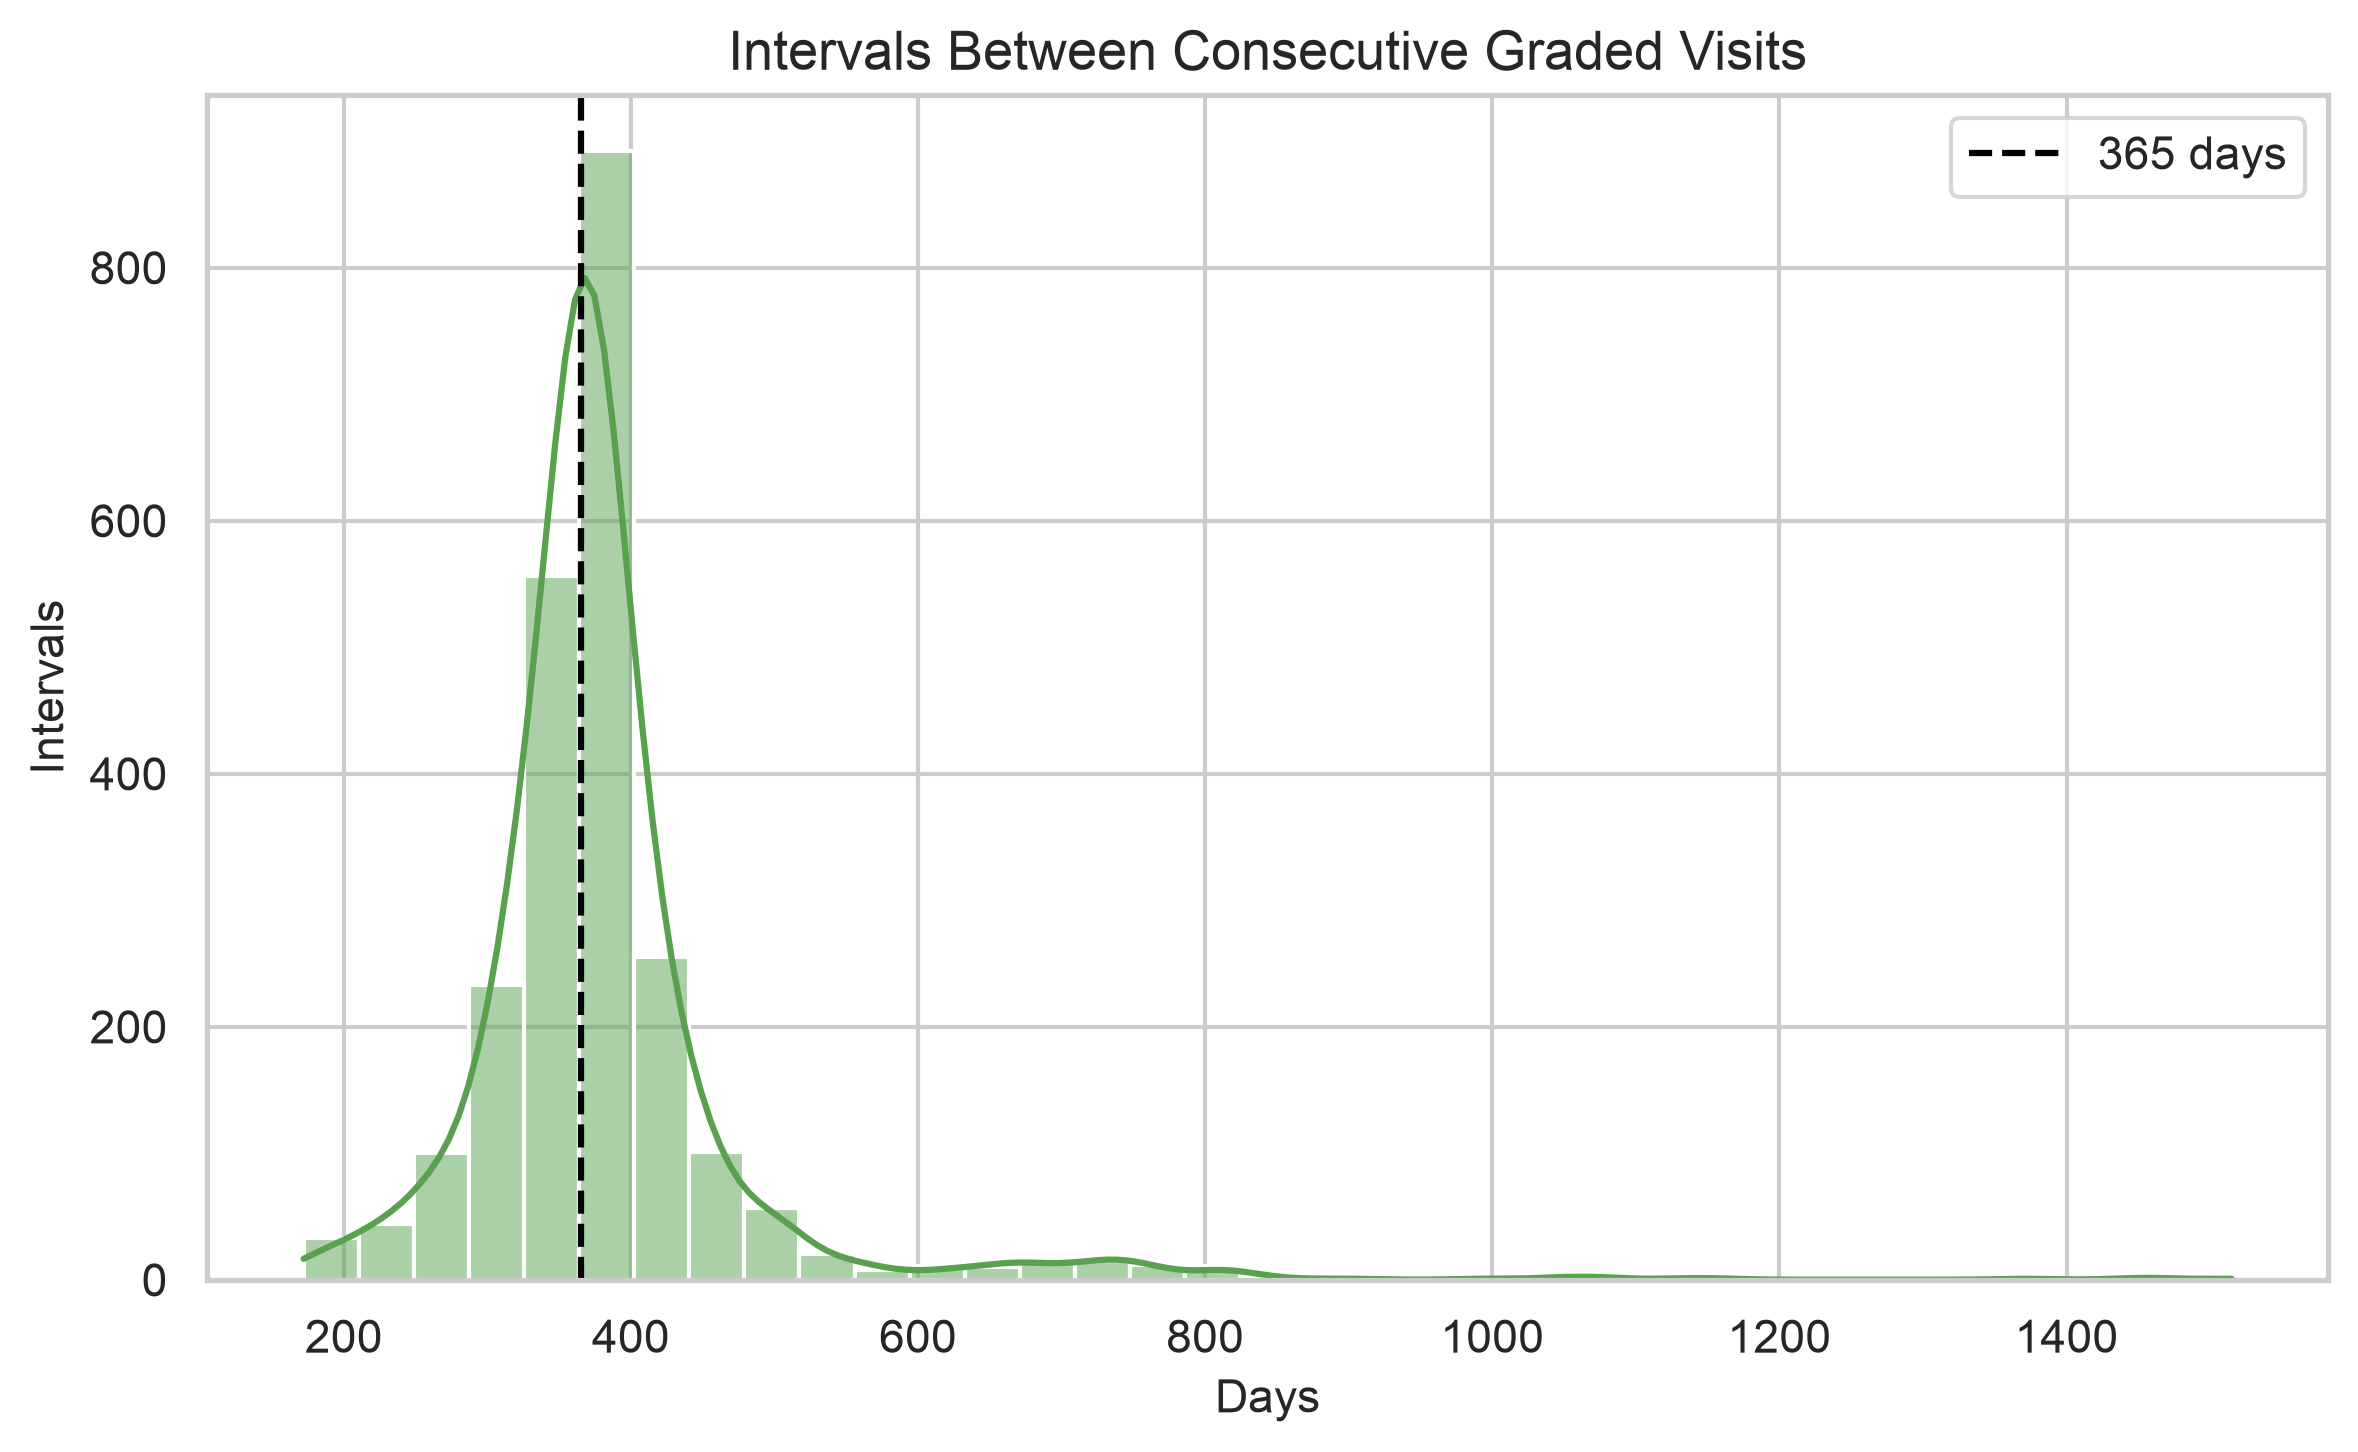

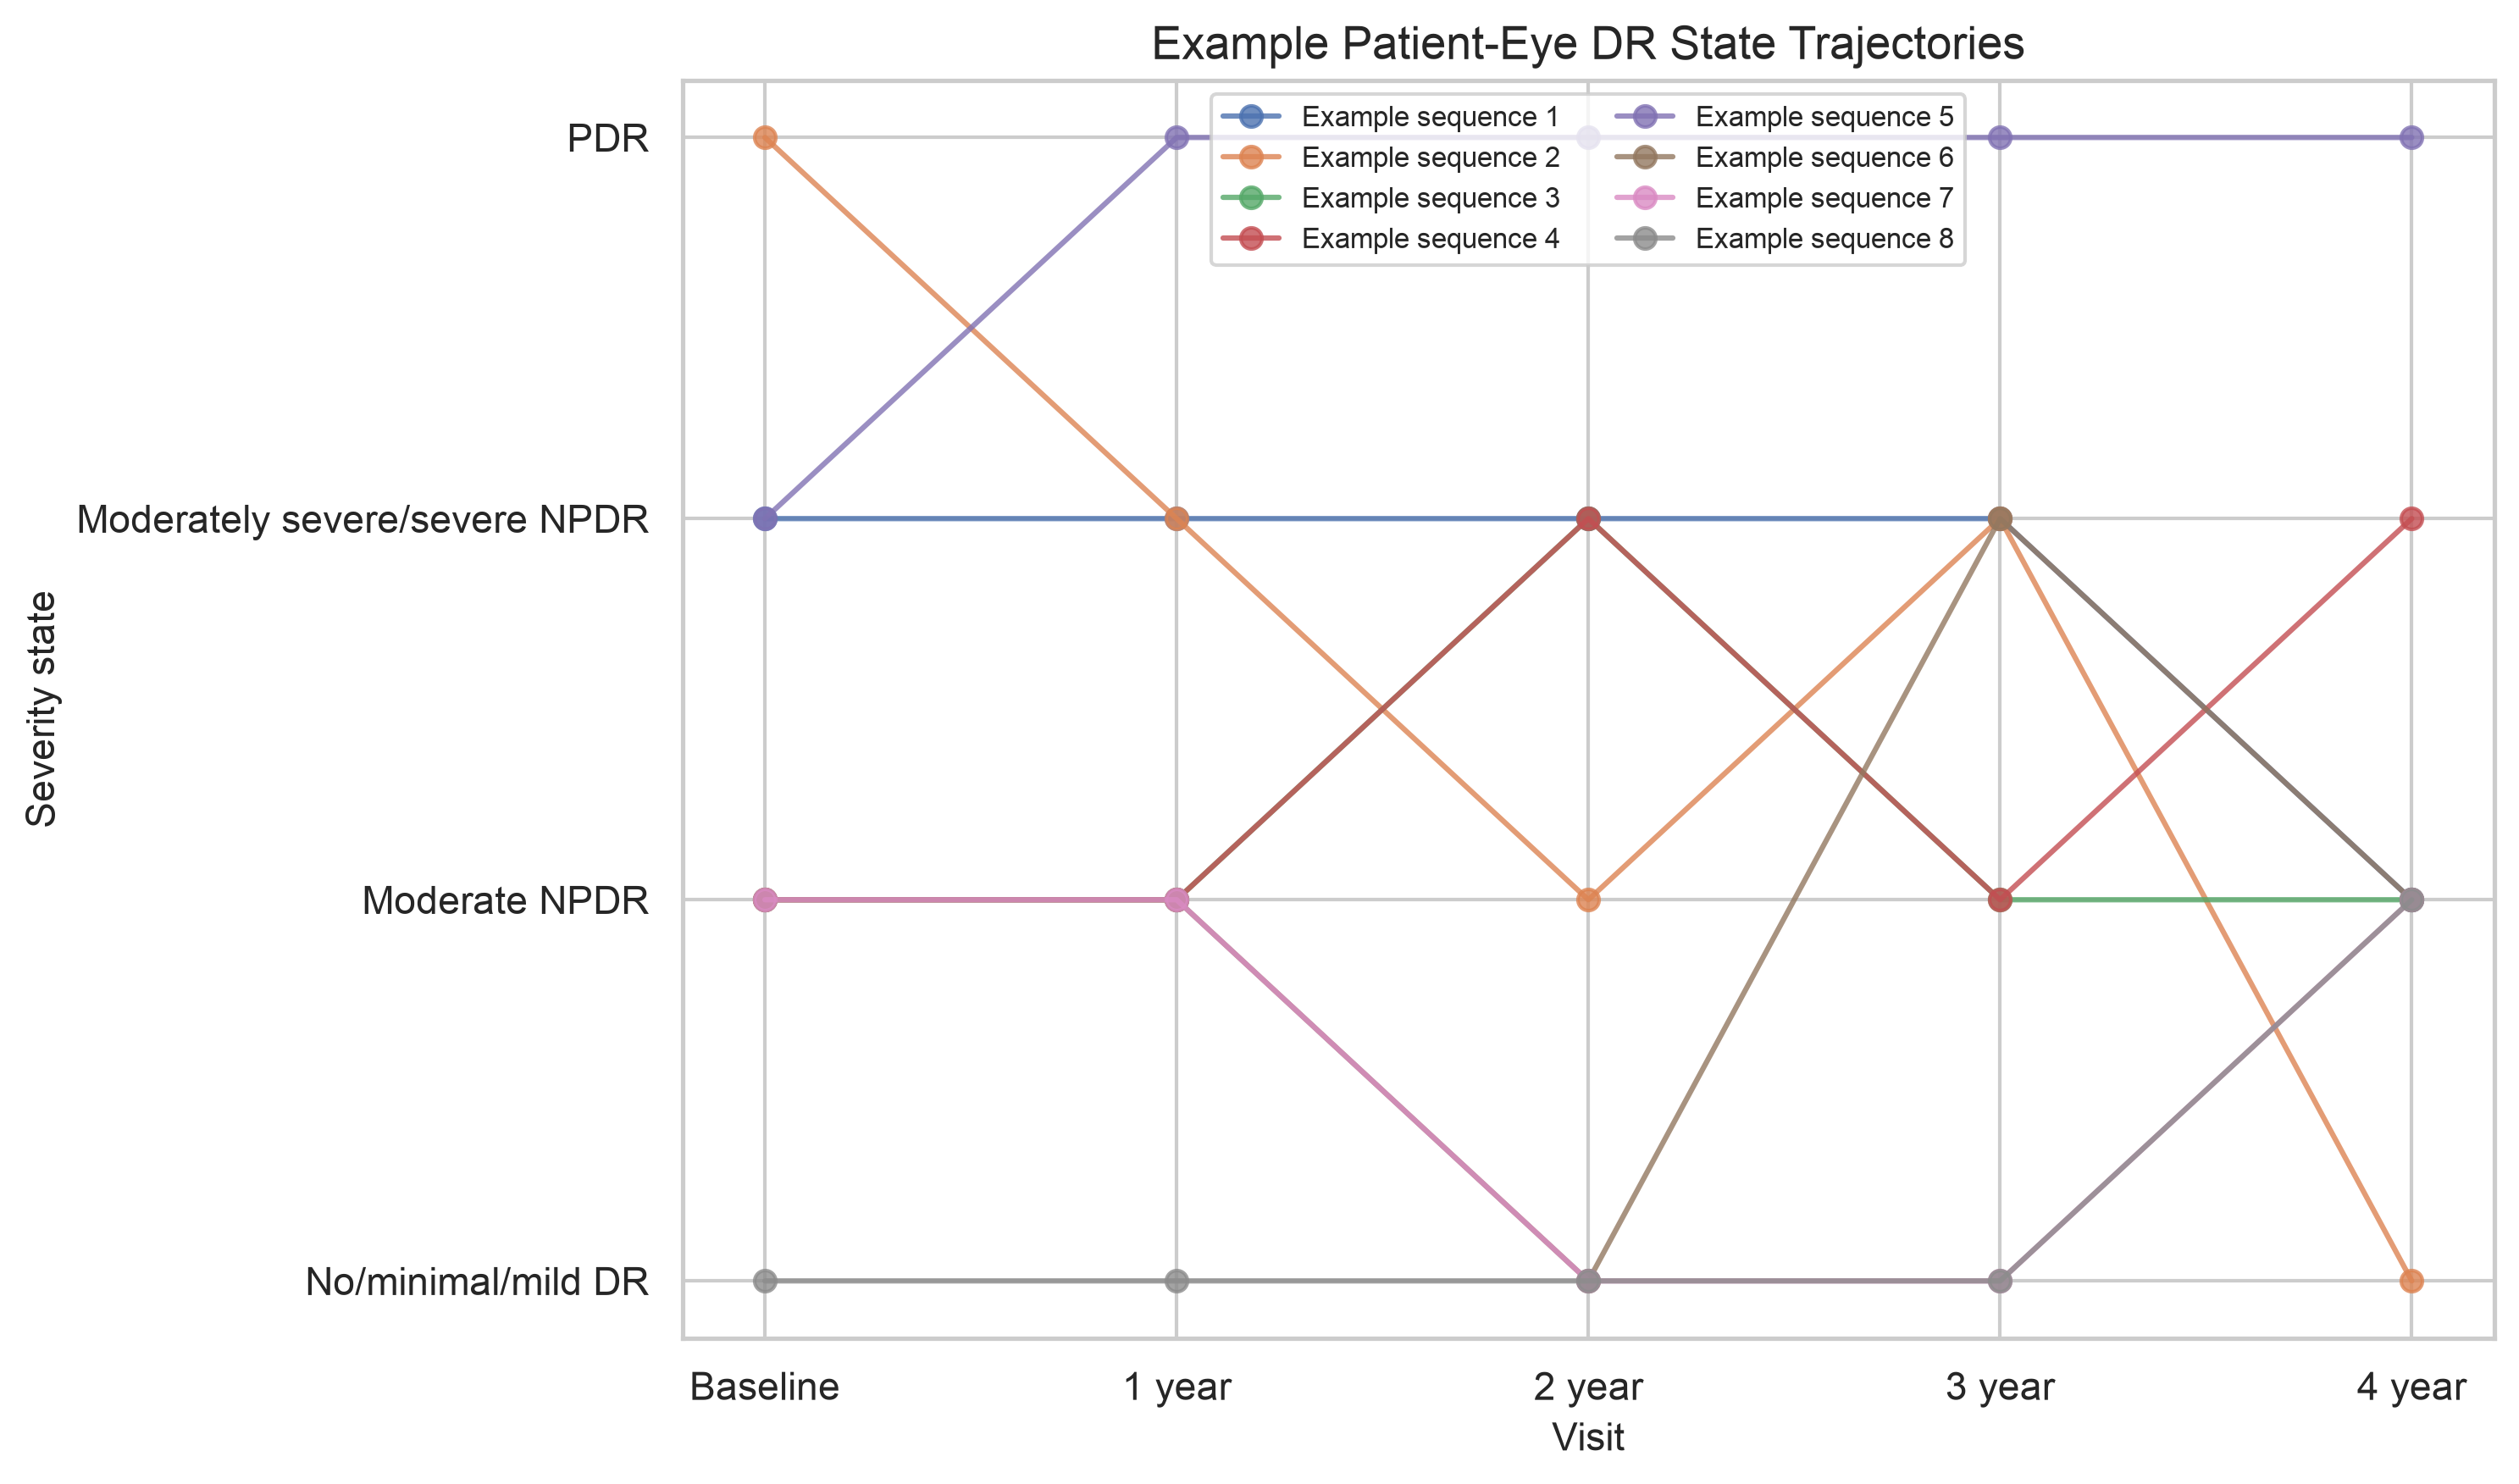

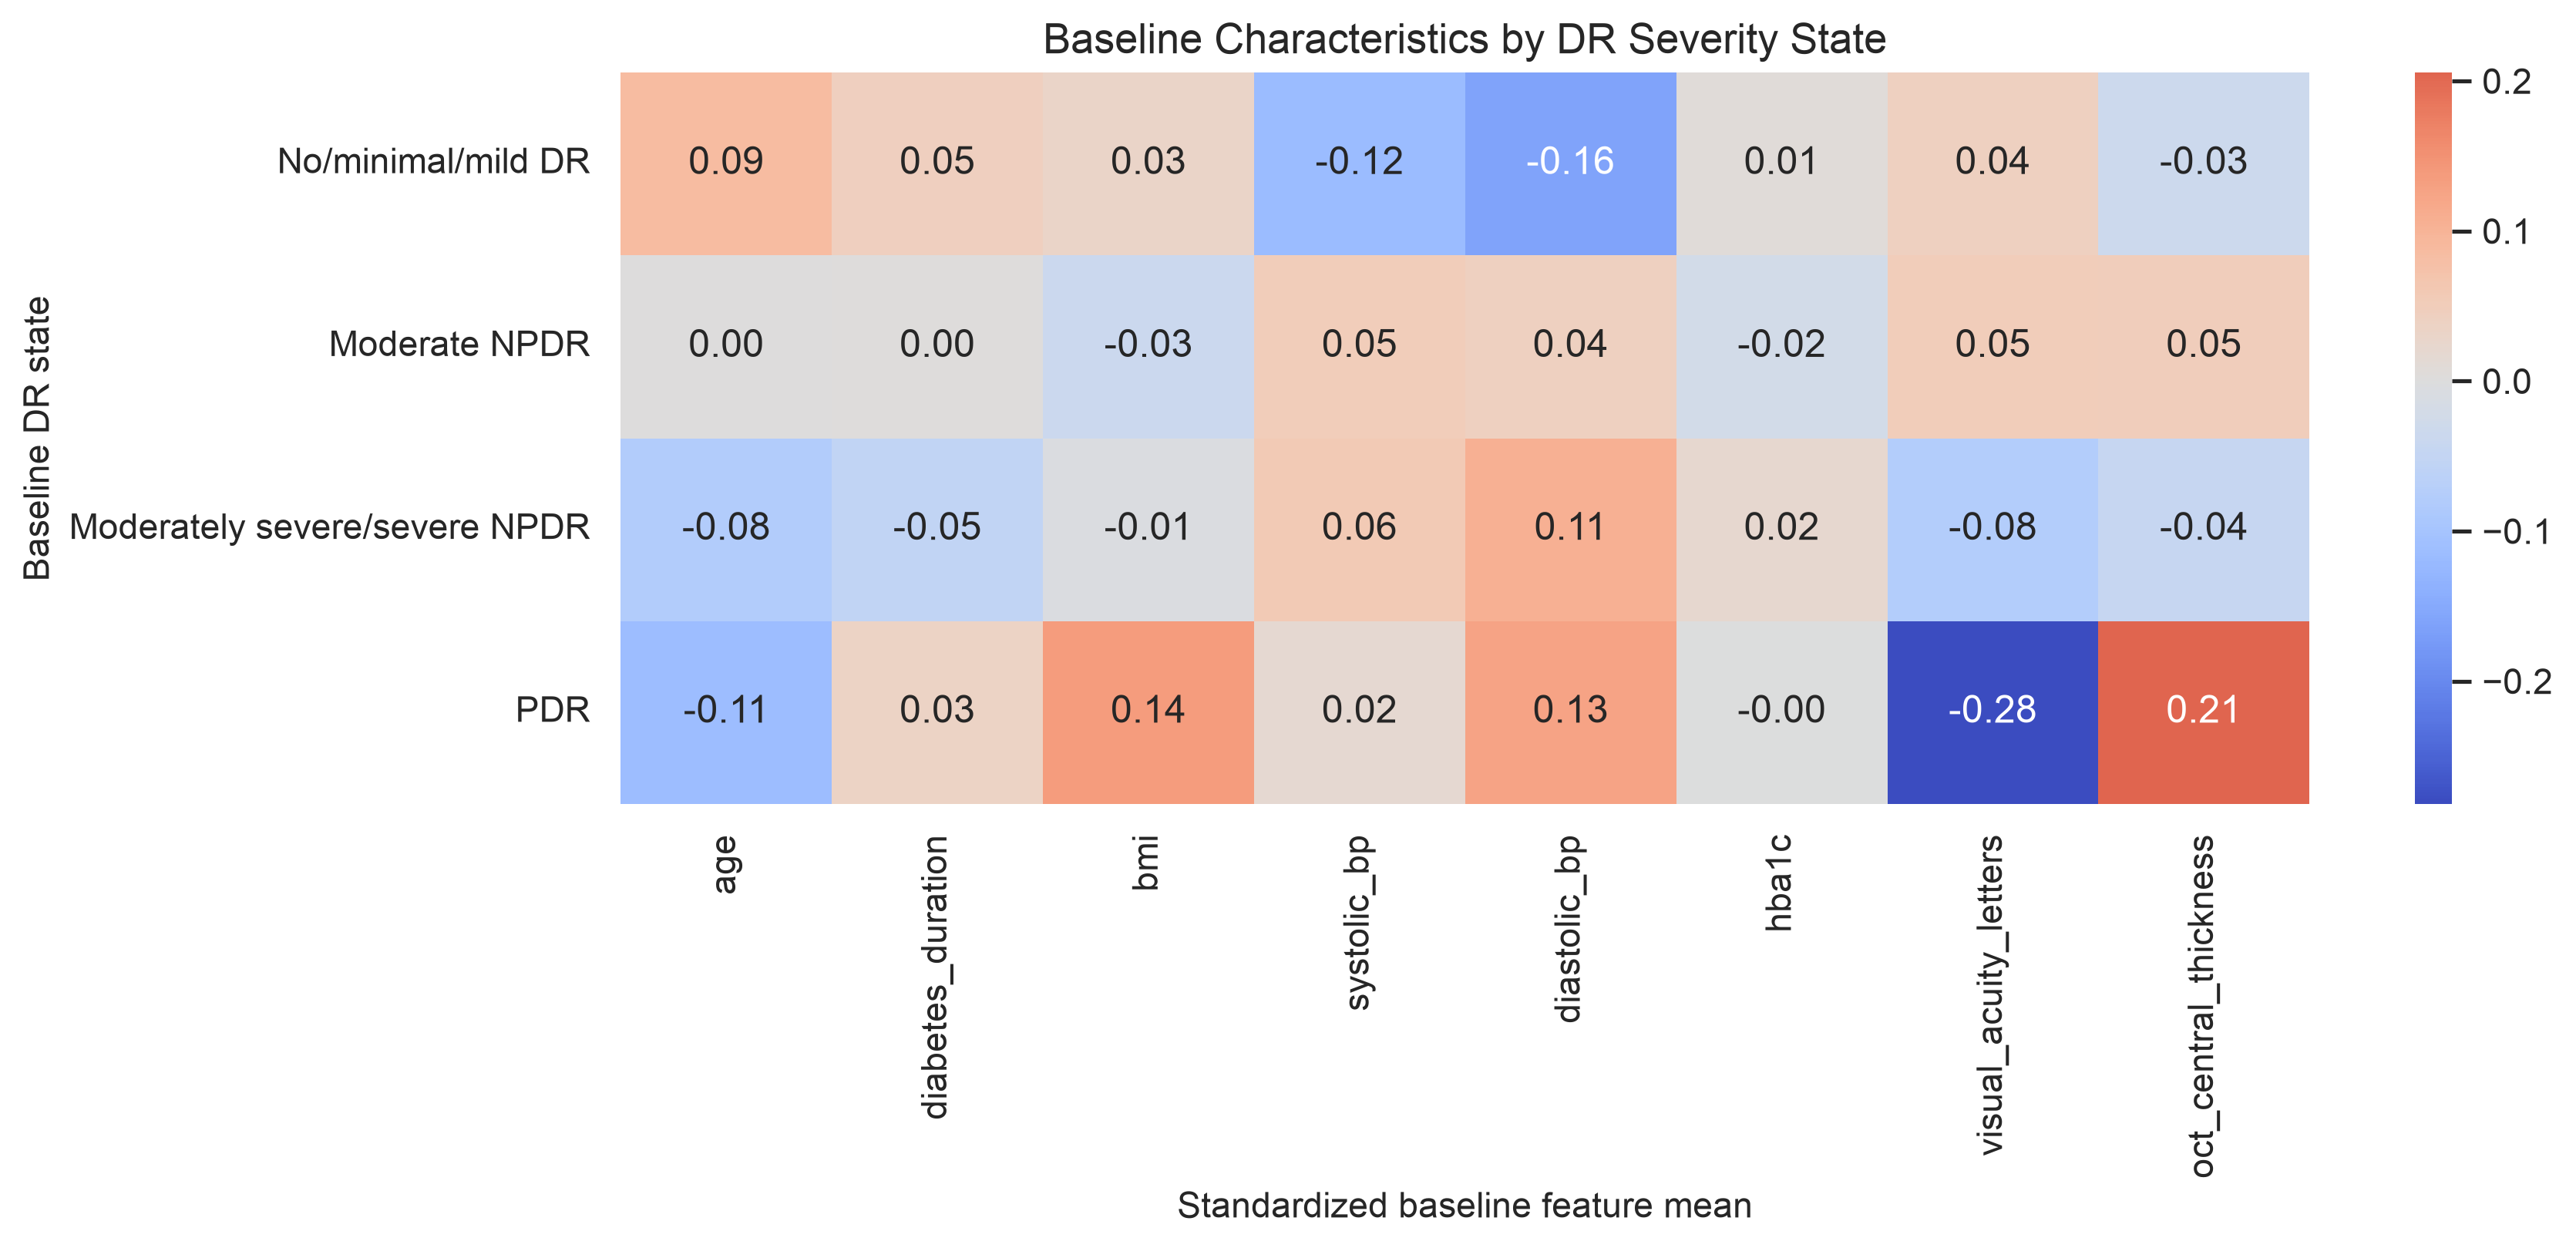

In [6]:
for name in [
    '01_baseline_feature_distributions.png','02_missingness_heatmap.png',
    '03_baseline_correlation.png','04_severity_distribution.png',
    '05_followup_retention.png','06_visit_intervals.png','07_example_trajectories.png',
    '24_baseline_characteristics_by_severity.png']:
    display(Image(filename=str(FIGURES / name)))

## 6. Unit 3 Problem Statement

**How do hierarchical and partitional clustering differ in identifying and evaluating feature-based patient-eye subgroups?** Severity is used only after clustering for interpretation.

In [7]:
evaluation = pd.read_csv(TABLES / 'clustering_evaluation.csv')
display(evaluation.sort_values('composite_score', ascending=False).head(12))

,method,linkage,k,inertia,silhouette,davies_bouldin,calinski_harabasz,minimum_cluster_size,minimum_cluster_fraction,cluster_sizes,stability_ari,rank_silhouette,rank_davies_bouldin,rank_calinski_harabasz,rank_stability_ari,composite_score
0,K-Means,not_applicable,2,5116.953280,0.133325,2.341602,118.448330,368,0.495957,368|374,0.863753,1.000000,0.528212,1.000000,1.000000,0.882053
2,K-Means,not_applicable,4,4236.658694,0.125781,1.924179,98.671616,166,0.223720,169|166|170|237,0.739721,0.848435,1.000000,0.604309,0.803499,0.814061
1,K-Means,not_applicable,3,4597.759519,0.121772,2.101403,107.548004,212,0.285714,212|268|262,0.740296,0.767890,0.799694,0.781907,0.804410,0.788475
11,Agglomerative,ward,6,NaN,0.090663,1.977319,68.468130,91,0.122642,235|91|113|96|115|92,0.318229,0.142860,0.939939,0.000000,0.135737,0.304634
10,Agglomerative,ward,5,NaN,0.093926,2.085668,70.729489,91,0.122642,205|91|235|96|115,0.288843,0.208424,0.817478,0.045245,0.089181,0.290082
9,Agglomerative,ward,4,NaN,0.090892,2.224039,74.288662,96,0.129380,206|205|235|96,0.268082,0.147455,0.661087,0.116457,0.056290,0.245322
7,Agglomerative,ward,2,NaN,0.098309,2.808948,78.856858,301,0.405660,441|301,0.279437,0.296465,0.000000,0.207857,0.074280,0.144650
8,Agglomerative,ward,3,NaN,0.083553,2.443900,74.813654,206,0.277628,301|206|235,0.232552,0.000000,0.412592,0.126961,0.000000,0.134888
3,K-Means,not_applicable,5,3950.897451,0.132138,1.772914,92.575206,20,0.026954,163|165|228|166|20,0.653337,NaN,NaN,NaN,NaN,NaN
4,K-Means,not_applicable,6,3690.297633,0.136947,1.661256,89.577433,21,0.028302,126|120|182|150|21|143,0.669568,NaN,NaN,NaN,NaN,NaN


## 7. Hierarchical Clustering Implementation

Ward, complete, and average linkage are evaluated. Solutions with clusters below 5% are ineligible because outlier clusters can inflate silhouette scores.

,method,linkage,k,inertia,silhouette,davies_bouldin,calinski_harabasz,minimum_cluster_size,minimum_cluster_fraction,cluster_sizes,stability_ari,rank_silhouette,rank_davies_bouldin,rank_calinski_harabasz,rank_stability_ari,composite_score
11,Agglomerative,ward,6,NaN,0.090663,1.977319,68.468130,91,0.122642,235|91|113|96|115|92,0.318229,0.142860,0.939939,0.000000,0.135737,0.304634
10,Agglomerative,ward,5,NaN,0.093926,2.085668,70.729489,91,0.122642,205|91|235|96|115,0.288843,0.208424,0.817478,0.045245,0.089181,0.290082
9,Agglomerative,ward,4,NaN,0.090892,2.224039,74.288662,96,0.129380,206|205|235|96,0.268082,0.147455,0.661087,0.116457,0.056290,0.245322
7,Agglomerative,ward,2,NaN,0.098309,2.808948,78.856858,301,0.405660,441|301,0.279437,0.296465,0.000000,0.207857,0.074280,0.144650
8,Agglomerative,ward,3,NaN,0.083553,2.443900,74.813654,206,0.277628,301|206|235,0.232552,0.000000,0.412592,0.126961,0.000000,0.134888
12,Agglomerative,complete,2,NaN,0.530048,0.781486,40.173809,6,0.008086,736|6,0.764585,NaN,NaN,NaN,NaN,NaN
13,Agglomerative,complete,3,NaN,0.115425,2.034543,57.629838,6,0.008086,557|6|179,0.191266,NaN,NaN,NaN,NaN,NaN
14,Agglomerative,complete,4,NaN,0.119840,1.772520,47.884243,6,0.008086,548|6|179|9,0.230738,NaN,NaN,NaN,NaN,NaN
15,Agglomerative,complete,5,NaN,0.079215,2.158675,45.132277,6,0.008086,447|101|179|9|6,0.234994,NaN,NaN,NaN,NaN,NaN
16,Agglomerative,complete,6,NaN,0.081060,1.981152,43.796680,6,0.008086,179|101|432|9|6|15,0.228035,NaN,NaN,NaN,NaN,NaN


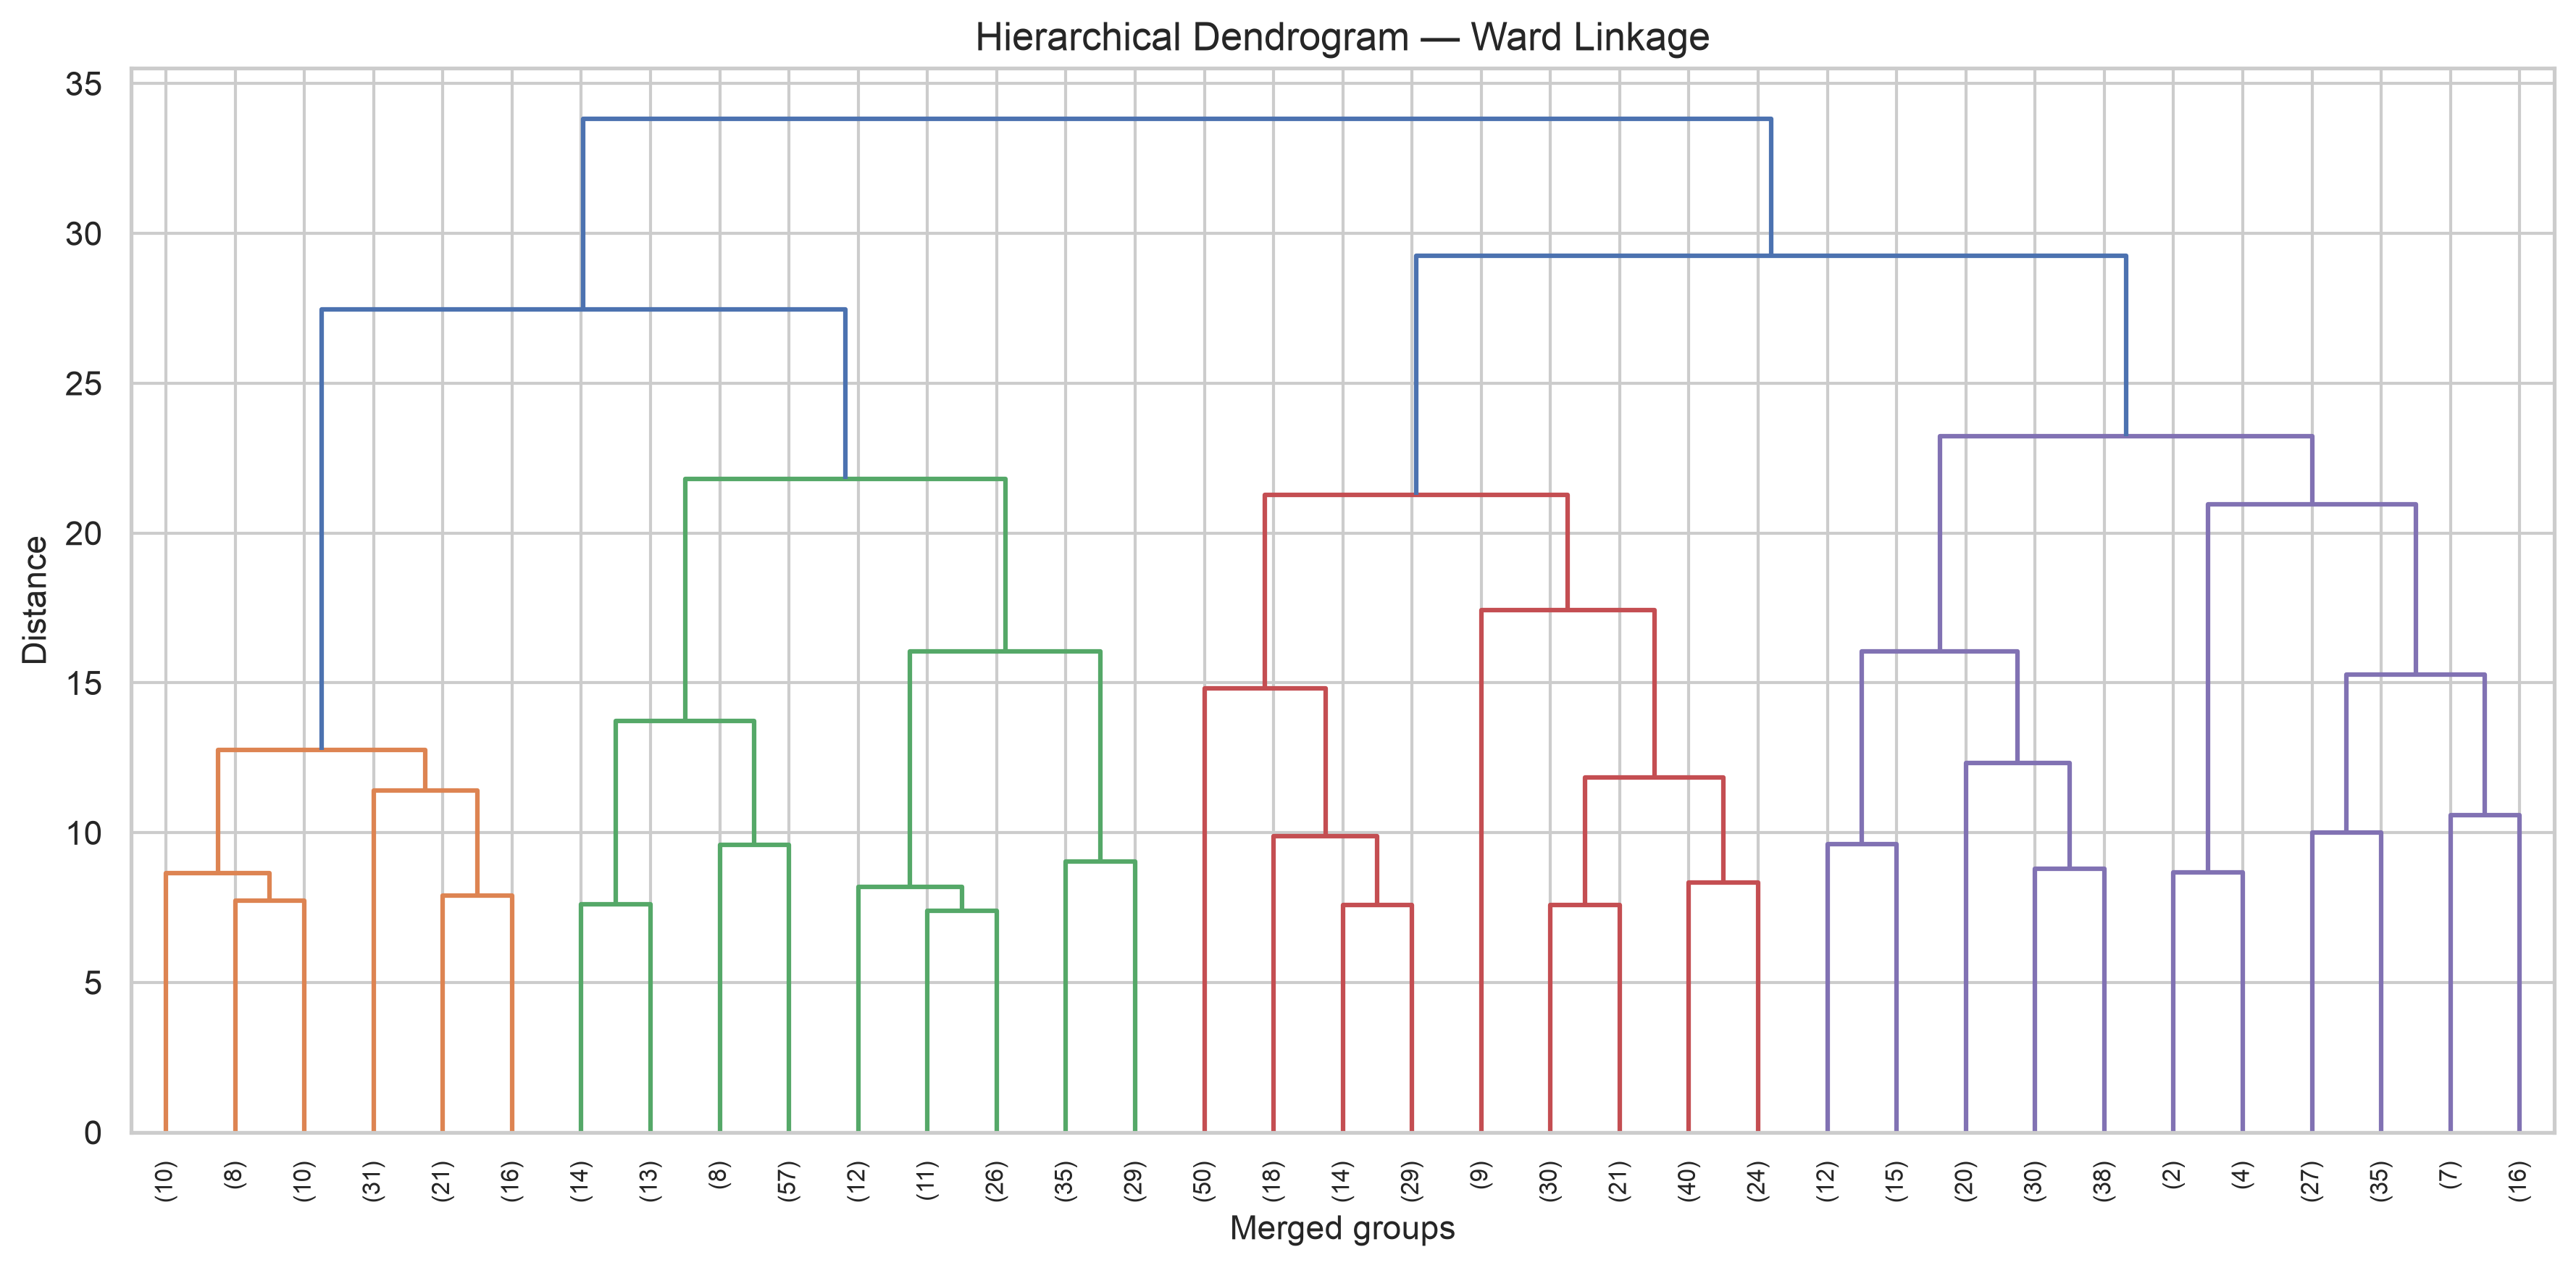

In [8]:
hier = evaluation[evaluation.method.eq('Agglomerative')]
display(hier.sort_values('composite_score', ascending=False))
display(Image(filename=str(FIGURES / '10_hierarchical_dendrogram.png')))

## 8. K-Means Implementation

K-Means uses standardized, median-imputed baseline features, 50 initializations, and random state 42. K=2–8 is evaluated.

,method,linkage,k,inertia,silhouette,davies_bouldin,calinski_harabasz,minimum_cluster_size,minimum_cluster_fraction,cluster_sizes,stability_ari,rank_silhouette,rank_davies_bouldin,rank_calinski_harabasz,rank_stability_ari,composite_score
0,K-Means,not_applicable,2,5116.953280,0.133325,2.341602,118.448330,368,0.495957,368|374,0.863753,1.000000,0.528212,1.000000,1.000000,0.882053
1,K-Means,not_applicable,3,4597.759519,0.121772,2.101403,107.548004,212,0.285714,212|268|262,0.740296,0.767890,0.799694,0.781907,0.804410,0.788475
2,K-Means,not_applicable,4,4236.658694,0.125781,1.924179,98.671616,166,0.223720,169|166|170|237,0.739721,0.848435,1.000000,0.604309,0.803499,0.814061
3,K-Means,not_applicable,5,3950.897451,0.132138,1.772914,92.575206,20,0.026954,163|165|228|166|20,0.653337,NaN,NaN,NaN,NaN,NaN
4,K-Means,not_applicable,6,3690.297633,0.136947,1.661256,89.577433,21,0.028302,126|120|182|150|21|143,0.669568,NaN,NaN,NaN,NaN,NaN
5,K-Means,not_applicable,7,3468.626075,0.136045,1.619878,87.139201,12,0.016173,112|106|135|162|12|108|107,0.778805,NaN,NaN,NaN,NaN,NaN
6,K-Means,not_applicable,8,3320.434014,0.130587,1.659718,82.597870,18,0.024259,93|18|101|123|120|102|82|103,0.623780,NaN,NaN,NaN,NaN,NaN


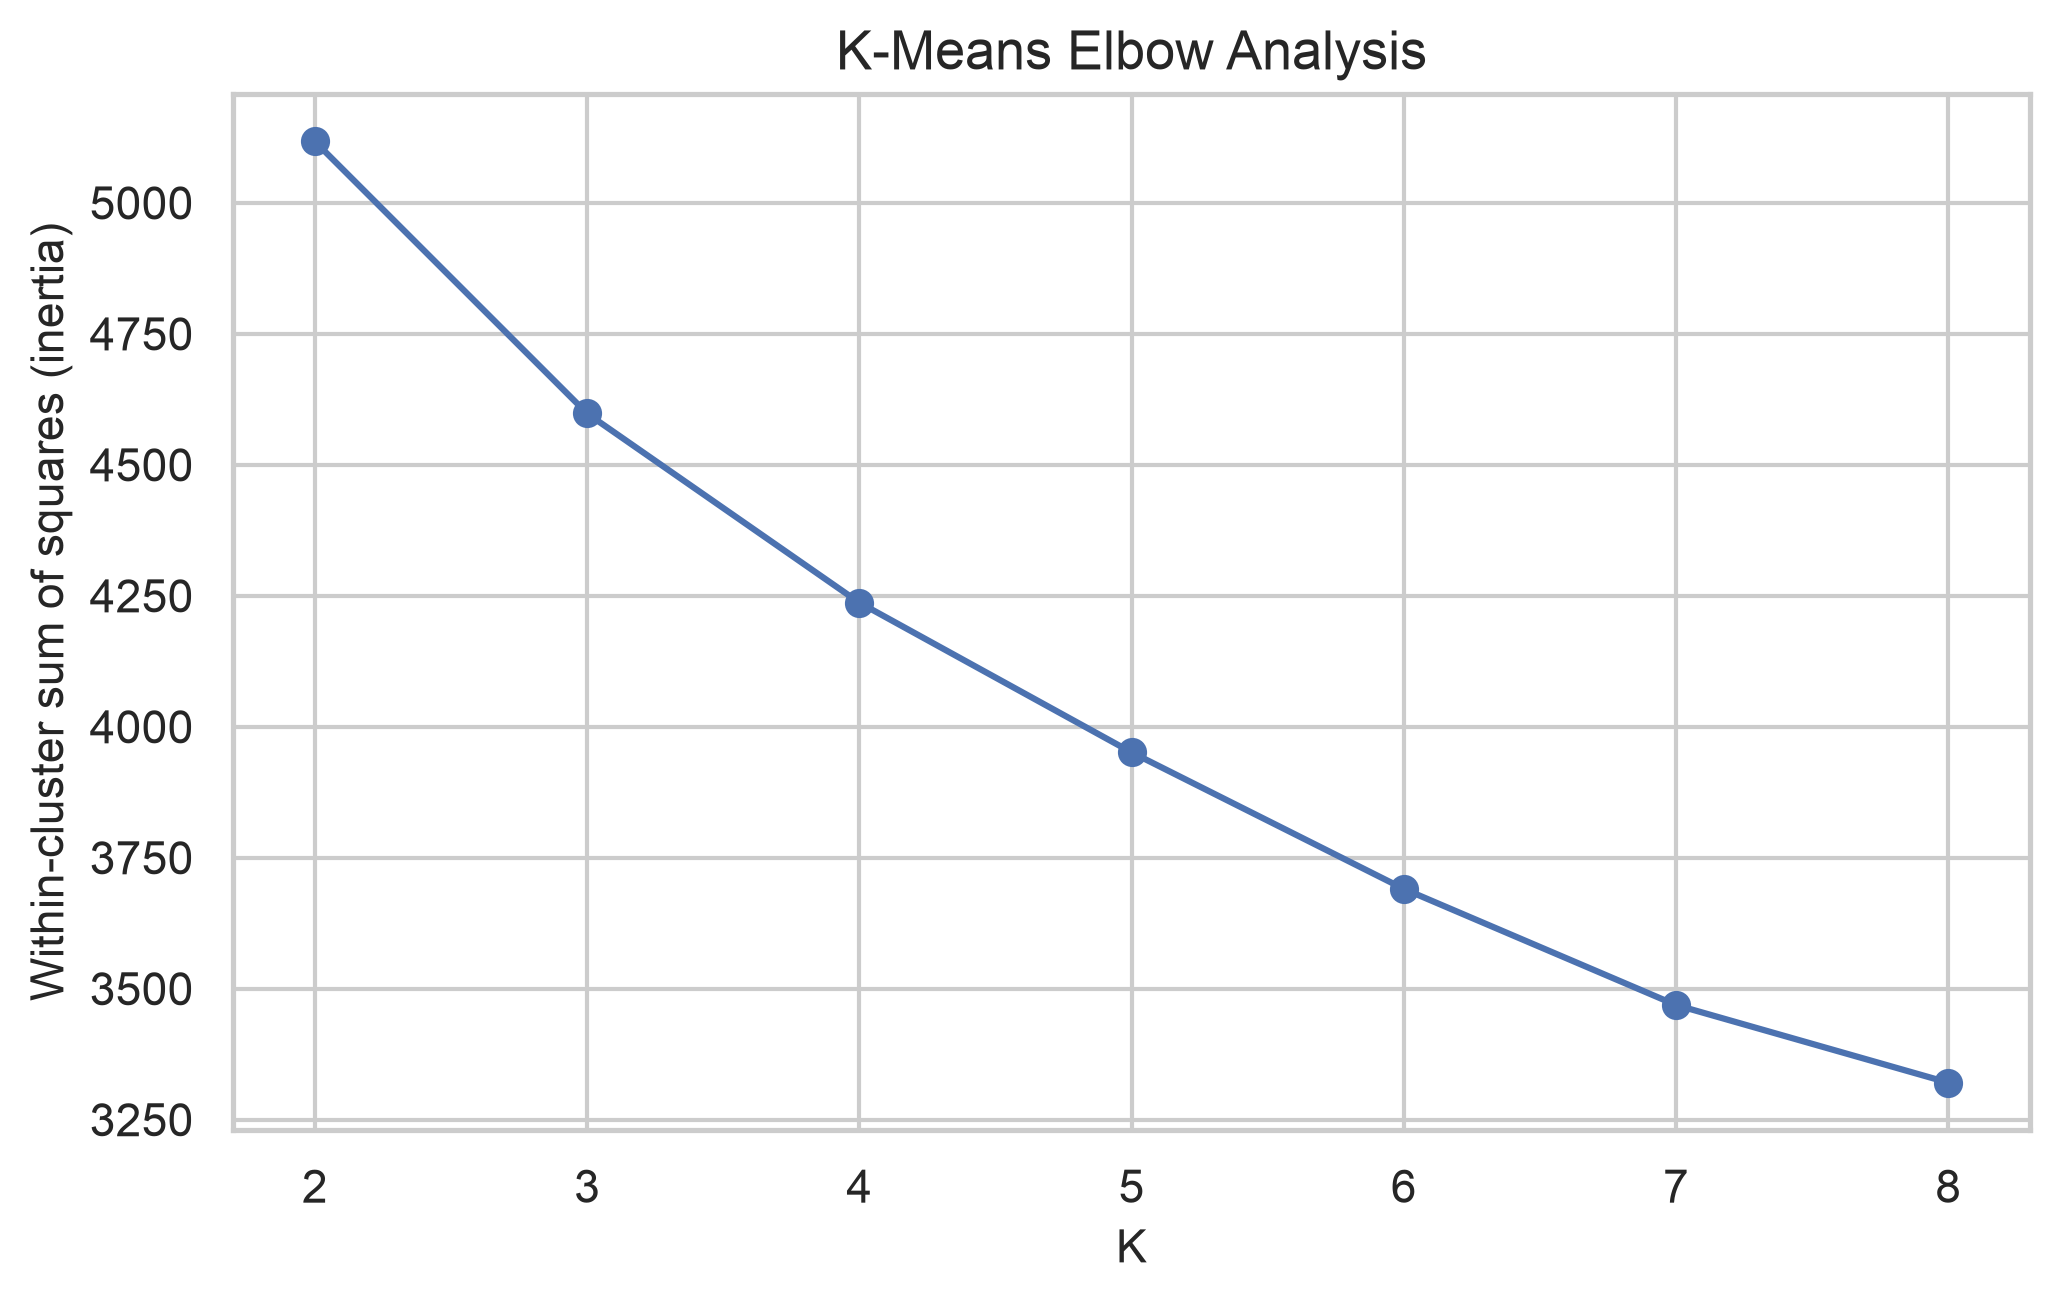

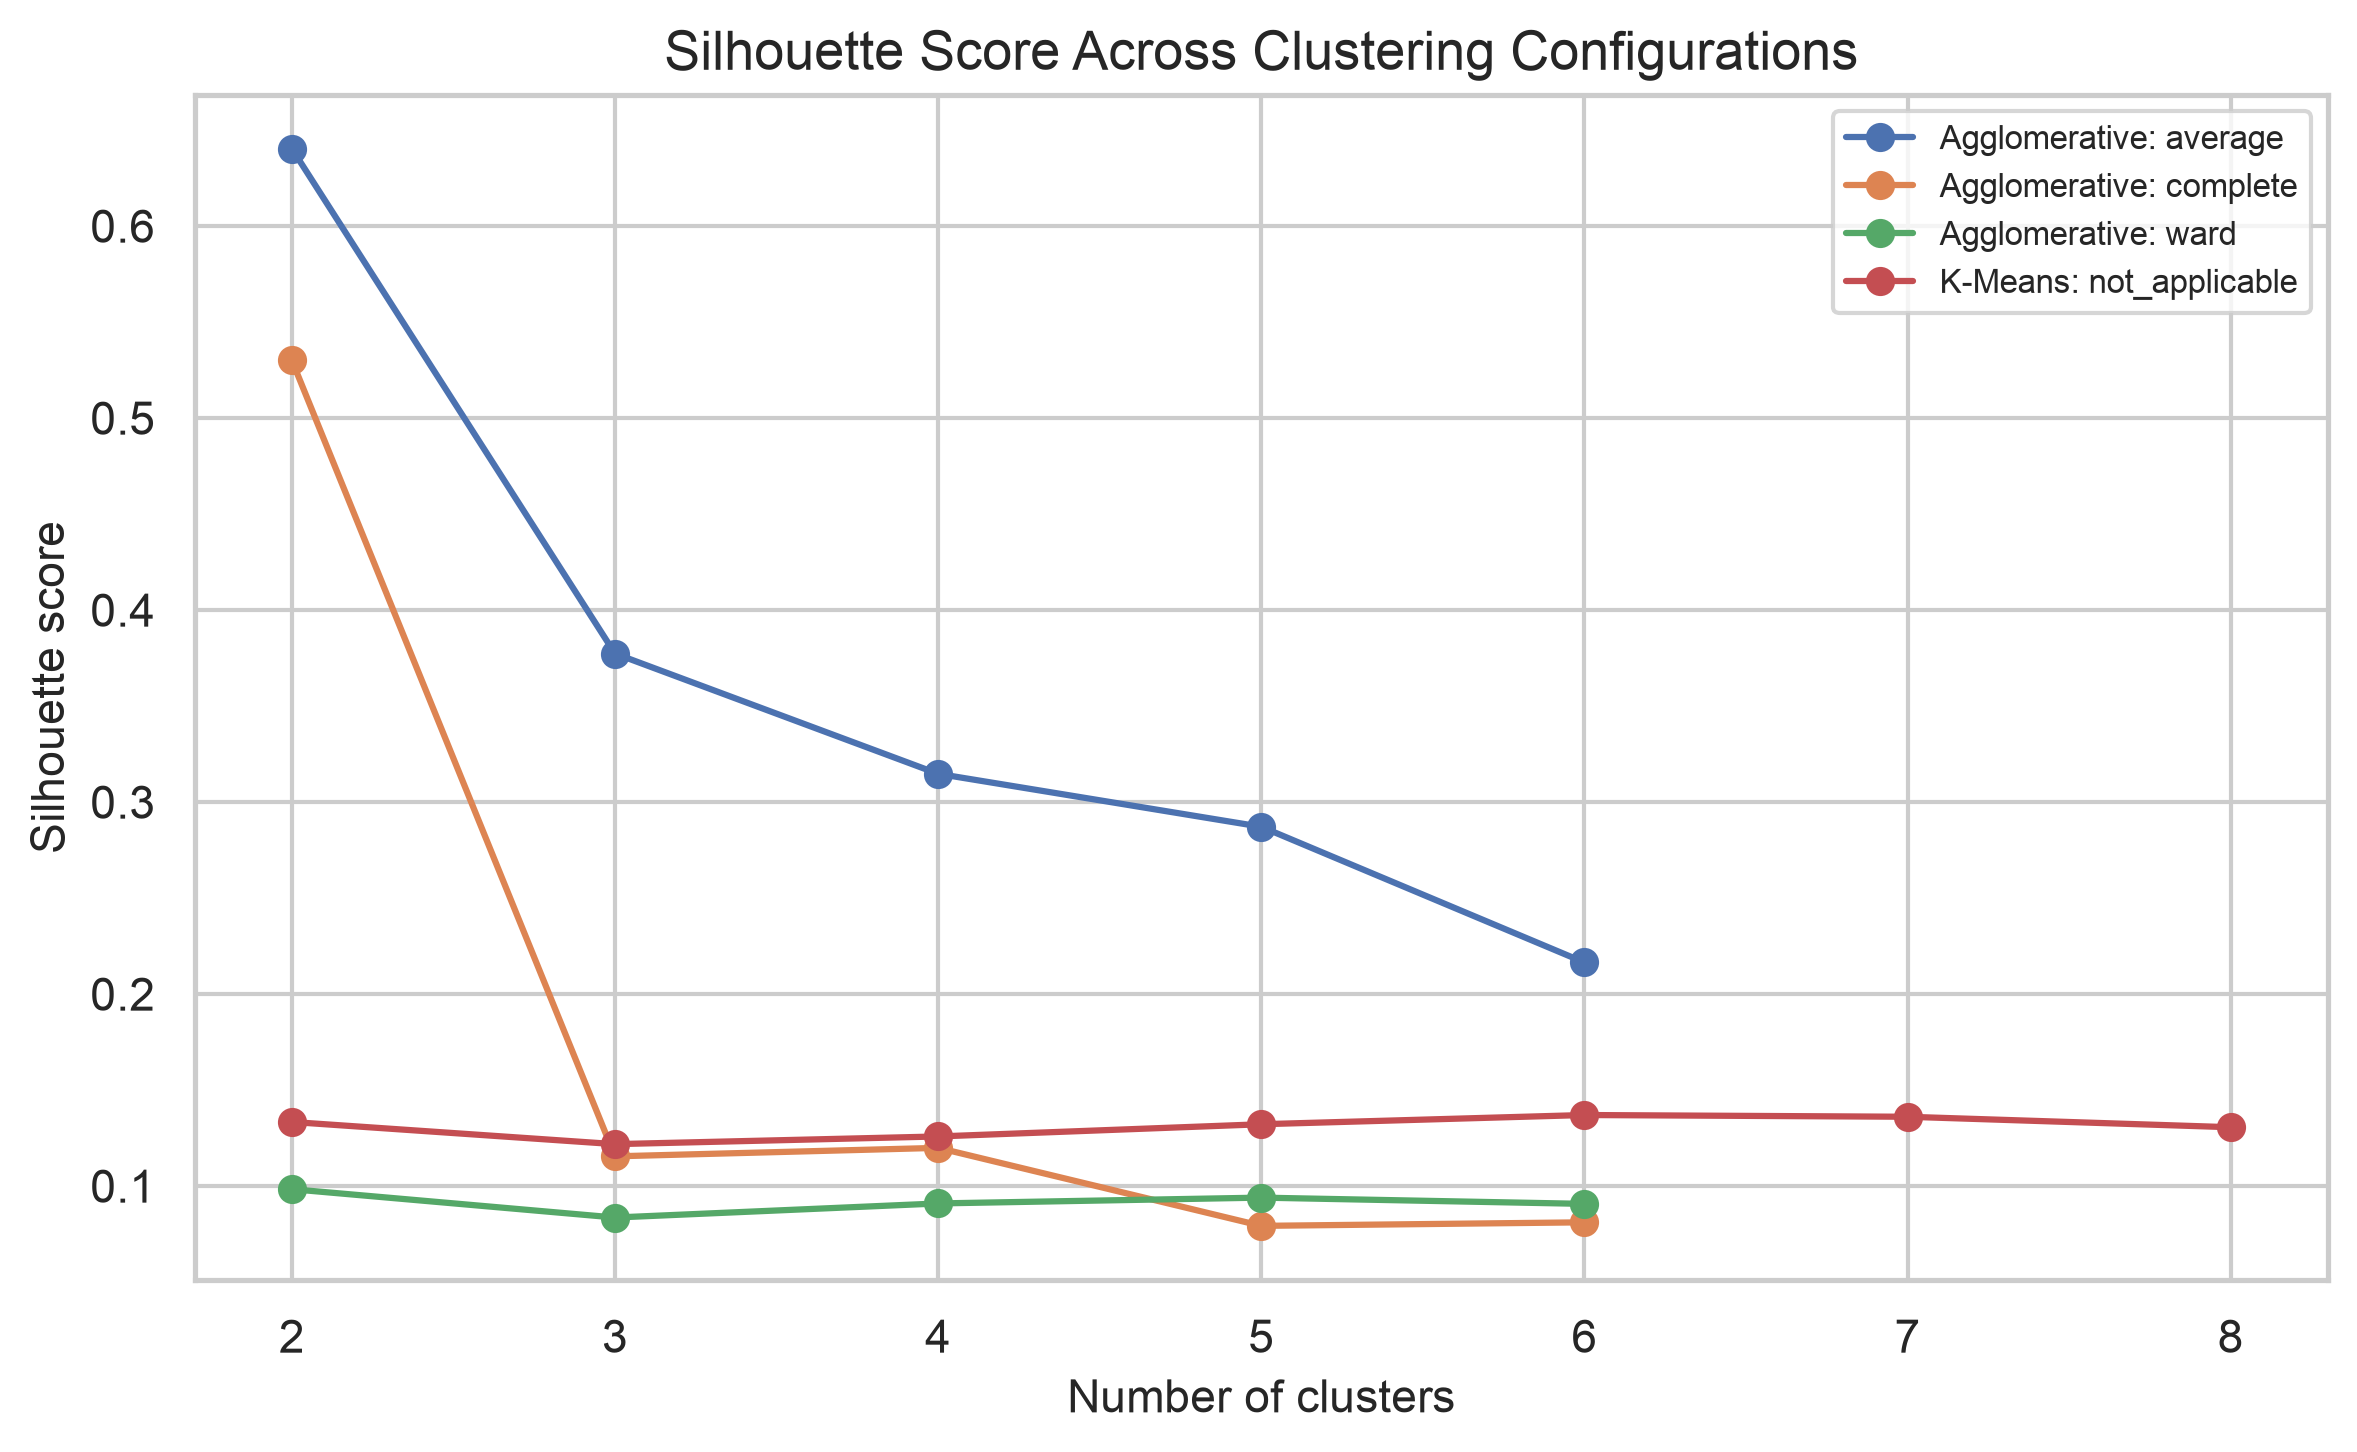

In [9]:
km = evaluation[evaluation.method.eq('K-Means')]
display(km)
display(Image(filename=str(FIGURES / '08_kmeans_elbow.png')))
display(Image(filename=str(FIGURES / '09_silhouette_comparison.png')))

## 9. Clustering Evaluation and Interpretation

,cluster,method,age,diabetes_duration,bmi,systolic_bp,diastolic_bp,hba1c,visual_acuity_letters,oct_central_thickness
0,0,K-Means,67.510870,24.959239,31.459595,131.885870,74.149457,7.448753,81.013587,264.845109
1,1,K-Means,53.358289,16.066845,34.244425,138.347594,84.868984,8.967209,85.708556,272.841823
2,0,Agglomerative,57.131915,14.097872,29.982847,124.872340,77.404255,7.415517,84.514894,281.778723
3,1,Agglomerative,64.021978,27.934066,33.476025,136.120879,78.065934,8.288235,74.890110,225.692308
4,2,Agglomerative,51.327434,16.044248,34.117523,135.300885,85.814159,10.689381,84.230088,258.839286
5,3,Agglomerative,66.500000,21.687500,29.784255,165.593750,89.197917,7.968750,83.572917,275.927083
6,4,Agglomerative,68.217391,32.765217,29.883049,126.478261,69.182609,7.379130,84.756522,279.095652
7,5,Agglomerative,59.989130,18.217391,43.879418,139.271739,81.717391,8.443820,85.913043,270.673913


,cluster,severity_state,proportion,method
0,0,Moderate NPDR,0.353261,K-Means
1,1,Moderate NPDR,0.363636,K-Means
2,0,Moderately severe/severe NPDR,0.263587,K-Means
3,1,Moderately severe/severe NPDR,0.331551,K-Means
4,0,No/minimal/mild DR,0.347826,K-Means
5,1,No/minimal/mild DR,0.278075,K-Means
6,0,PDR,0.035326,K-Means
7,1,PDR,0.026738,K-Means
8,0,Moderate NPDR,0.382979,Agglomerative
9,1,Moderate NPDR,0.296703,Agglomerative


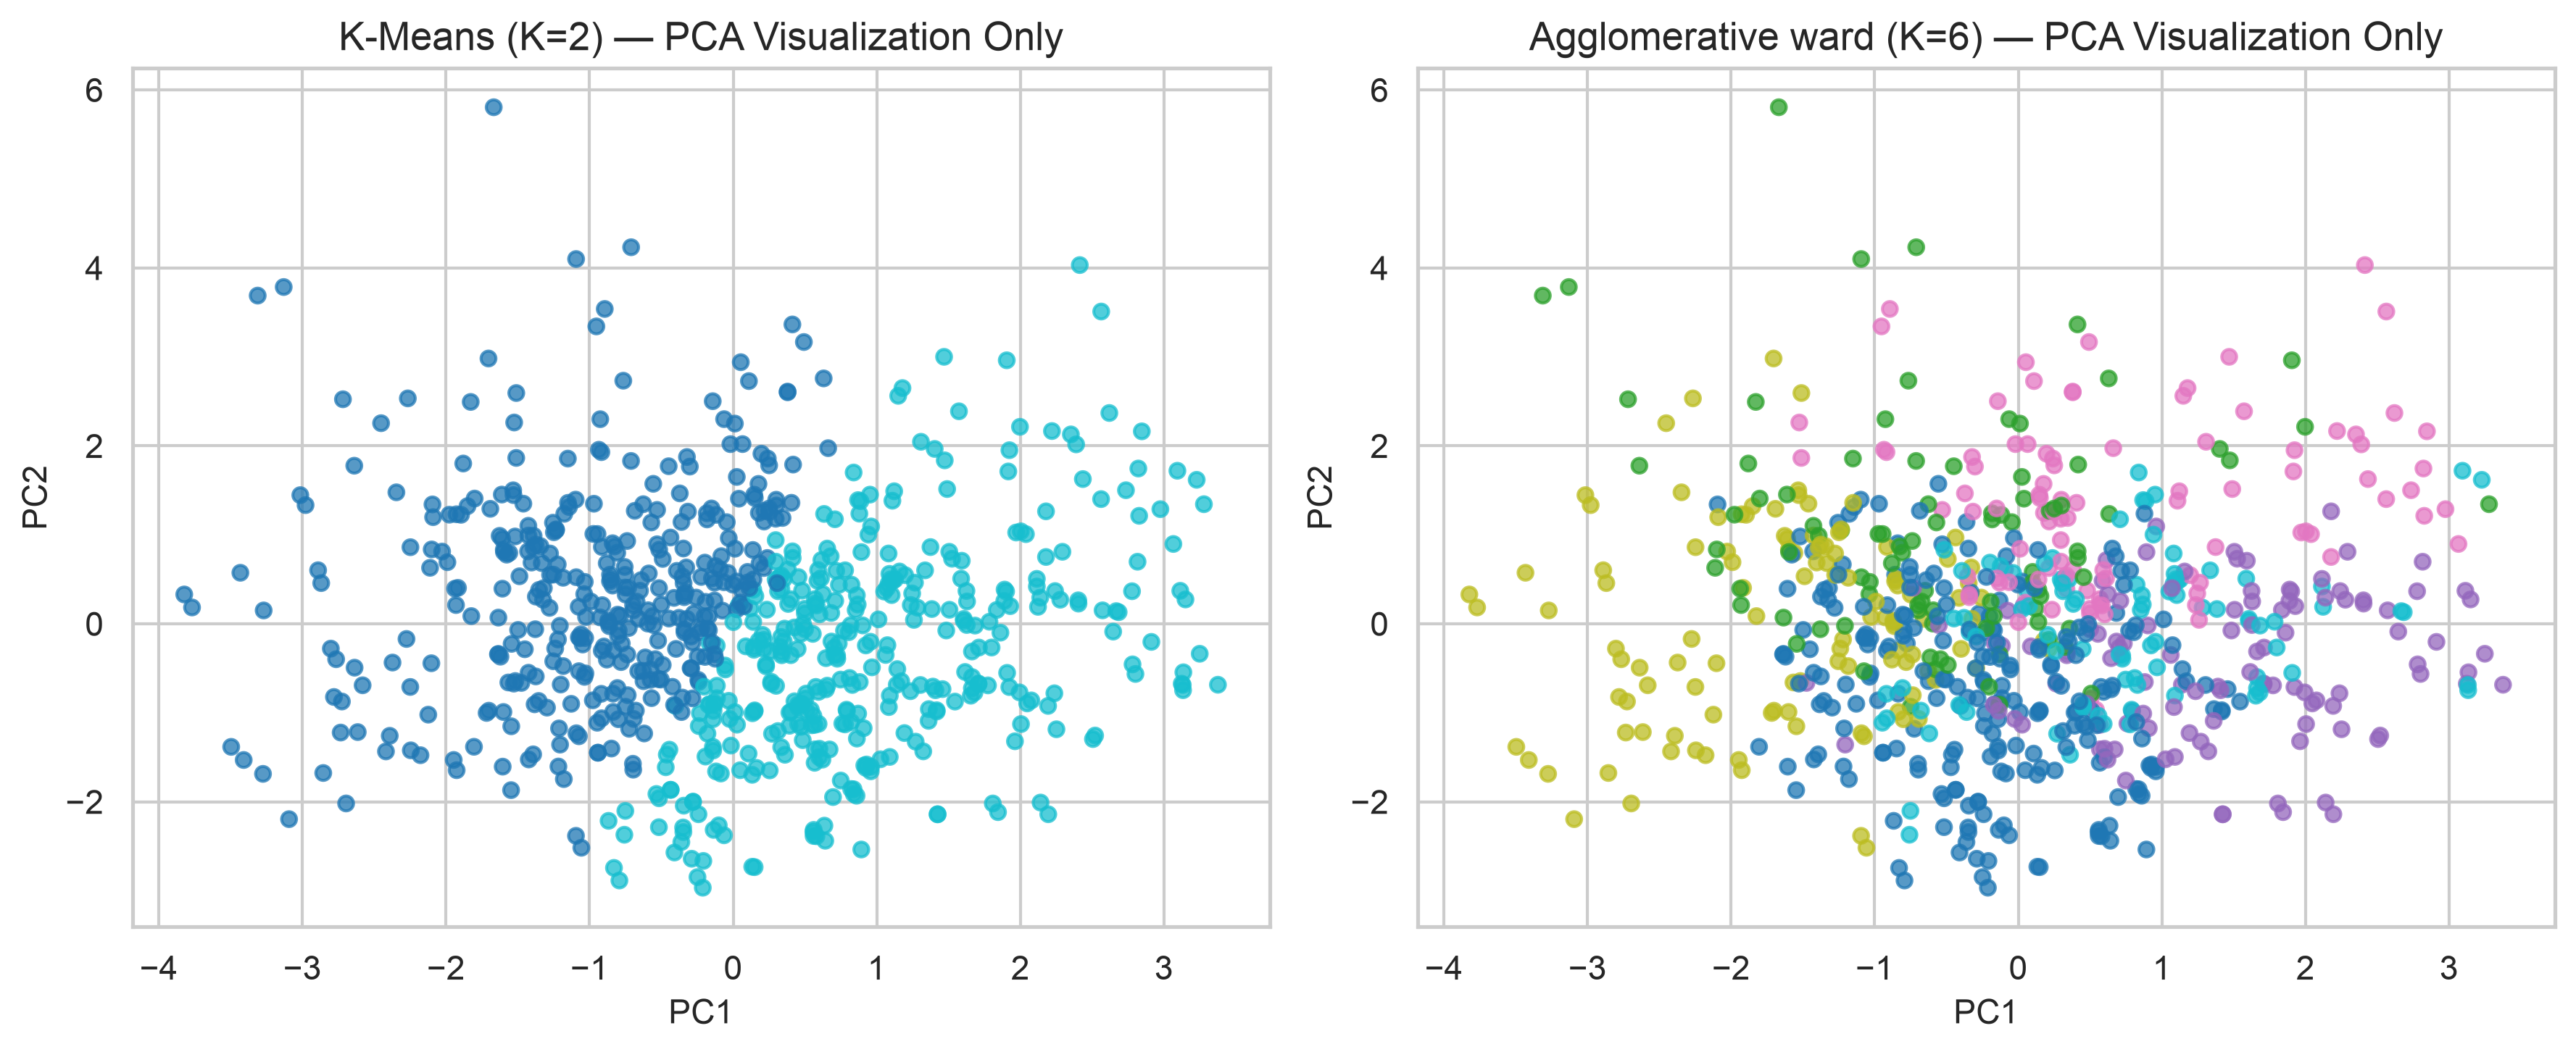

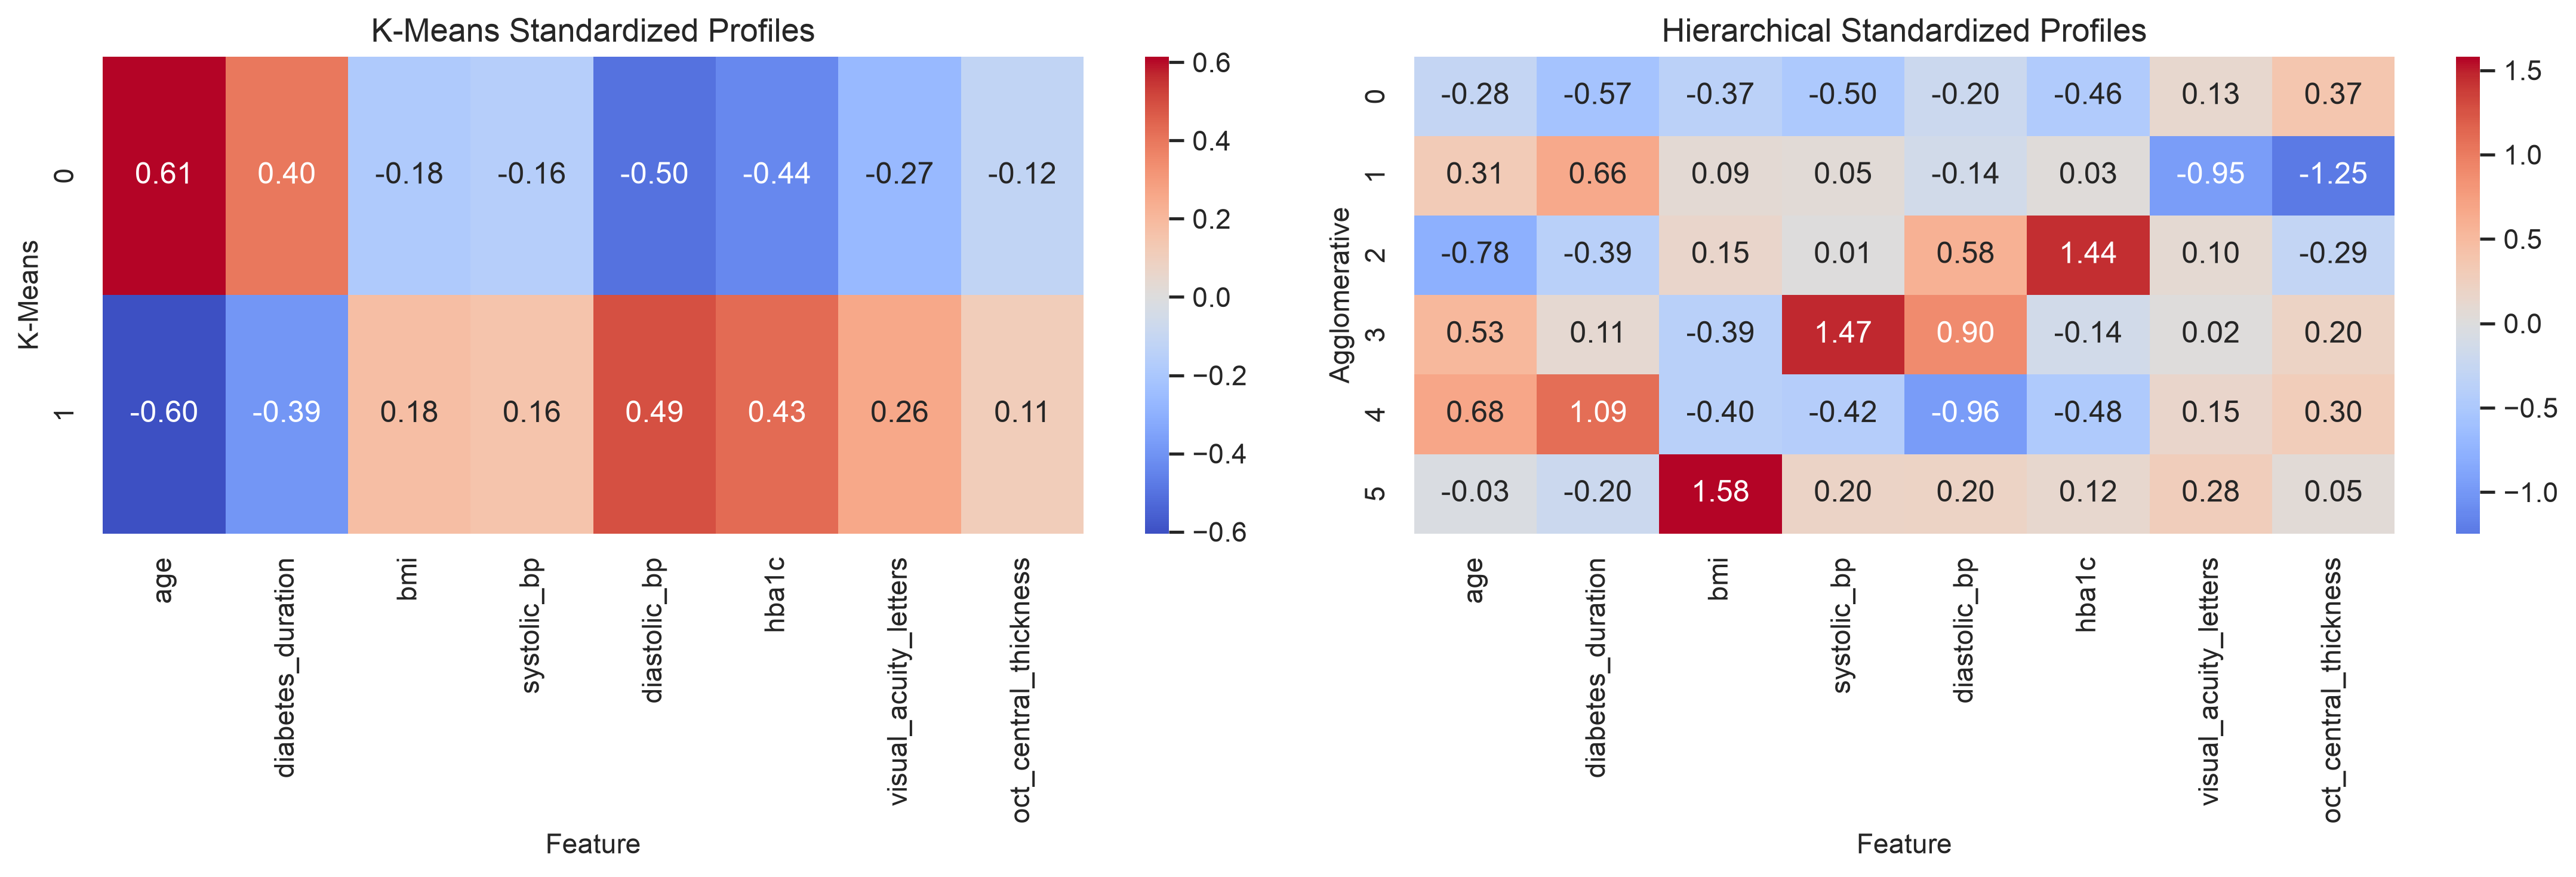

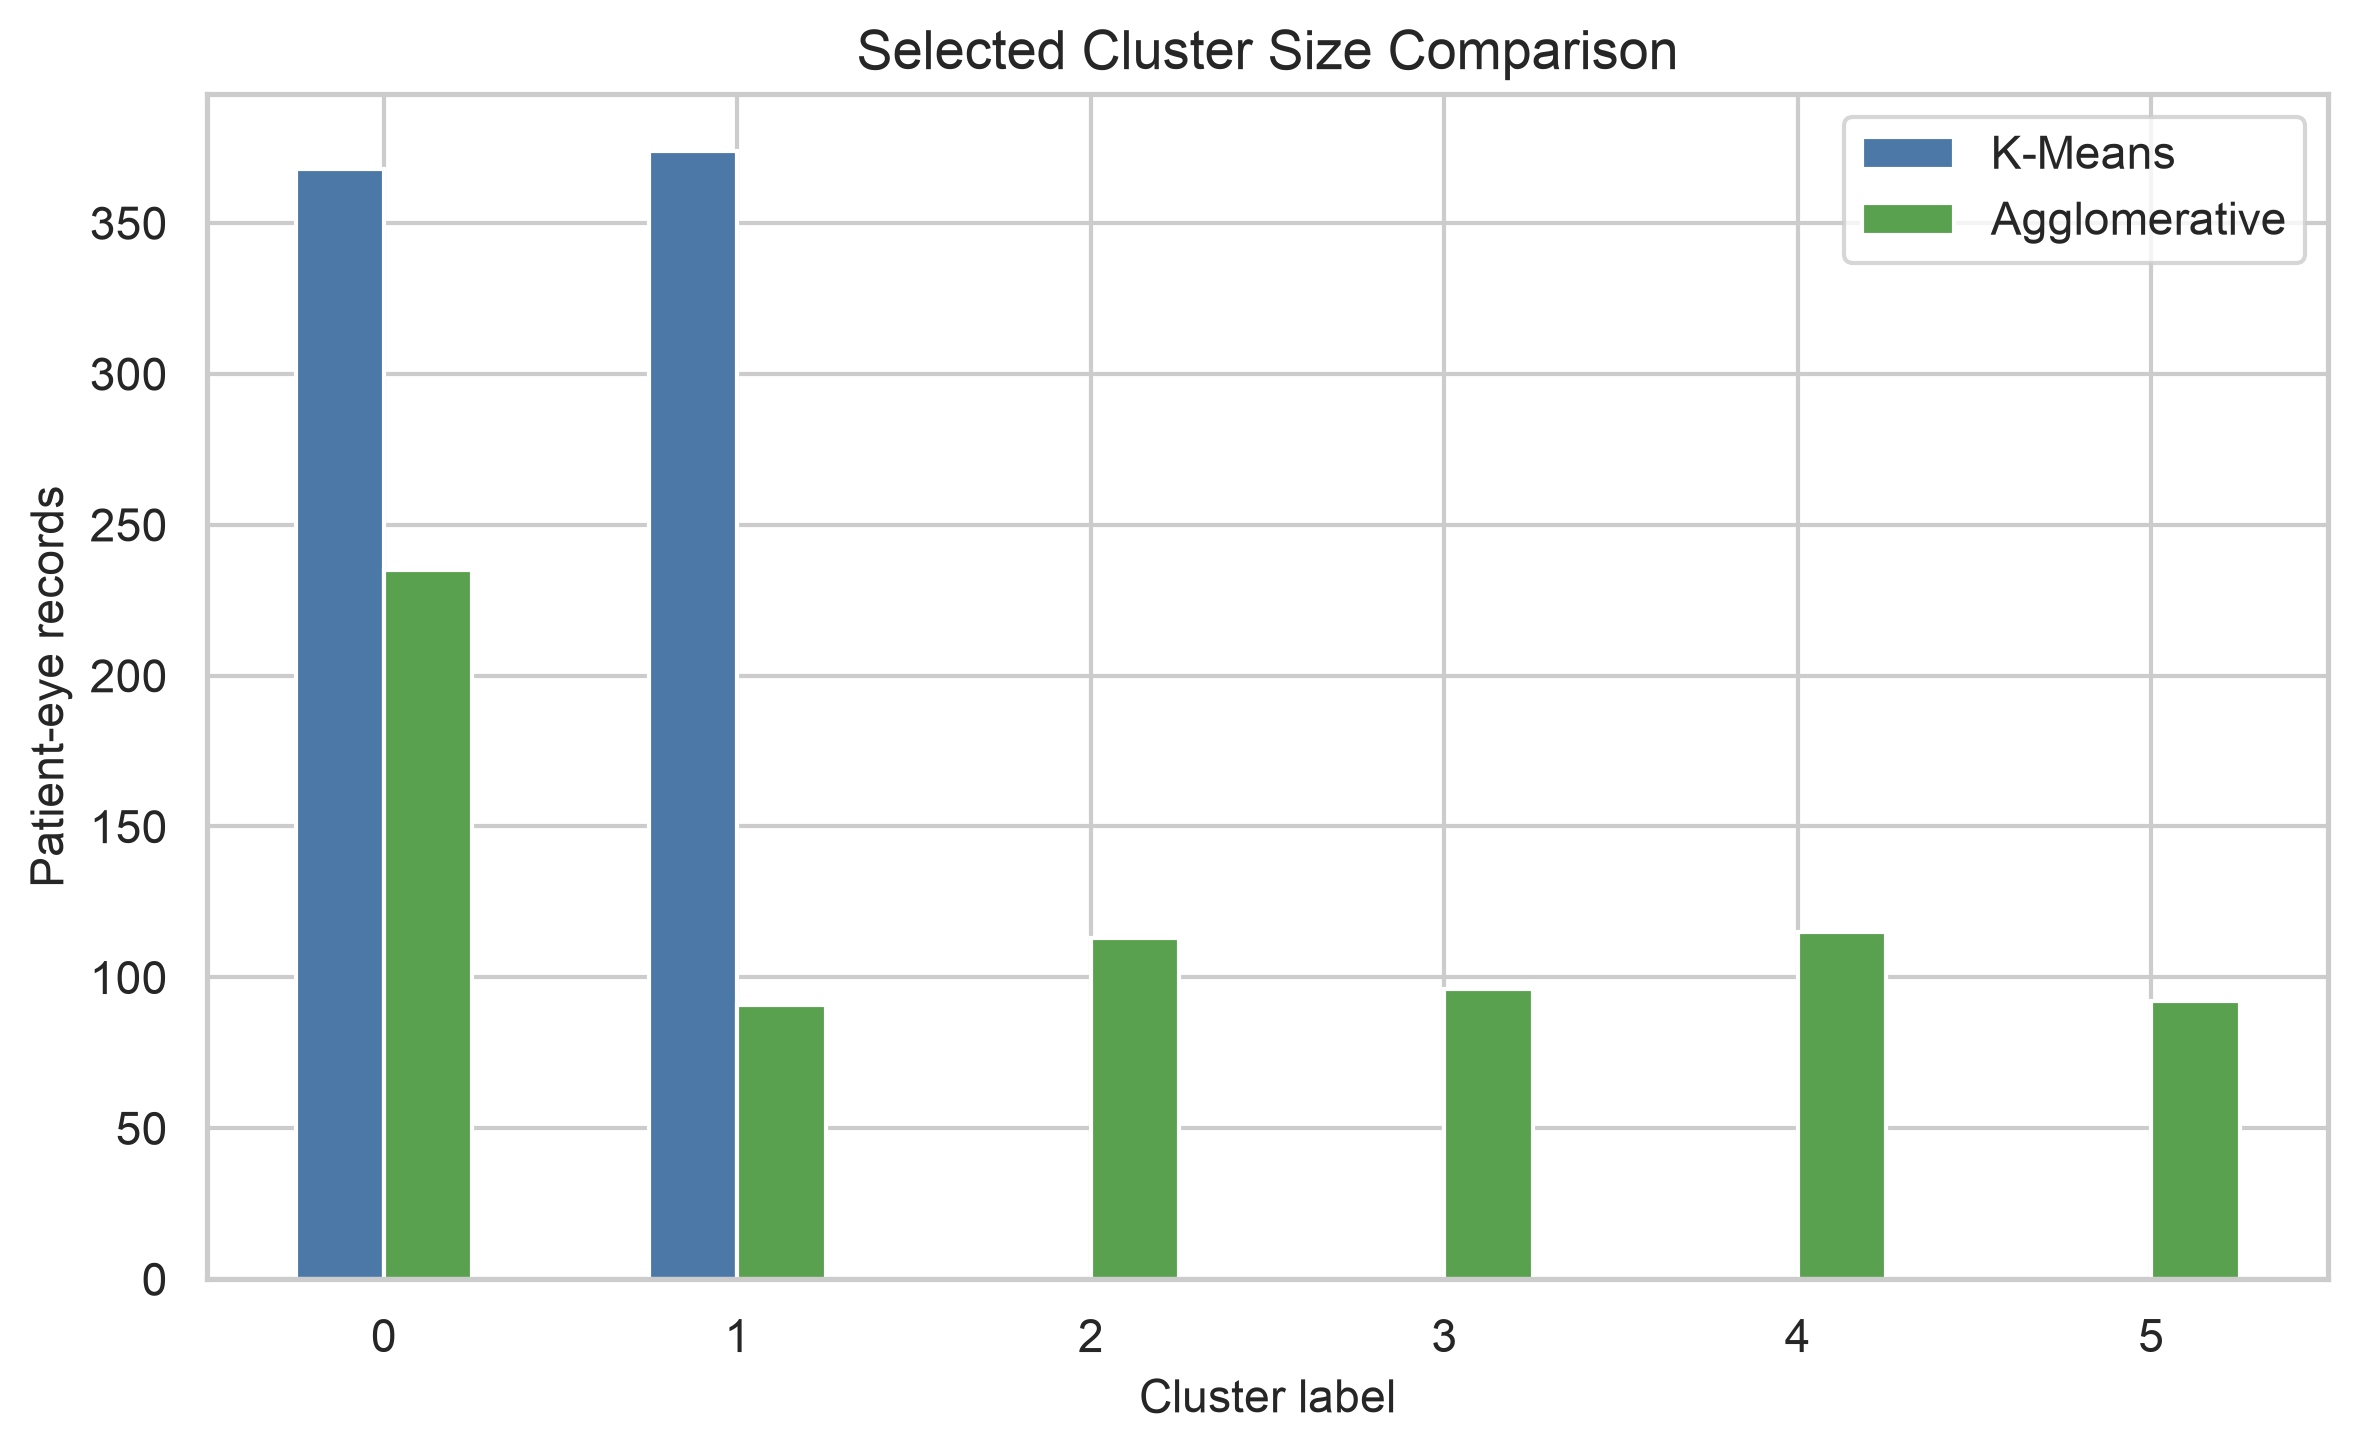

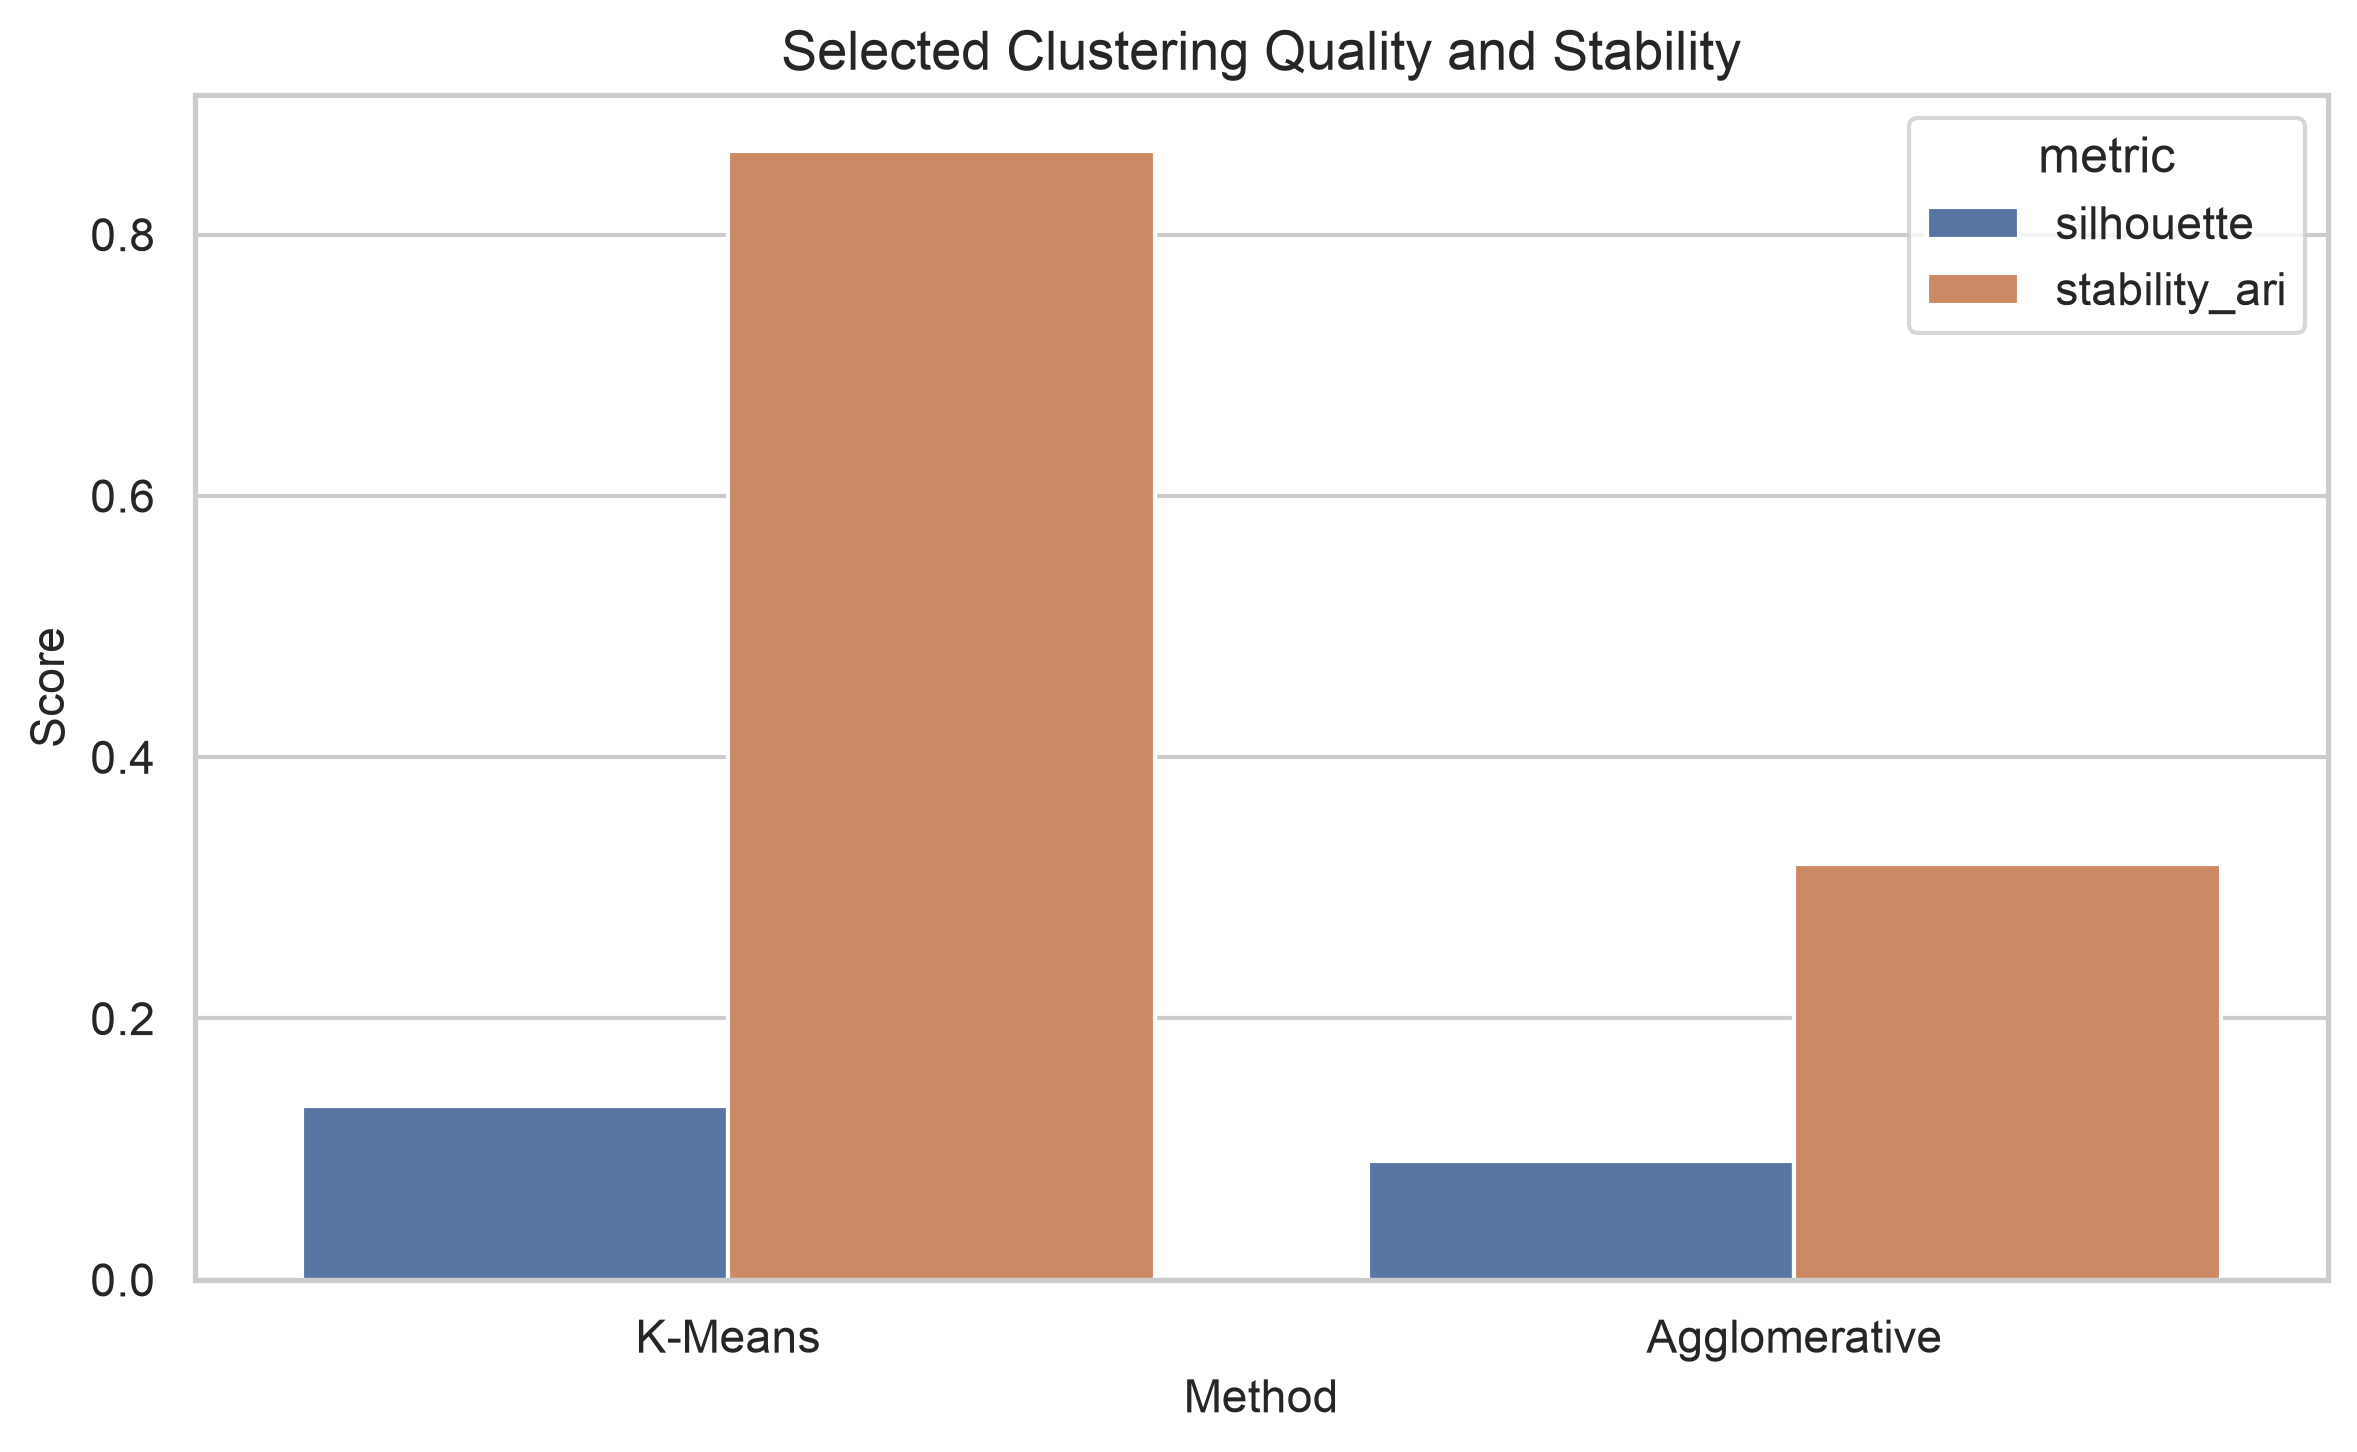

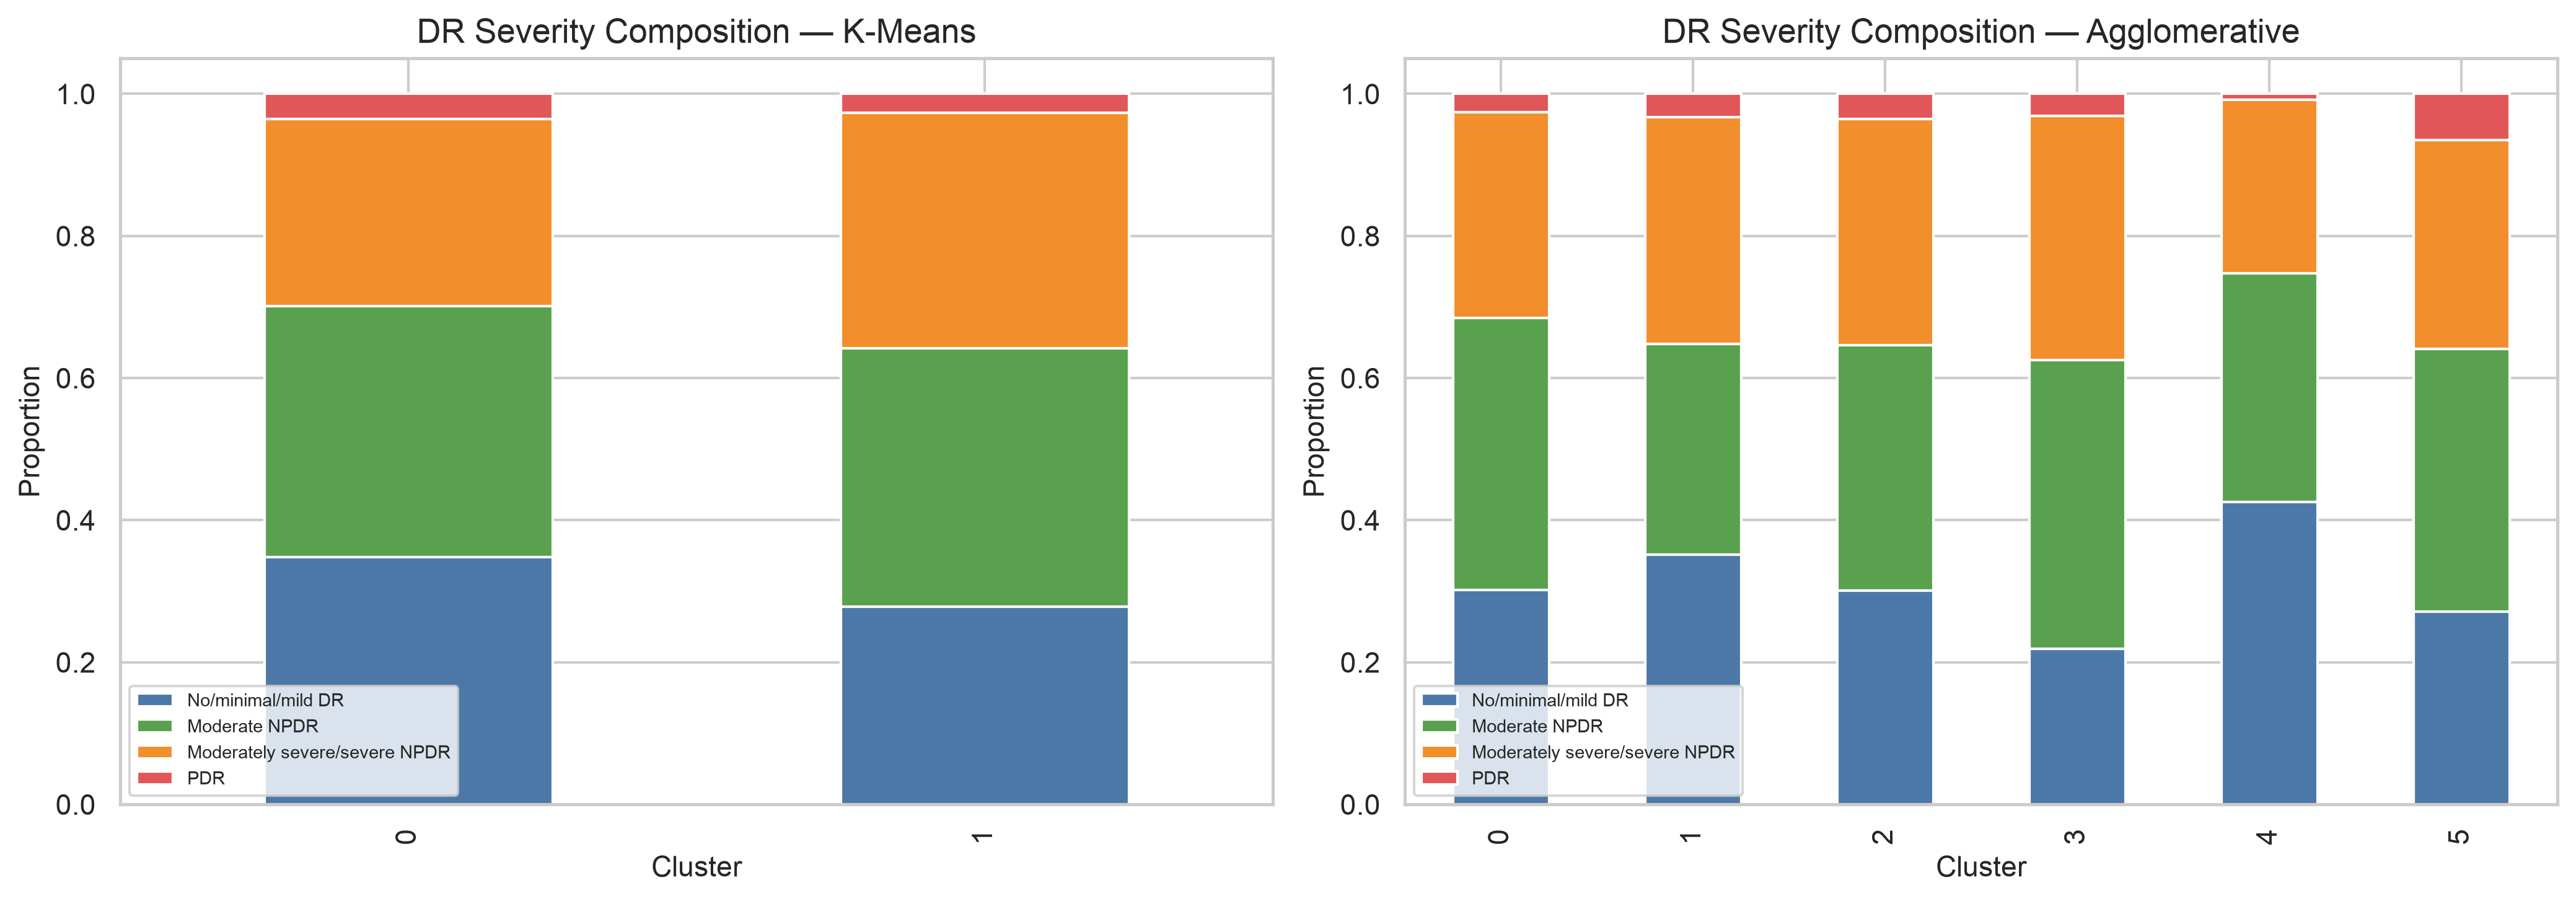

In [10]:
display(pd.read_csv(TABLES / 'cluster_profiles.csv'))
display(pd.read_csv(TABLES / 'cluster_severity_composition.csv'))
for name in ['11_cluster_pca_projection.png','12_cluster_profile_heatmap.png',
             '13_cluster_size_comparison.png','14_clustering_metric_comparison.png',
             '15_severity_composition_by_cluster.png']:
    display(Image(filename=str(FIGURES / name)))

## 10. Unit 4 Problem Statement

**How does temporal dependence influence DR severity-state modeling, and what do empirical transition probabilities reveal?**

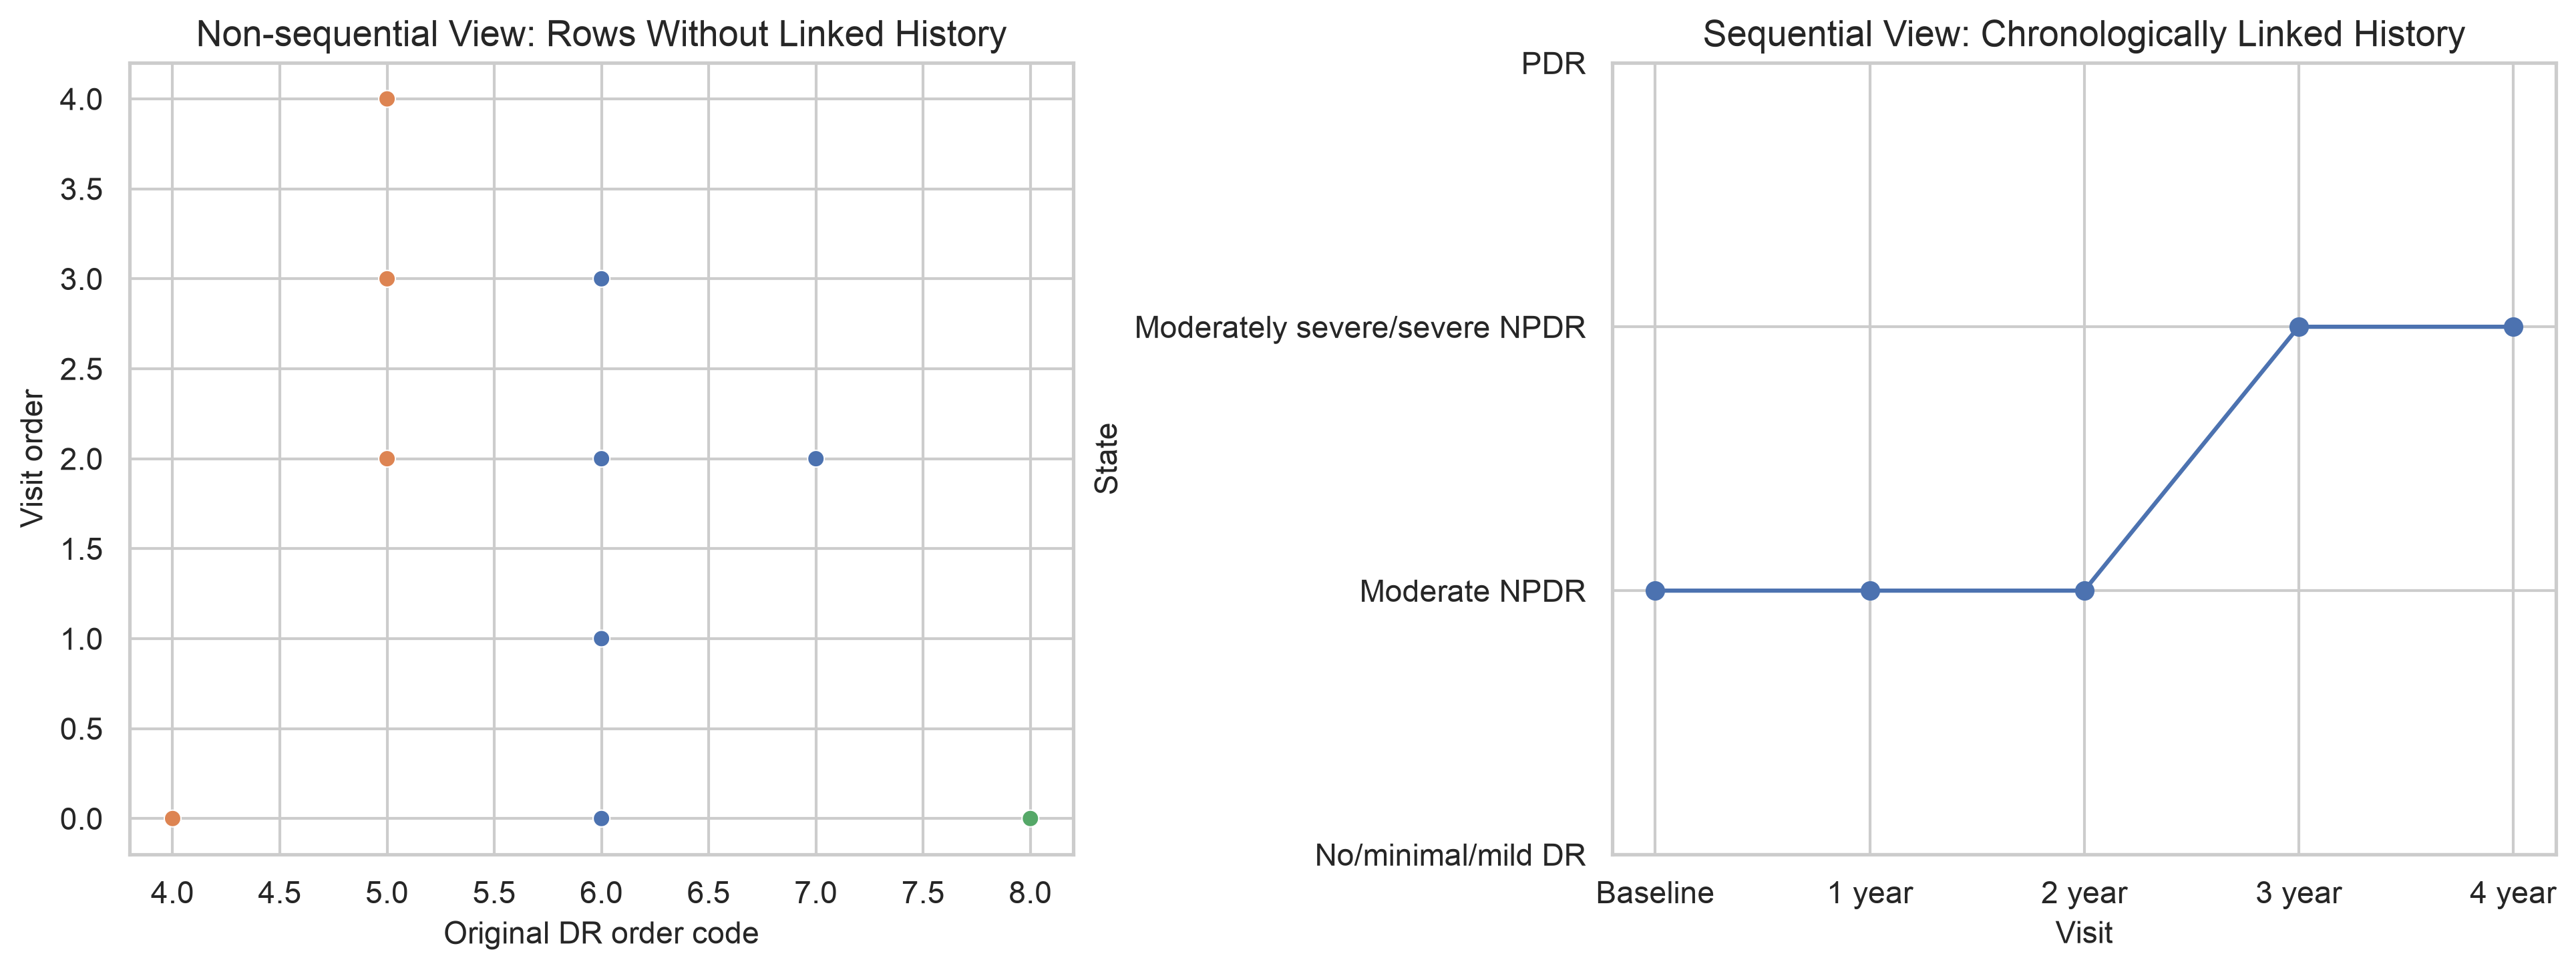

In [11]:
display(Image(filename=str(FIGURES / '16_sequential_vs_nonsequential.png')))

## 11. Sequential vs Non-Sequential Data

Baseline rows are independent feature records; longitudinal data link repeated grades by patient, eye, and chronological date. Missing follow-up is not treated as stability.

In [12]:
print('Baseline records:', len(baseline))
print('Longitudinal observations:', len(longitudinal))
print('Patient-eye sequences:', longitudinal.groupby(['PtID','RCEye']).ngroups)
example_rows = longitudinal.copy()
example_rows['anonymous_sequence'] = example_rows.groupby(['PtID','RCEye'], sort=False).ngroup() + 1
display(example_rows[['anonymous_sequence','Visit','VisitDt','drSeverity','severity_state']].head(10))

Baseline records: 742
Longitudinal observations: 3156
Patient-eye sequences: 772


,anonymous_sequence,Visit,VisitDt,drSeverity,severity_state
0,1,Baseline,2015-04-06,53A,Moderately severe/severe NPDR
1,1,2 year,2017-02-15,47A,Moderate NPDR
2,1,3 year,2018-07-10,47A,Moderate NPDR
3,2,Baseline,2015-04-06,43B,Moderate NPDR
4,2,2 year,2017-02-15,61B,Moderately severe/severe NPDR
5,2,3 year,2018-07-10,47A,Moderate NPDR
6,3,Baseline,2015-02-22,53A,Moderately severe/severe NPDR
7,3,1 year,2016-03-19,53A,Moderately severe/severe NPDR
8,3,2 year,2016-12-18,53A,Moderately severe/severe NPDR
9,3,3 year,2018-01-15,53A,Moderately severe/severe NPDR


## 12. Markov Property

The first-order assumption is

$$P(S_{t+1}\mid S_t,S_{t-1},\ldots,S_0)=P(S_{t+1}\mid S_t).$$

It is an approximation to investigate, not a proven biological law.

,model,test_transitions,accuracy,log_loss,second_order_context_coverage,train_patients,test_patients
0,First-order,439,0.553531,1.018639,NaN,291,97
1,Second-order with first-order backoff,439,0.589977,0.998192,1.0,291,97


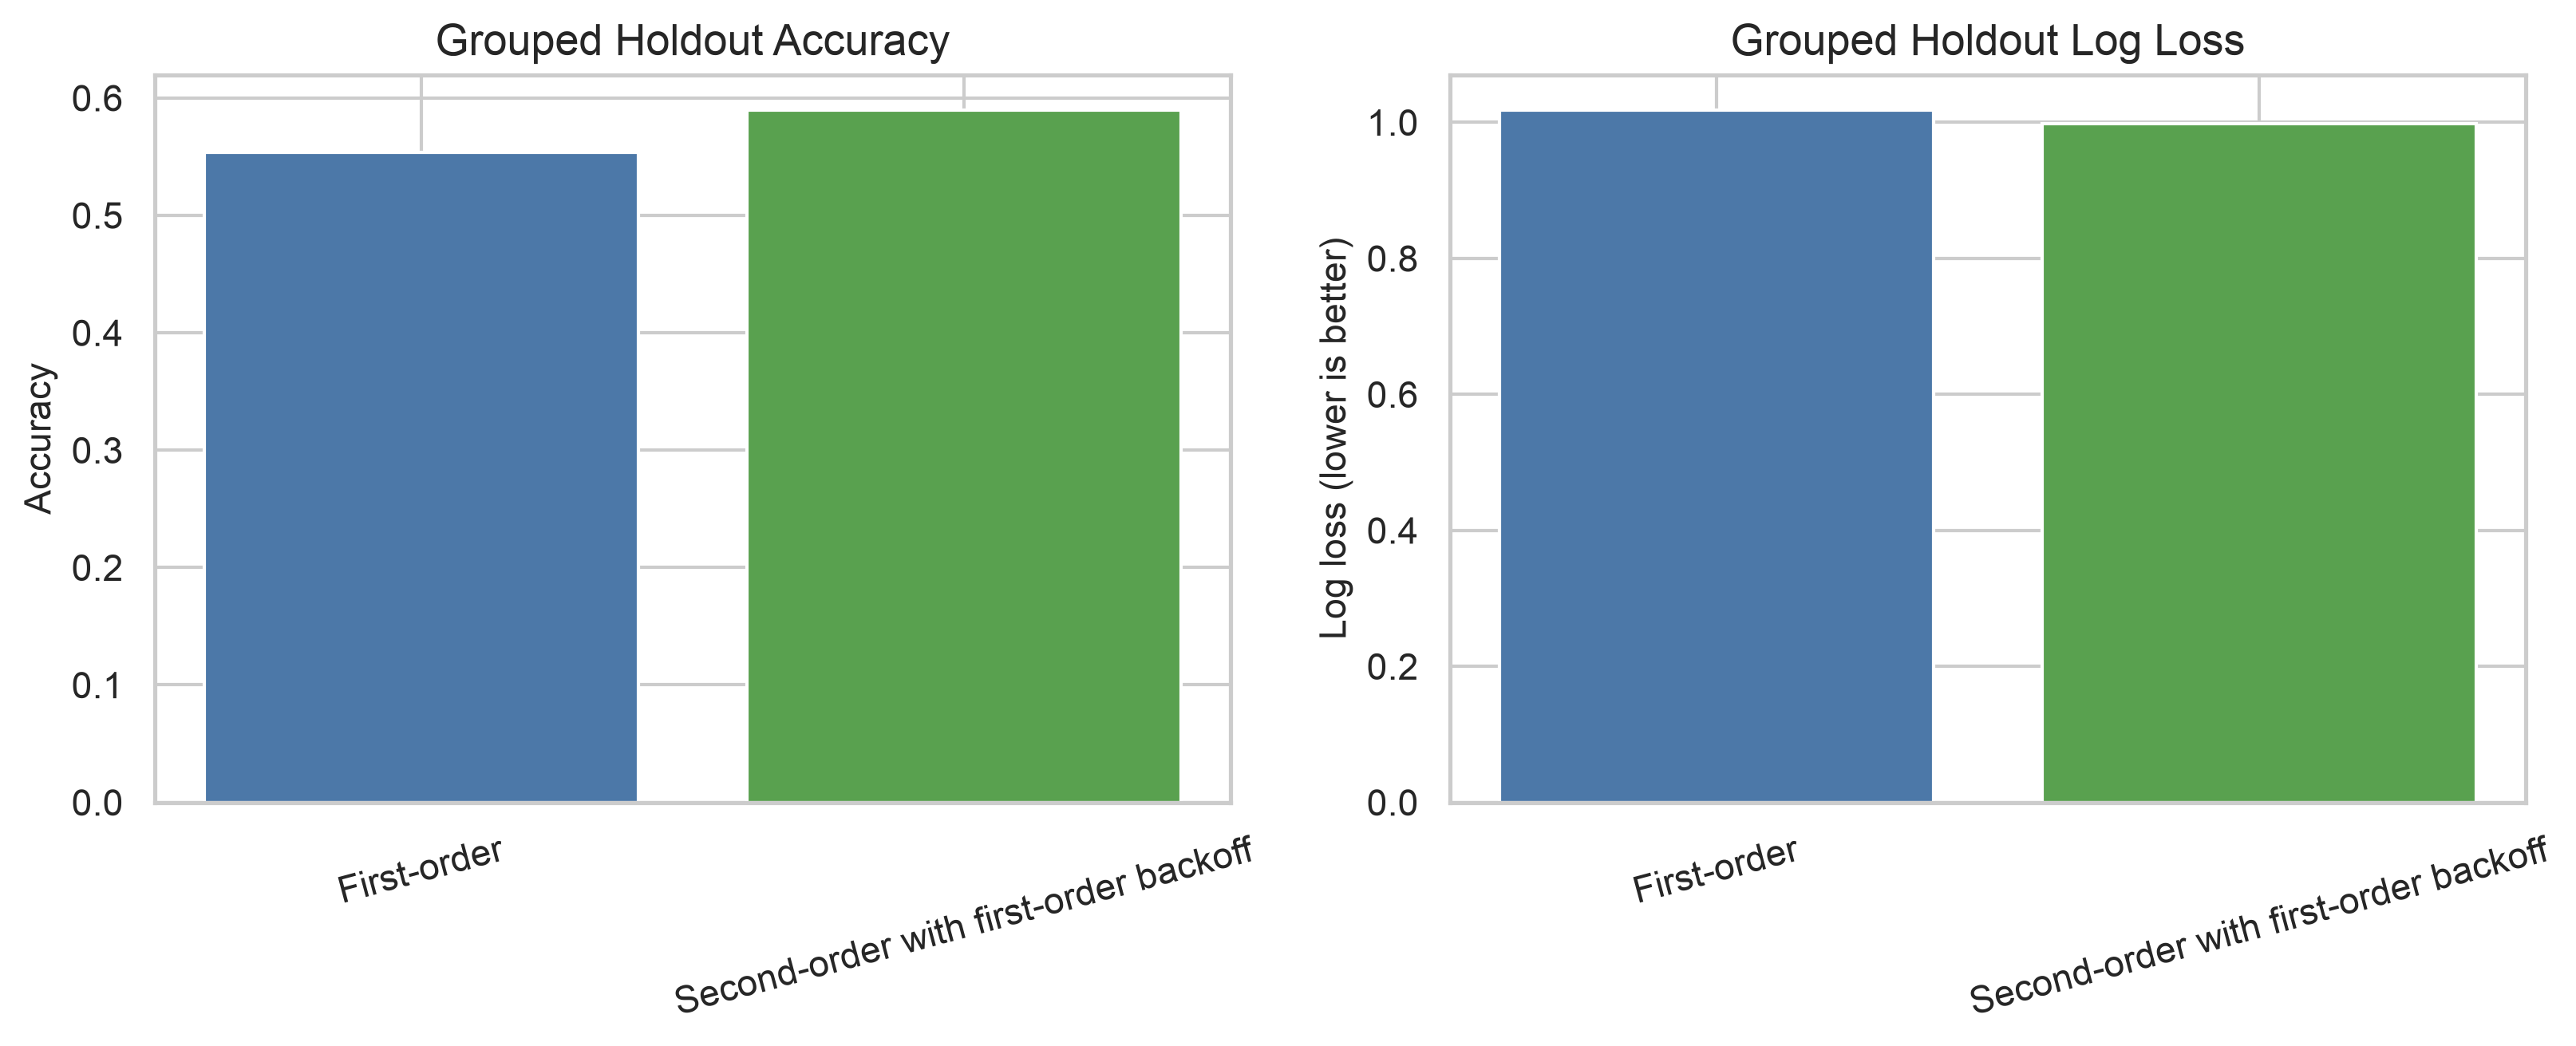

In [13]:
comparison = pd.read_csv(TABLES / 'markov_order_comparison.csv')
display(comparison)
display(Image(filename=str(FIGURES / '22_markov_order_comparison.png')))

## 13. Transition Matrix Estimation

Each row is divided by its observed outgoing-transition denominator. Ungradable and missing visits are not interpreted as stable disease.

,No/minimal/mild DR,Moderate NPDR,Moderately severe/severe NPDR,PDR
severity_state,,,,
No/minimal/mild DR,500,202,44,10
Moderate NPDR,199,417,197,17
Moderately severe/severe NPDR,46,198,389,52
PDR,3,22,43,45


,No/minimal/mild DR,Moderate NPDR,Moderately severe/severe NPDR,PDR
severity_state,,,,
No/minimal/mild DR,0.661376,0.267196,0.058201,0.013228
Moderate NPDR,0.239759,0.502410,0.237349,0.020482
Moderately severe/severe NPDR,0.067153,0.289051,0.567883,0.075912
PDR,0.026549,0.194690,0.380531,0.398230


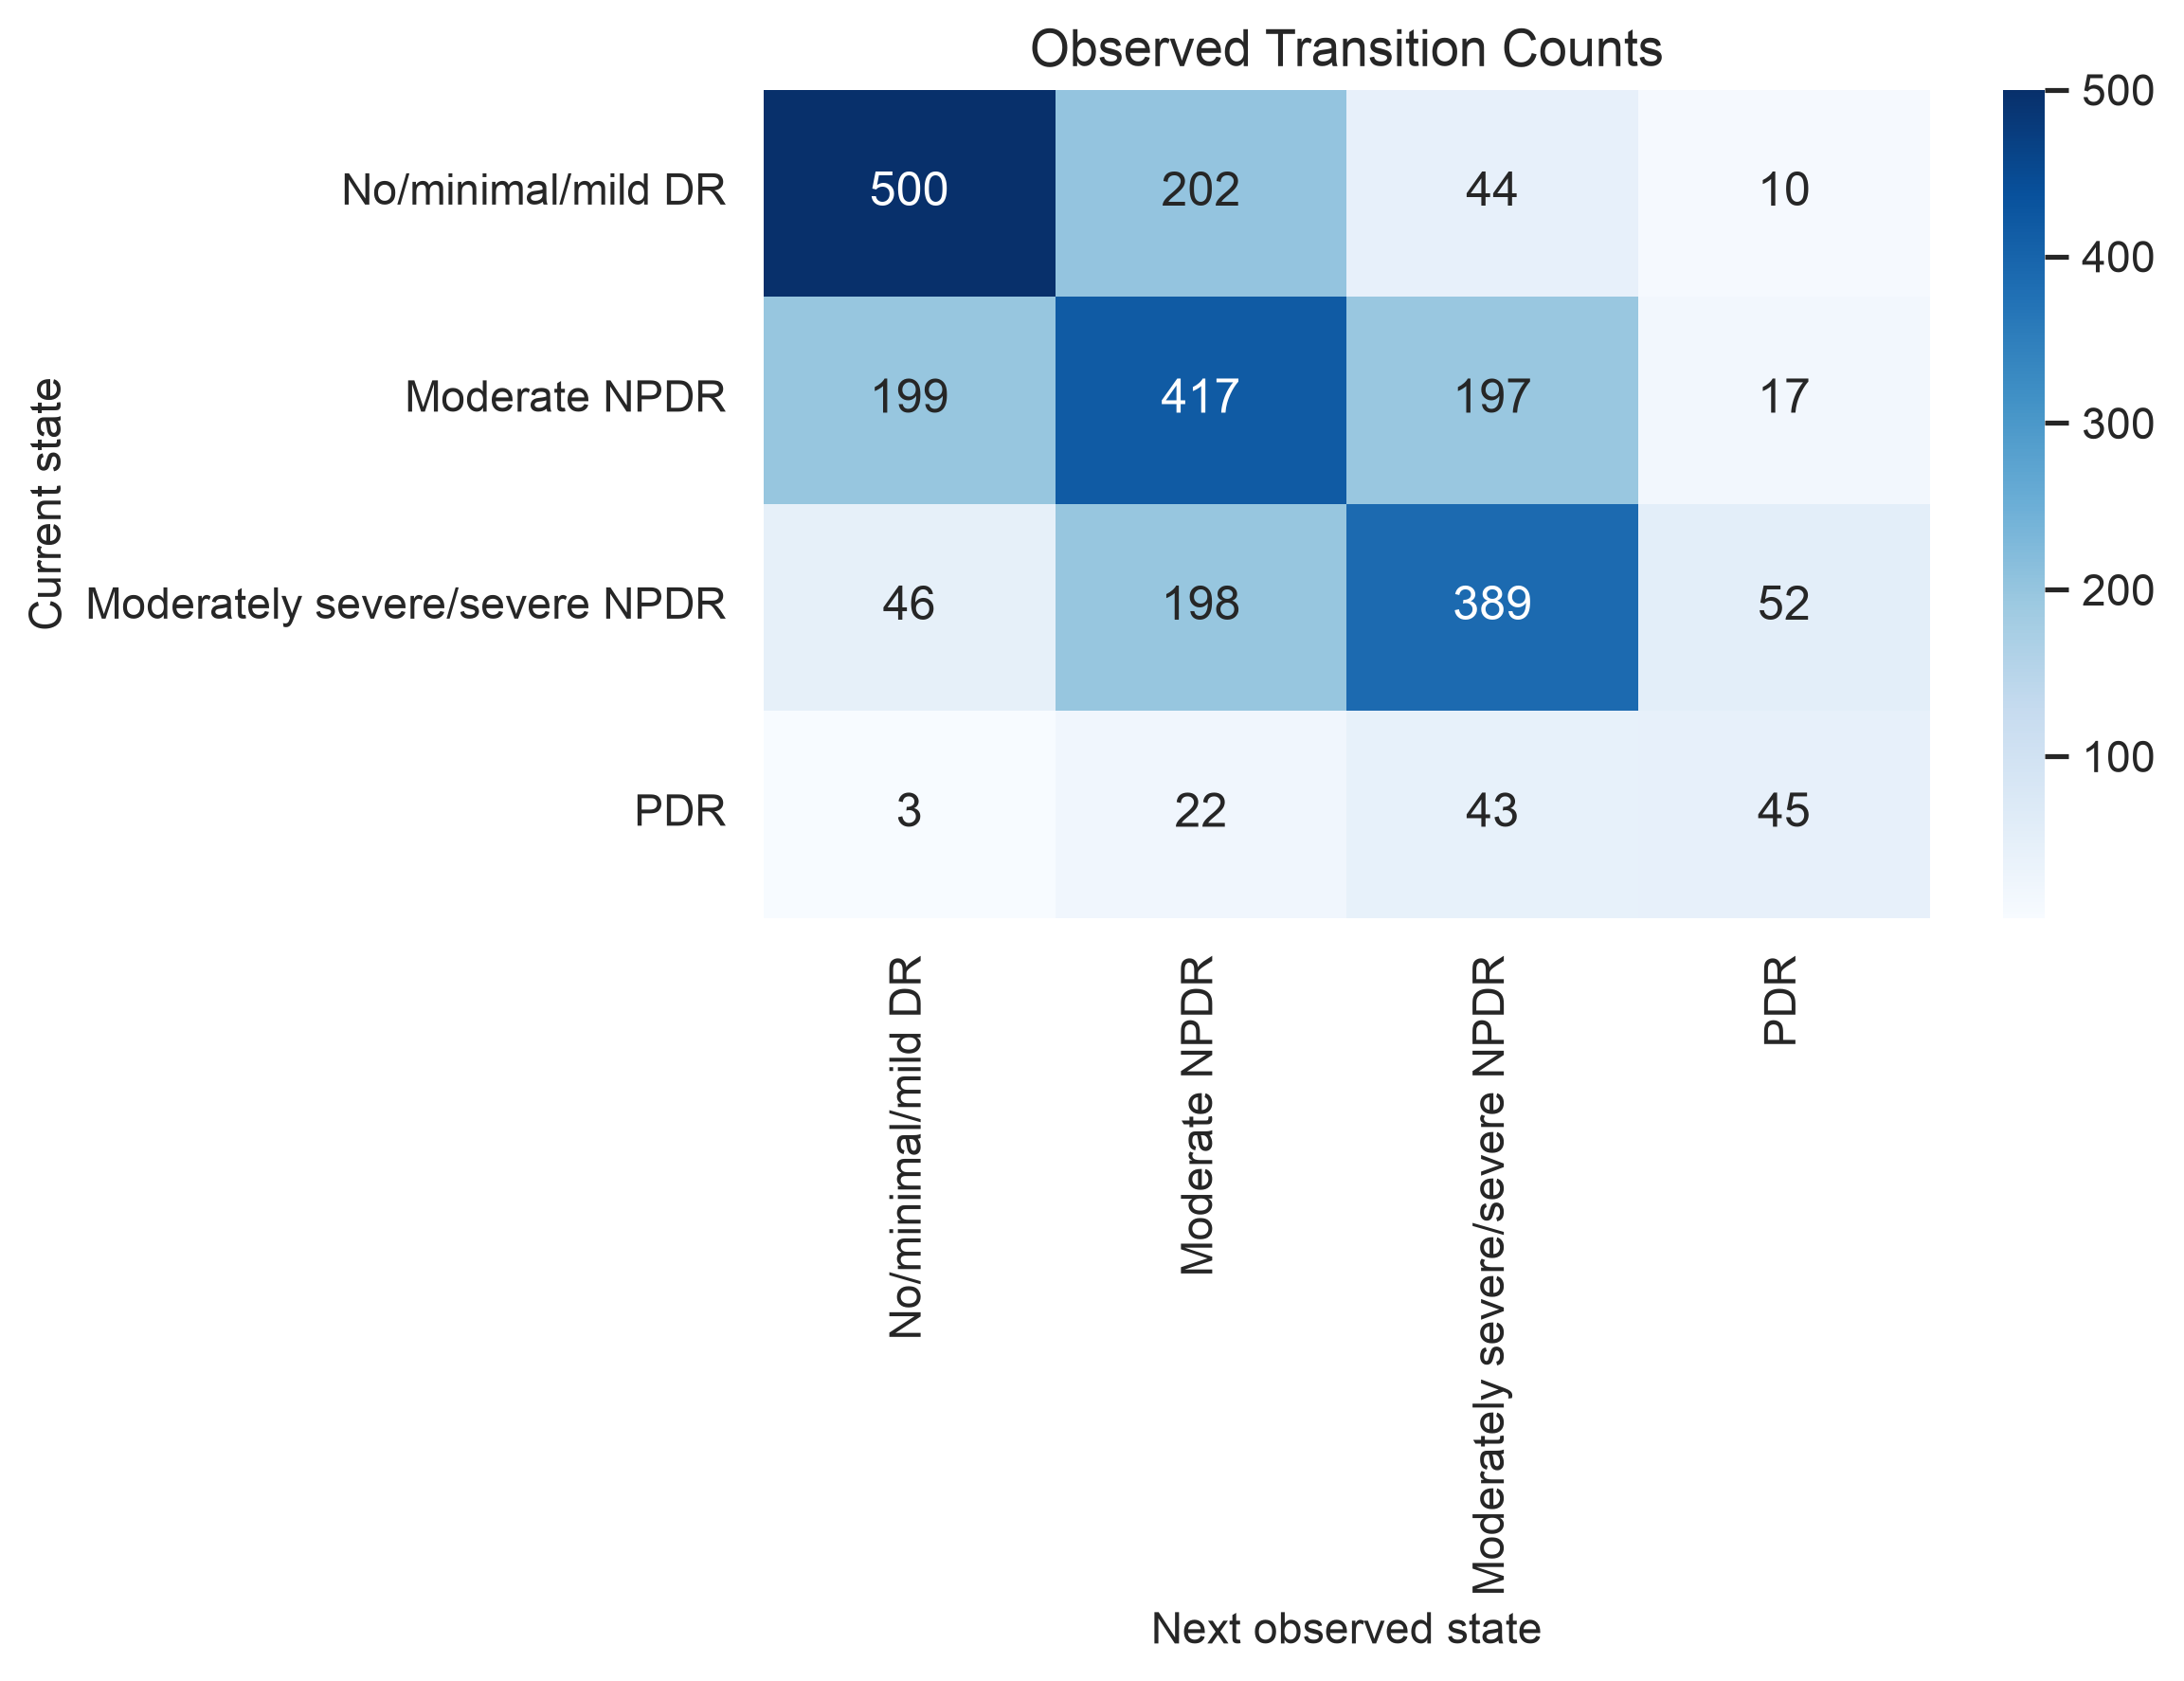

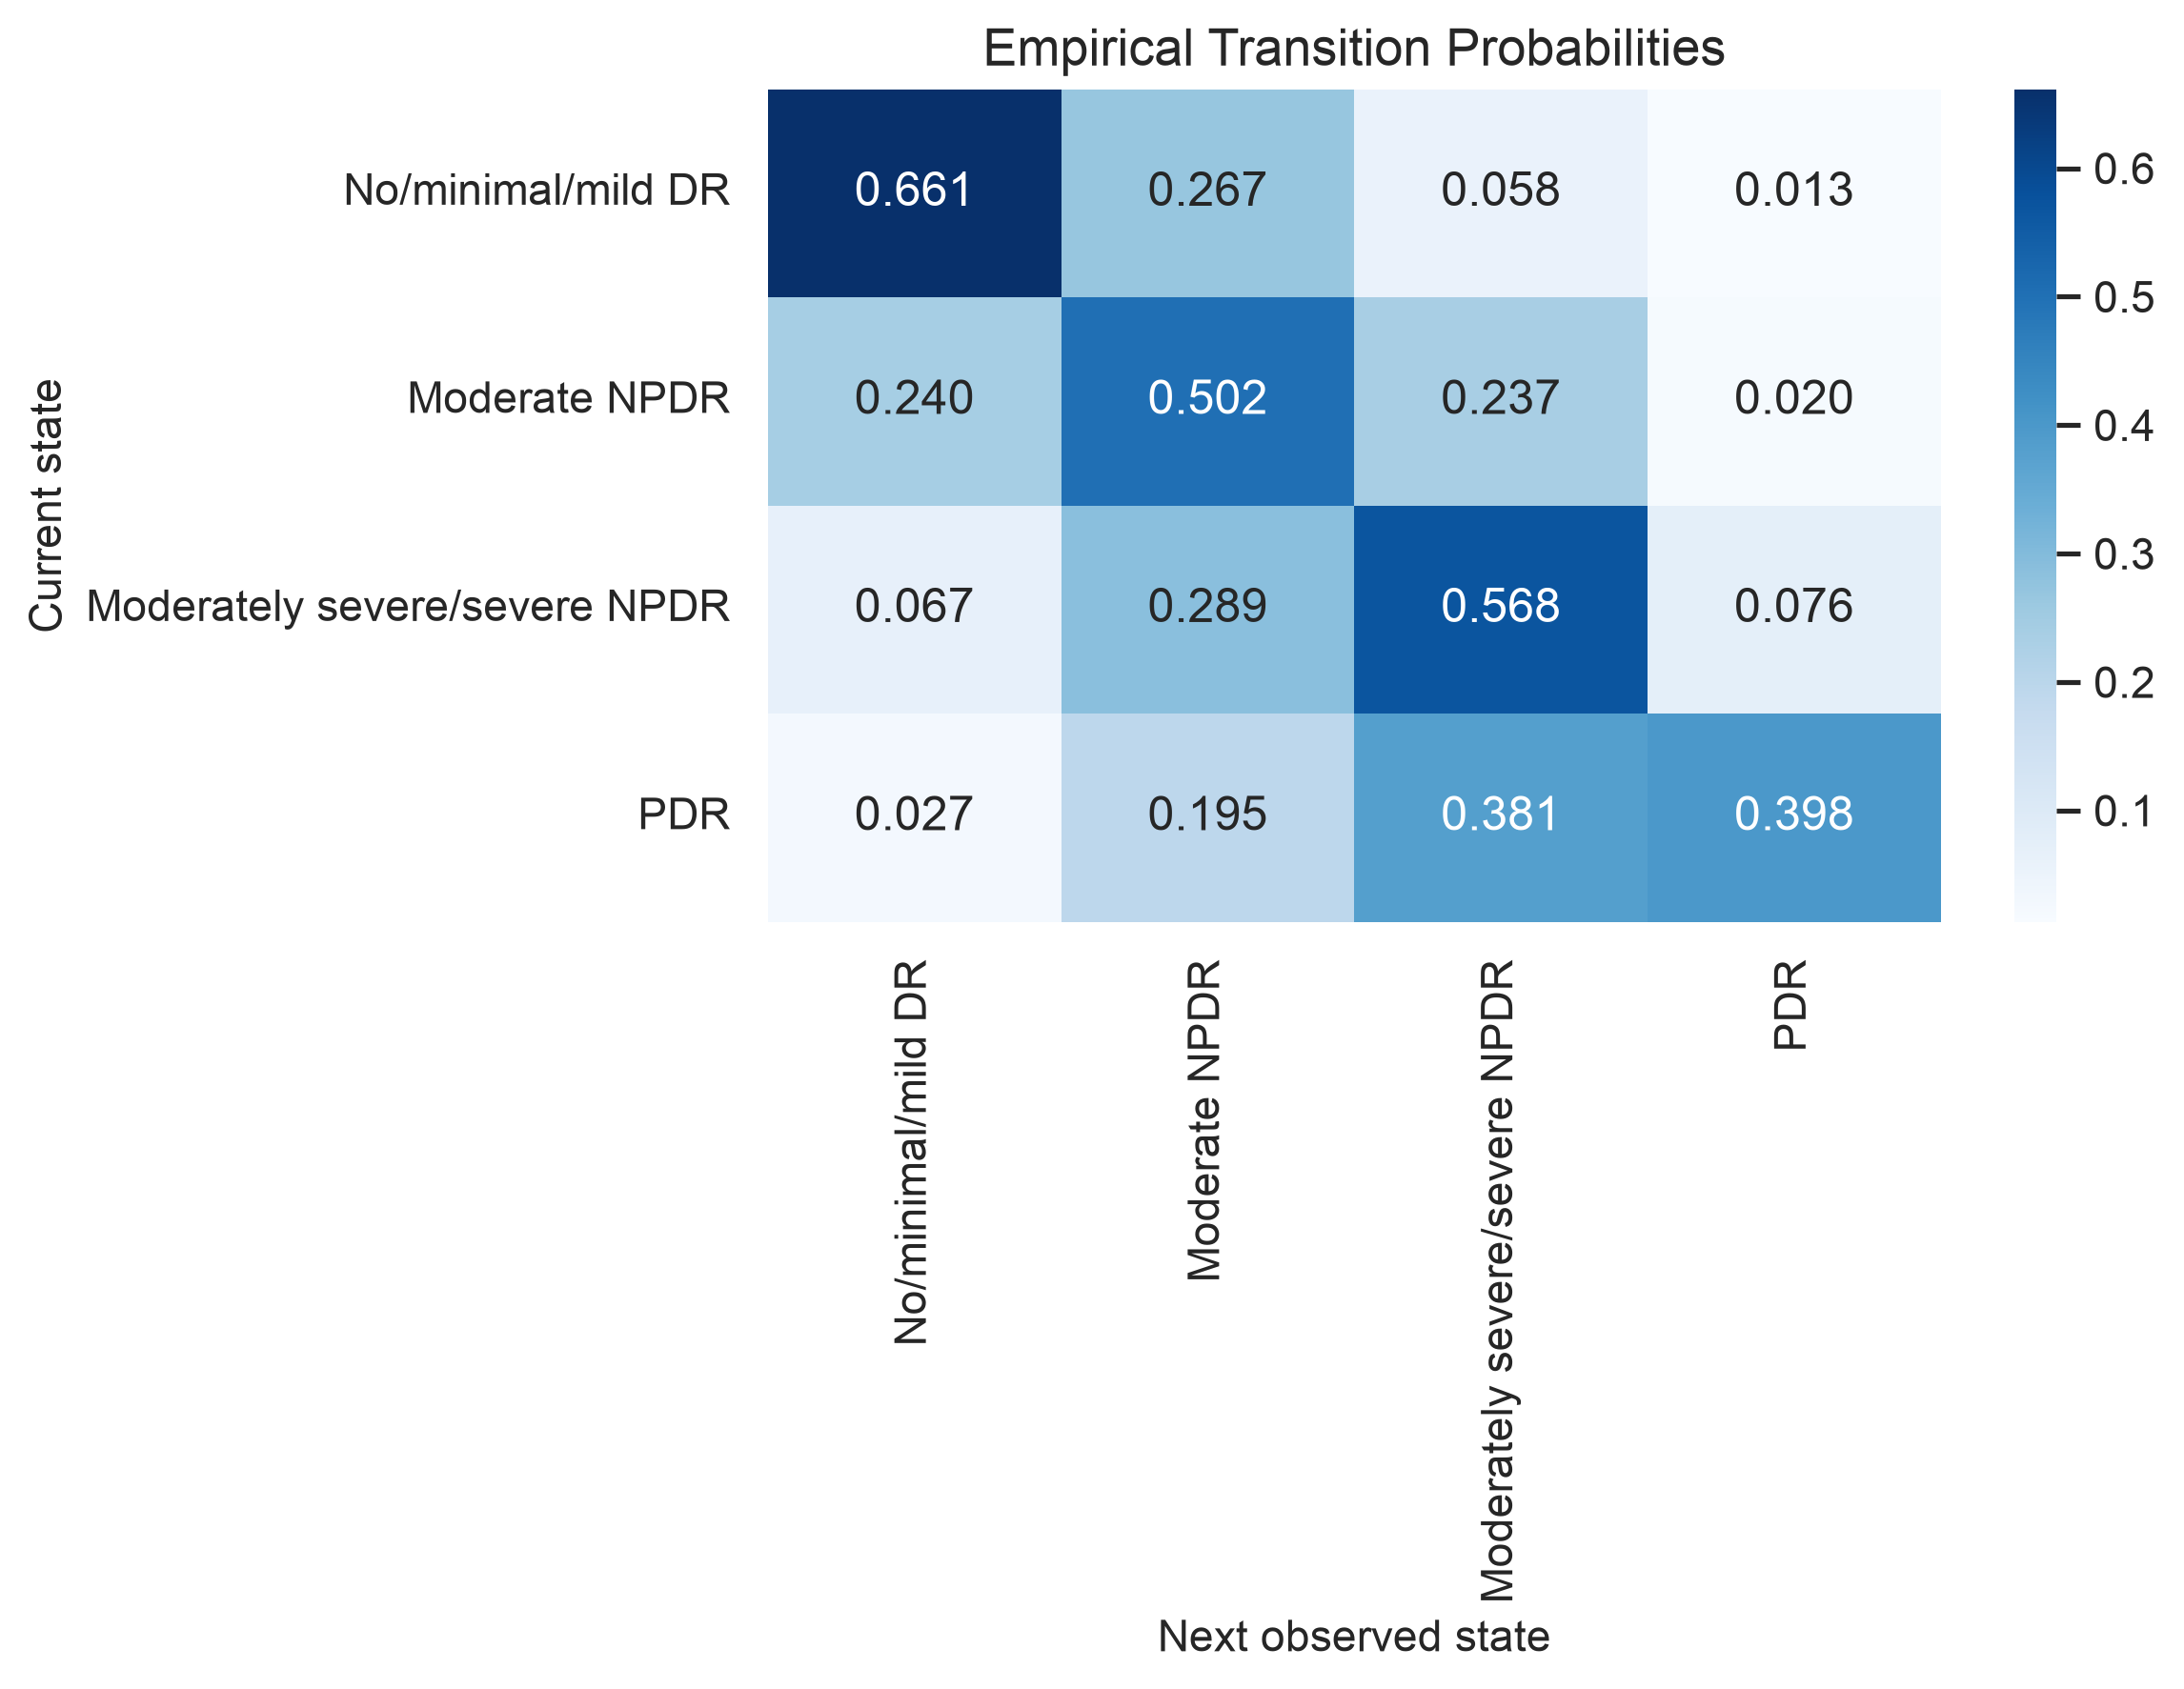

In [14]:
counts = pd.read_csv(TABLES / 'transition_counts.csv', index_col=0)
probabilities = pd.read_csv(TABLES / 'transition_probabilities.csv', index_col=0)
display(counts); display(probabilities)
display(Image(filename=str(FIGURES / '17_transition_count_matrix.png')))
display(Image(filename=str(FIGURES / '18_transition_probability_matrix.png')))

## 14. Transition Probability Analysis

,change,count
0,Progression,522
1,Regression,511
2,Stable,1351


,interval_group,change,count
0,<300 days,Progression,49
1,<300 days,Regression,54
2,<300 days,Stable,108
3,300–430 days,Progression,410
4,300–430 days,Regression,402
5,300–430 days,Stable,1044
6,>430 days,Progression,63
7,>430 days,Regression,55
8,>430 days,Stable,199


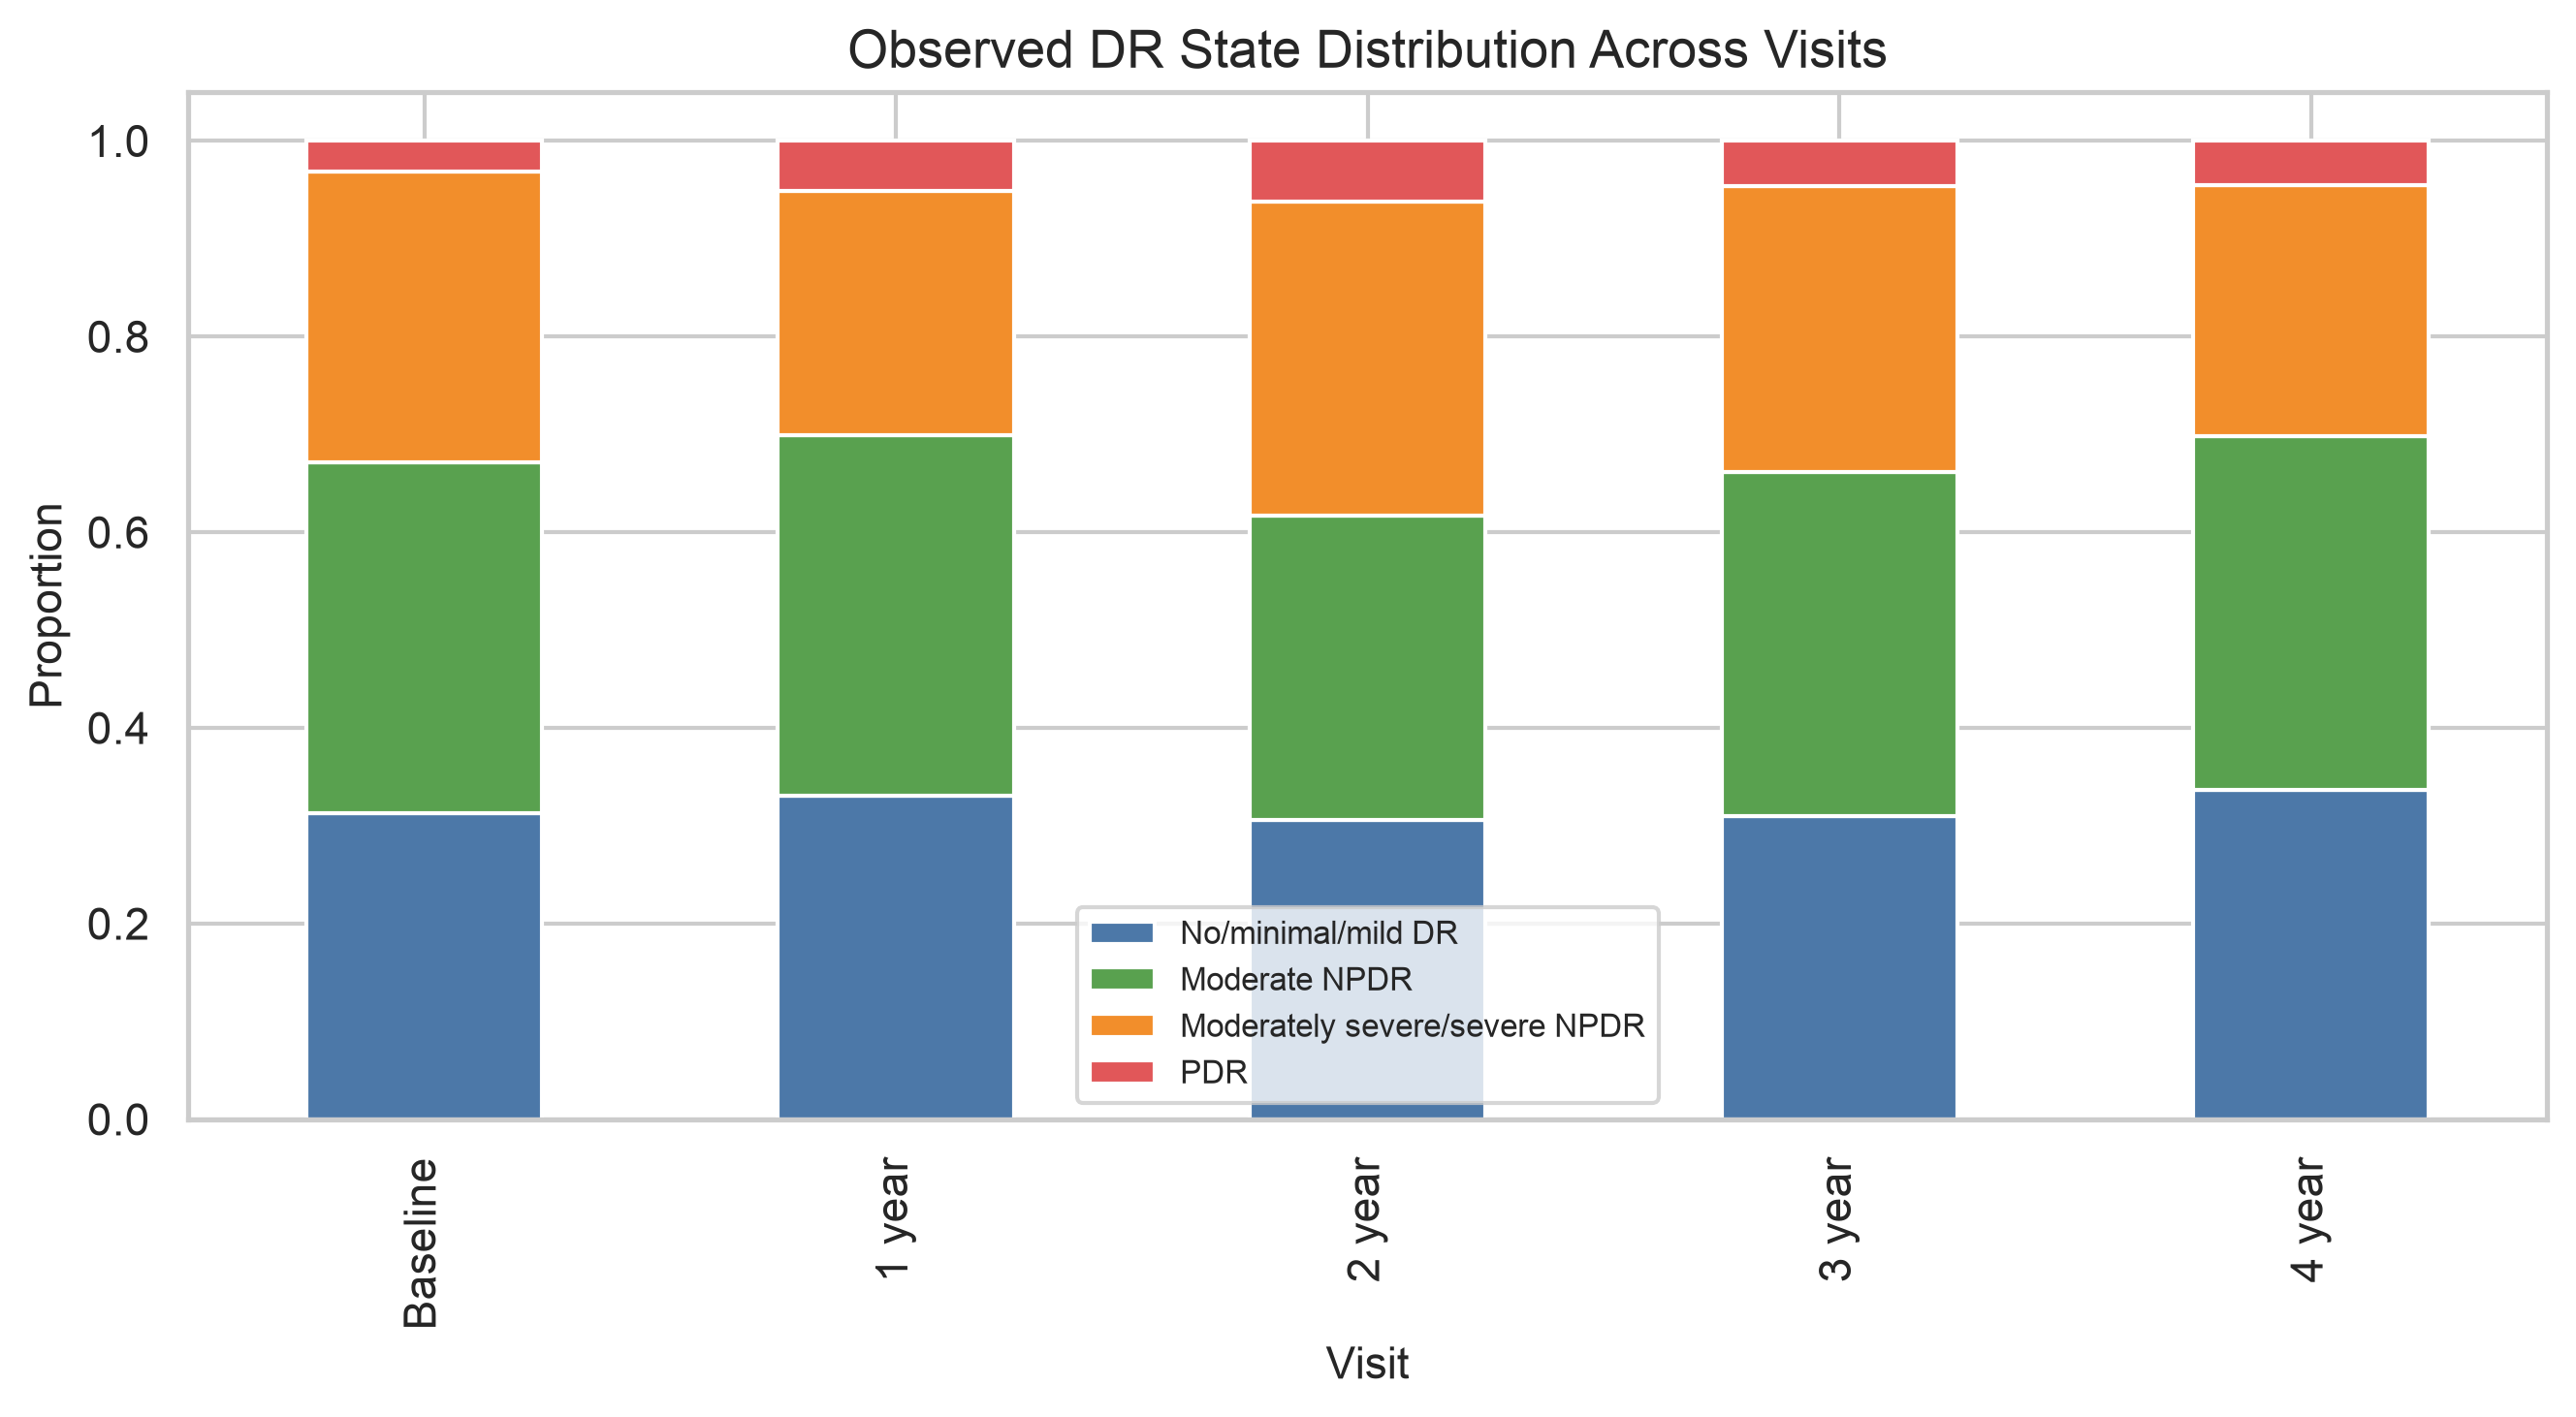

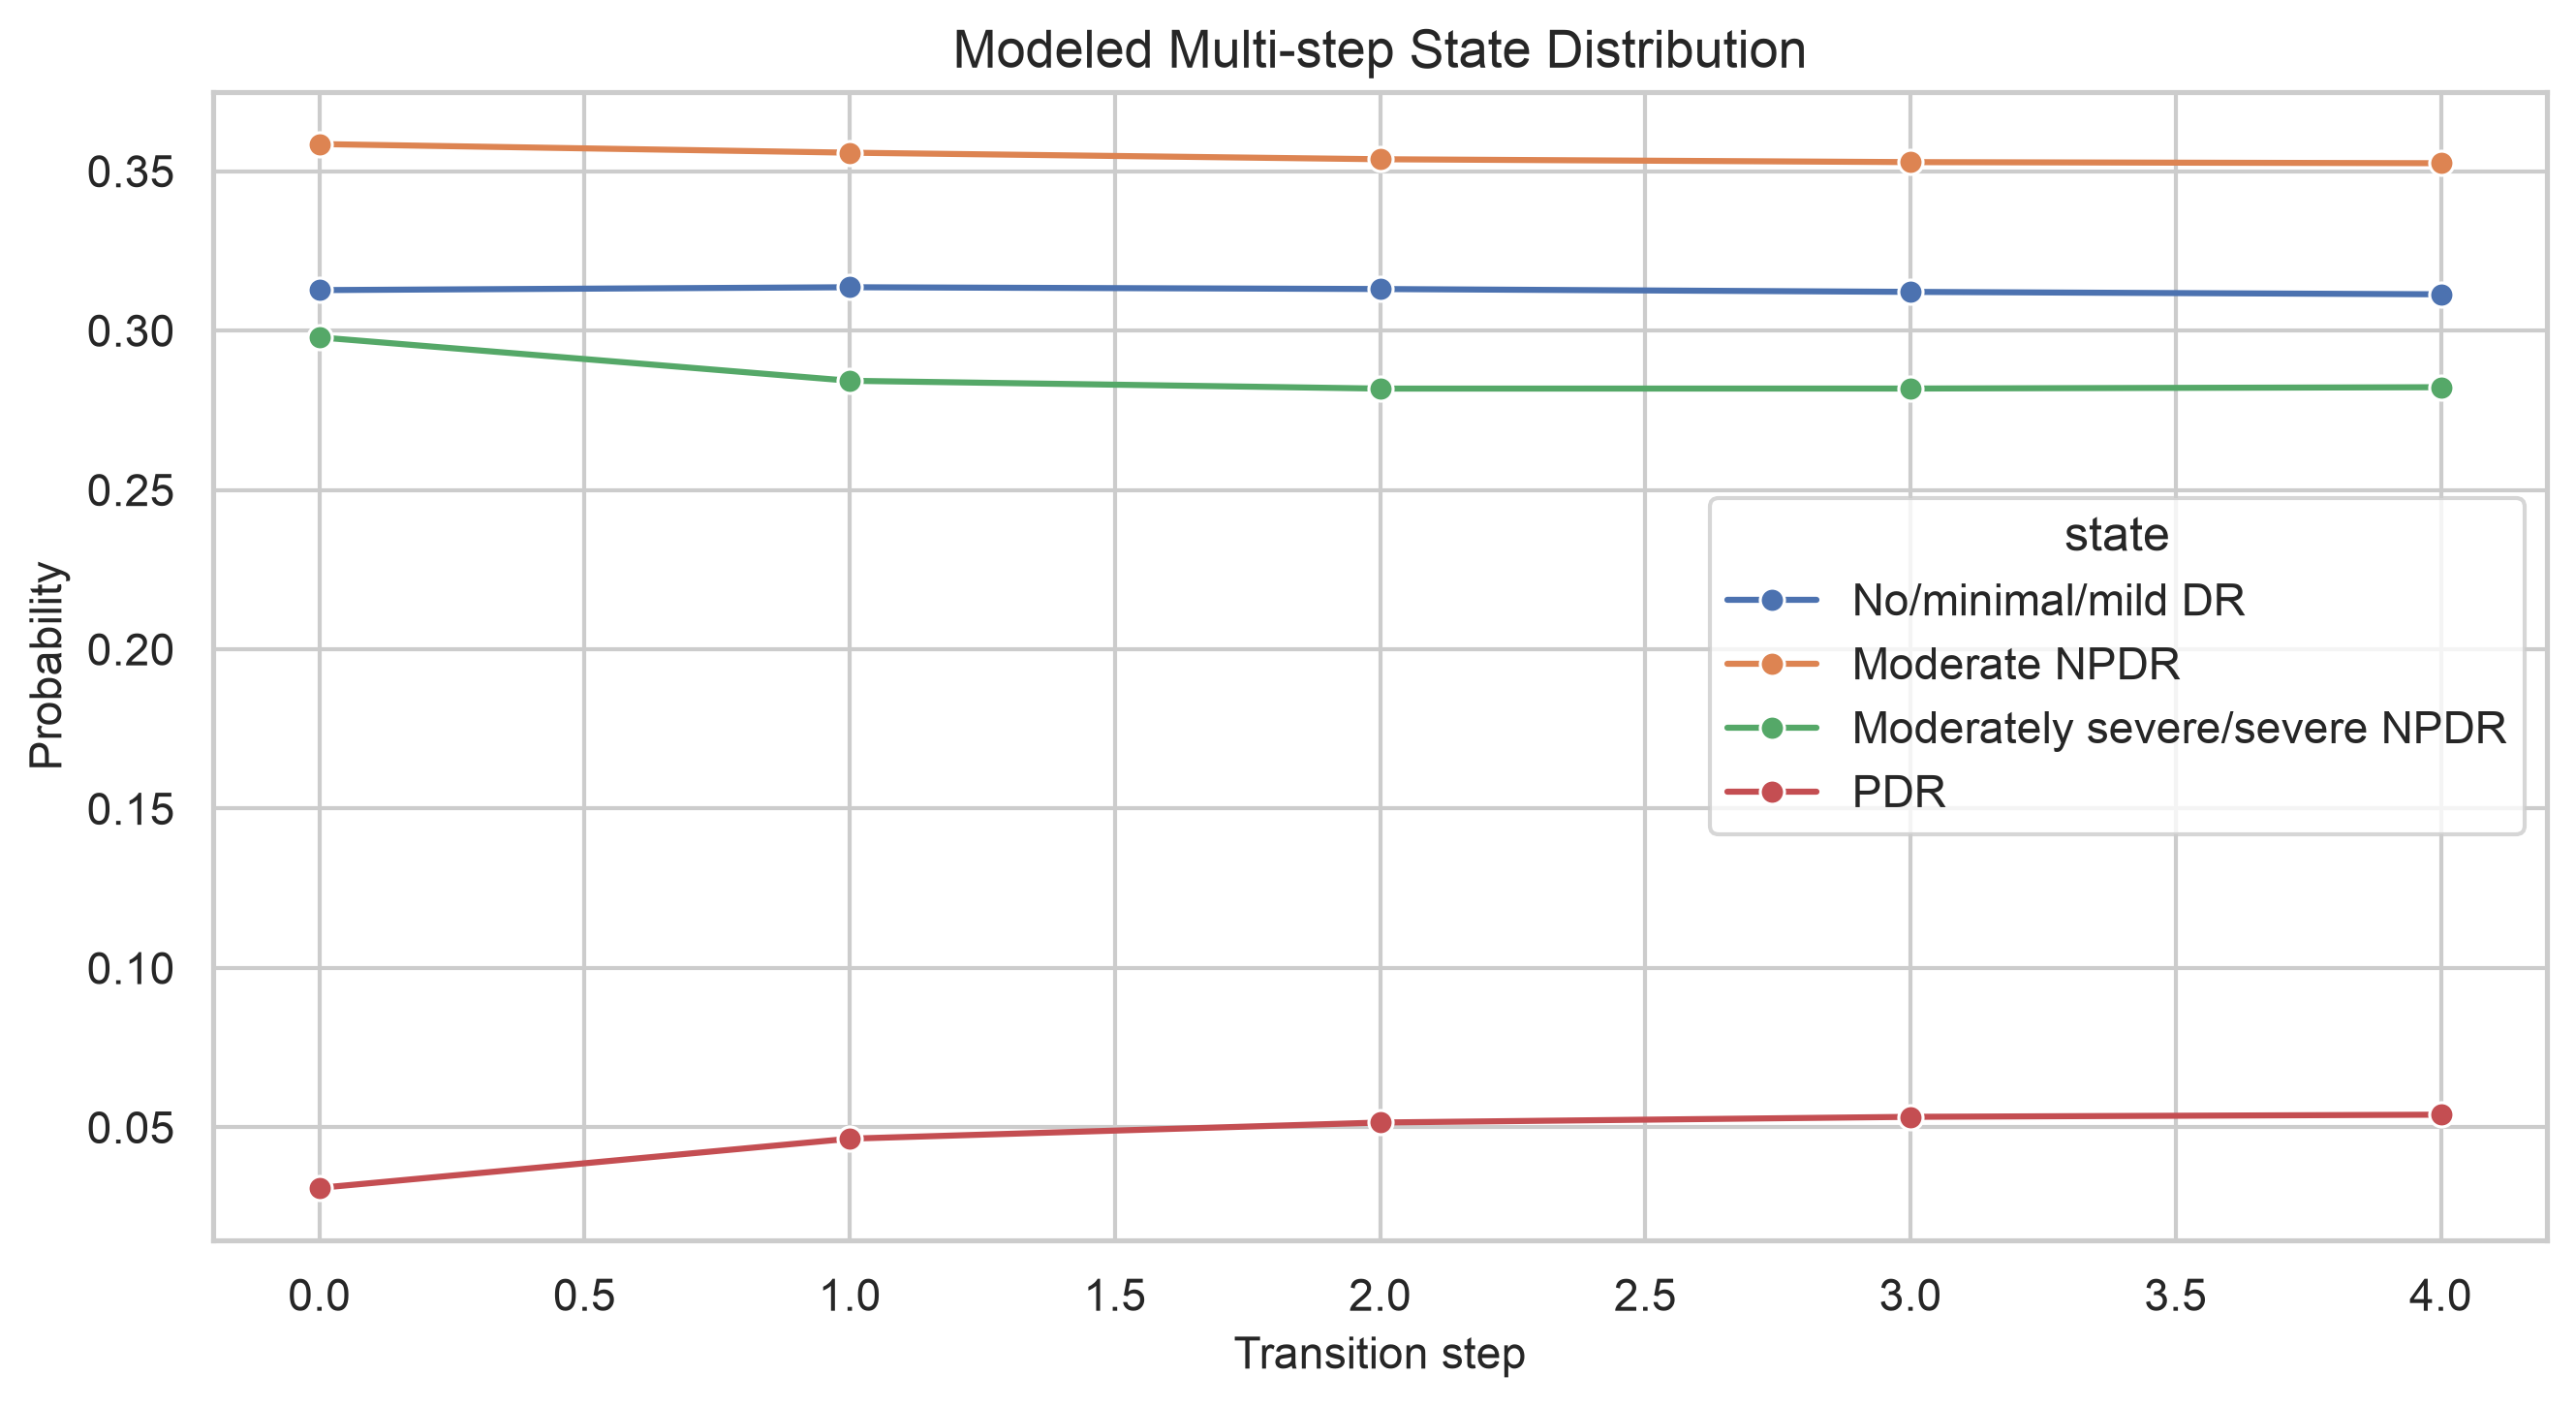

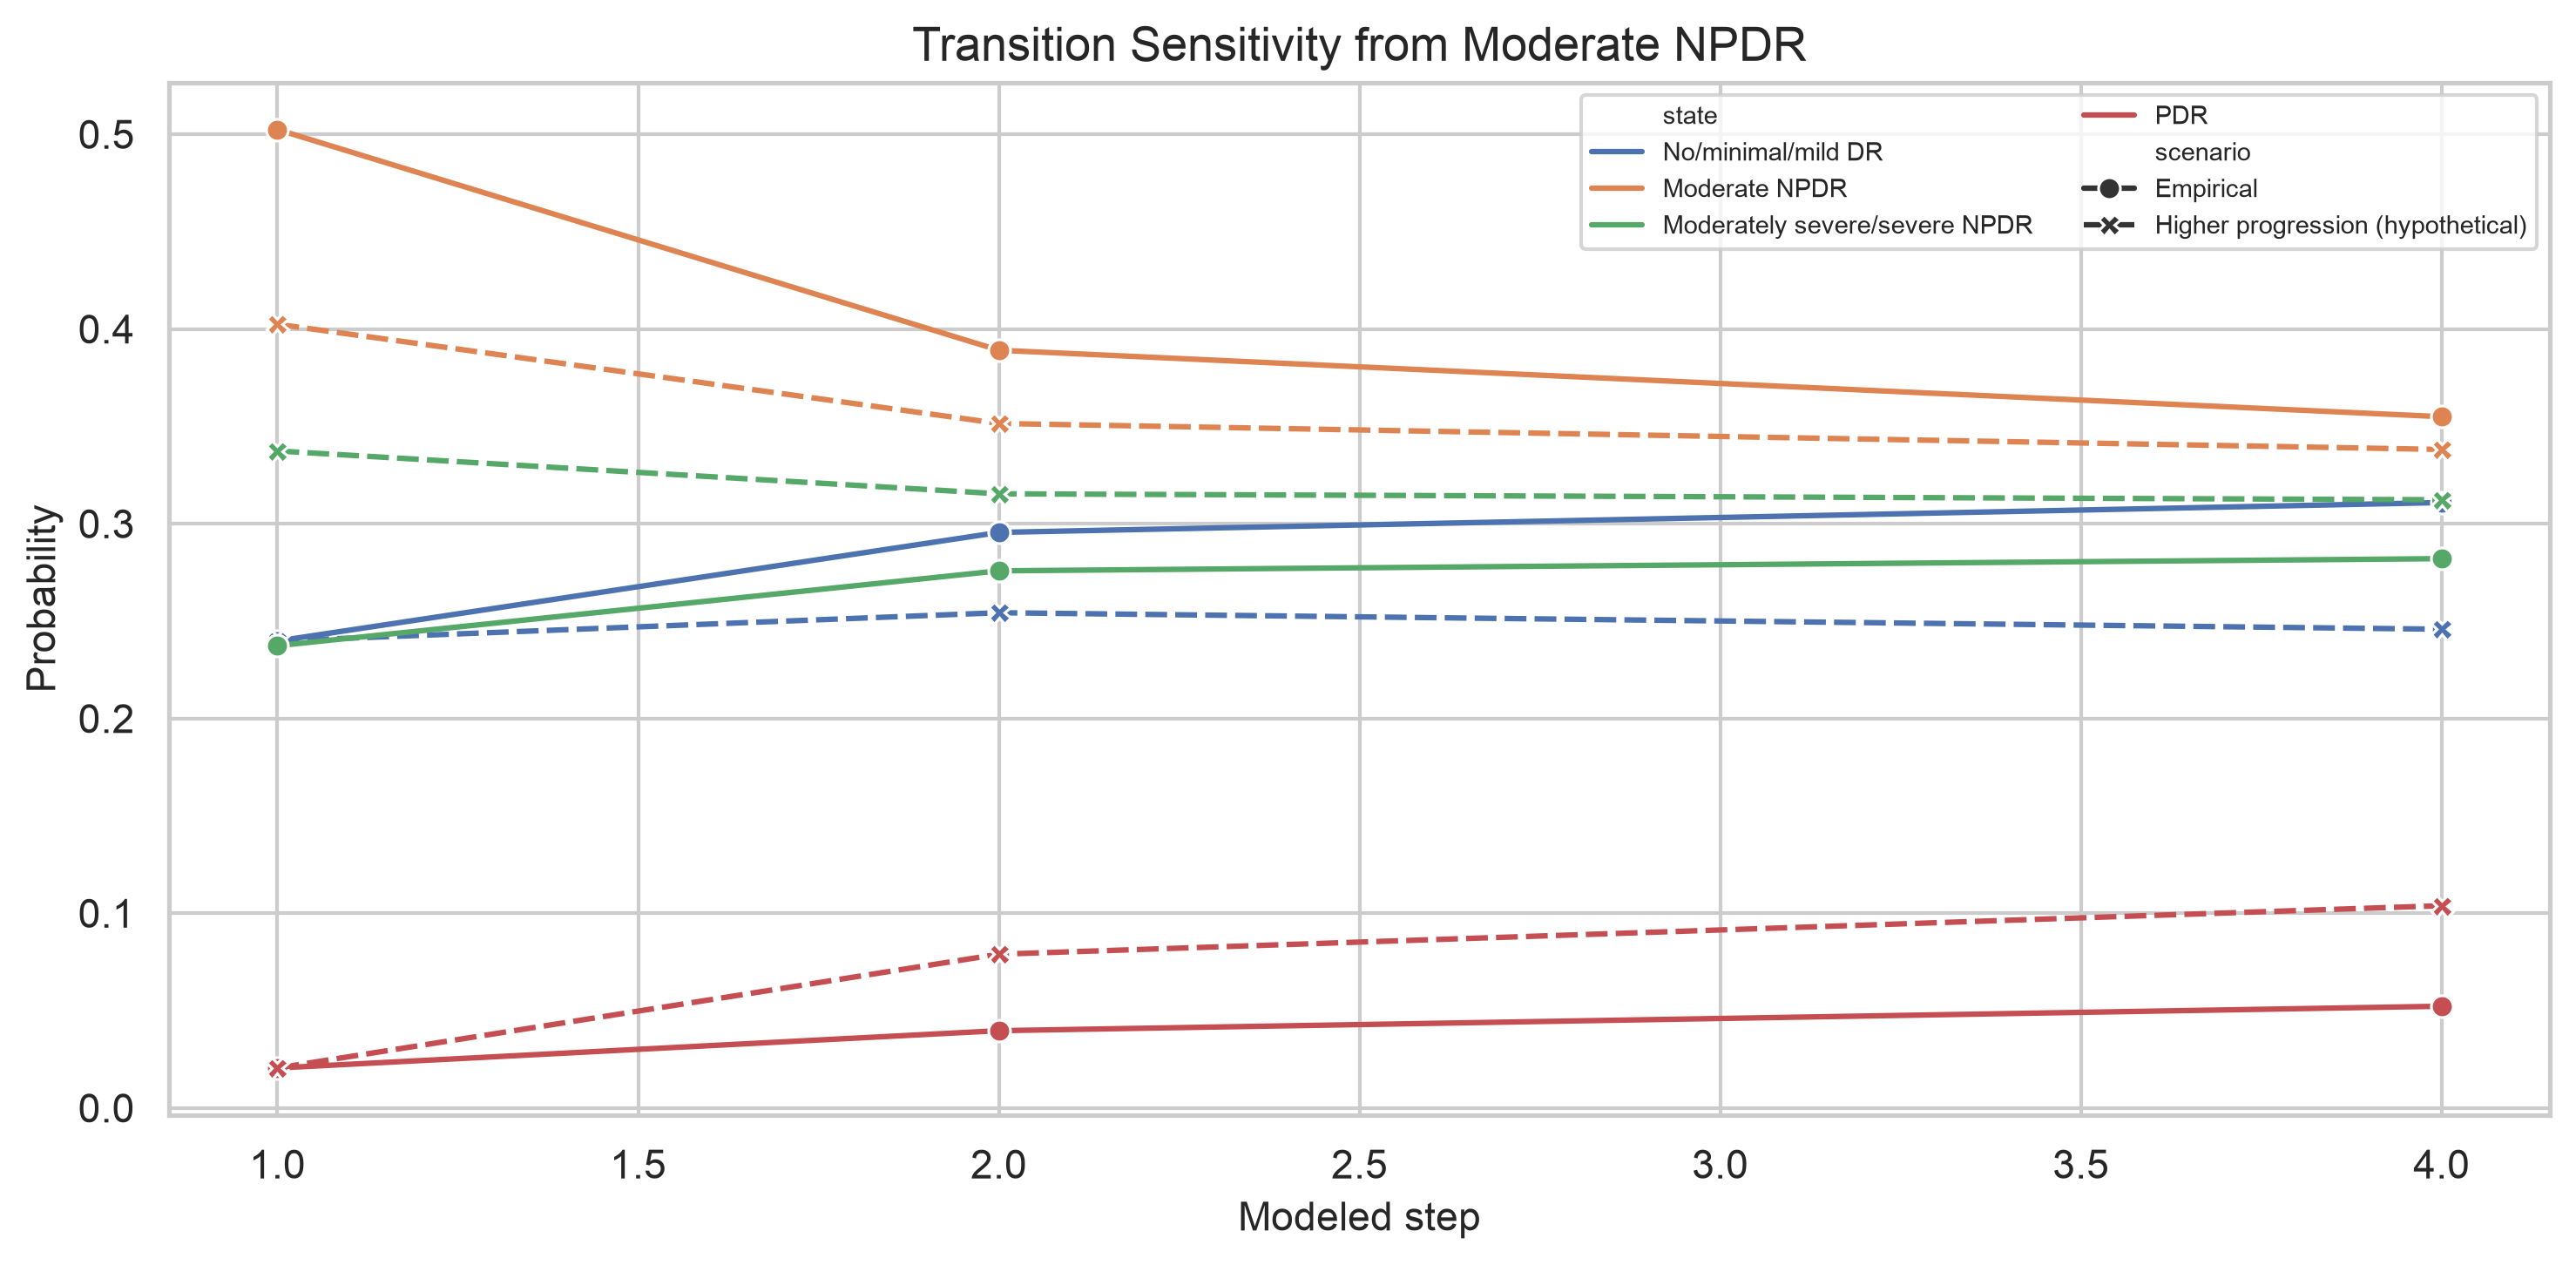

In [15]:
display(pd.read_csv(TABLES / 'transition_change_summary.csv'))
display(pd.read_csv(TABLES / 'transitions_by_interval.csv'))
for name in ['19_observed_state_by_visit.png','20_multistep_state_evolution.png','21_transition_sensitivity.png']:
    display(Image(filename=str(FIGURES / name)))

## 15. First-Order vs Second-Order Comparison

Evaluation uses a patient-grouped holdout. Second-order probabilities back off to first order for unseen state pairs.

In [16]:
display(comparison)
delta = comparison.iloc[1].log_loss - comparison.iloc[0].log_loss
print(f'Second-order minus first-order log loss: {delta:.3f} (negative favors second order).')
print('This comparison does not prove or disprove the Markov property.')

,model,test_transitions,accuracy,log_loss,second_order_context_coverage,train_patients,test_patients
0,First-order,439,0.553531,1.018639,NaN,291,97
1,Second-order with first-order backoff,439,0.589977,0.998192,1.0,291,97


Second-order minus first-order log loss: -0.020 (negative favors second order).
This comparison does not prove or disprove the Markov property.


## 16. Integration of Clustering and Longitudinal Modeling

Baseline K-Means labels are linked to subsequent observed transitions. This is exploratory, unadjusted association—not causation.

,cluster,change,n_transitions,proportion
0,0,Progression,234,0.201204
1,0,Regression,259,0.222700
2,0,Stable,670,0.576096
3,1,Progression,283,0.240646
4,1,Regression,247,0.210034
5,1,Stable,646,0.549320


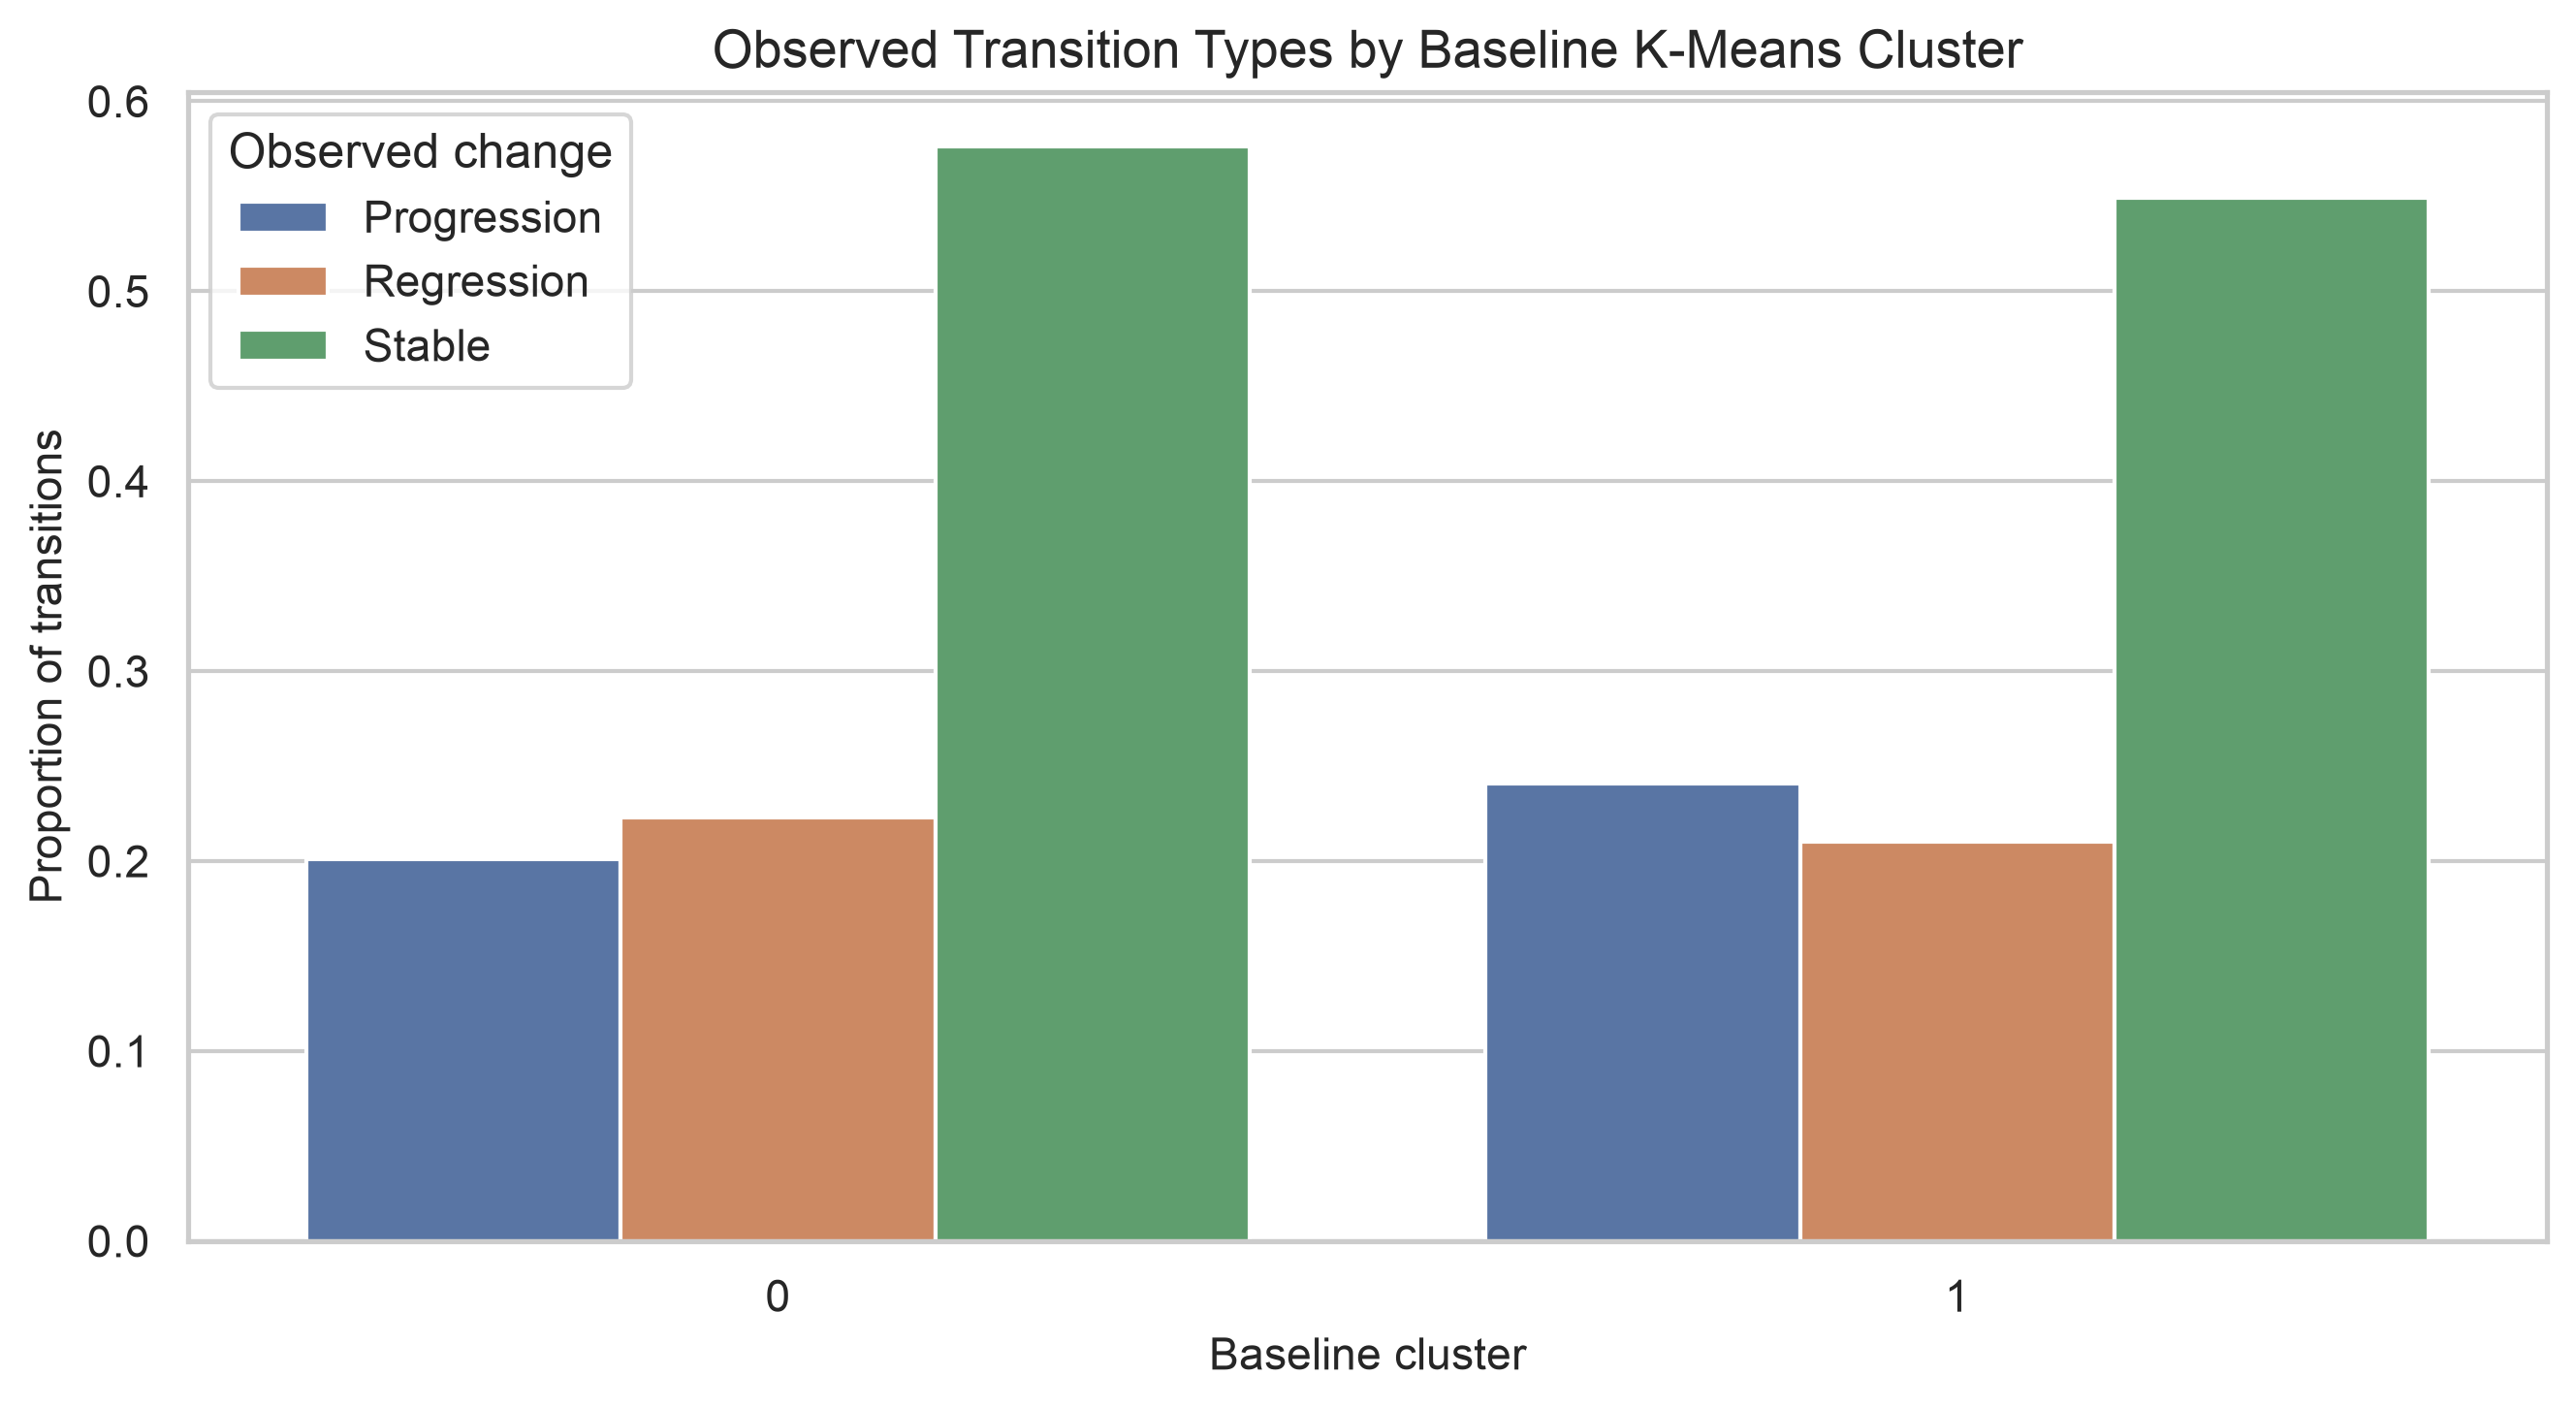

In [17]:
integration = pd.read_csv(TABLES / 'cluster_transition_integration.csv')
display(integration)
display(Image(filename=str(FIGURES / '23_transitions_by_baseline_cluster.png')))

## 17. Results and Research Inferences

In [18]:
print((ROOT / 'reports' / 'results_summary.md').read_text())

# PBL-2 Results Summary

## Unit 3

- Selected K-Means: K=2, silhouette=0.133, stability ARI=0.864.
- Selected hierarchical: ward, K=6, silhouette=0.091, stability ARI=0.318.
- Cross-method adjusted Rand agreement: 0.099.
- Clusters are feature-based exploratory subgroups, not validated clinical phenotypes.

## Unit 4

- Observed transitions: 2,384.
- Stable/progression/regression: 1351/522/511.
- Largest empirical transition probability: No/minimal/mild DR → No/minimal/mild DR (0.661).
- Best grouped-holdout log loss: Second-order with first-order backoff (0.998); this does not prove or disprove the Markov property.

## Integration

Baseline cluster membership was linked to 2,339 subsequent observed transitions. Differences are exploratory and unadjusted; they are not evidence that clusters cause progression.



## 18. Limitations

- One observational cohort and no external validation.
- Two eyes are correlated within patients.
- Attrition, missing grading, treatment, and unequal intervals affect trajectories.
- Clustering depends on features, scaling, K, and linkage.
- Markov modeling is descriptive and non-causal.
- Cluster–transition integration is exploratory and unadjusted.

In [19]:
print('Interval summary (days):')
display(longitudinal.days_since_previous.describe().to_frame())
print('Missing baseline feature counts:')
display(baseline[CLUSTER_FEATURES].isna().sum().to_frame('missing'))

Interval summary (days):


,days_since_previous
count,2384.00000
mean,381.10906
std,101.22884
min,172.00000
25%,343.00000
50%,369.00000
75%,399.00000
max,1515.00000


Missing baseline feature counts:


,missing
age,0
diabetes_duration,0
bmi,57
systolic_bp,0
diastolic_bp,0
hba1c,12
visual_acuity_letters,0
oct_central_thickness,1


## 19. Conclusion

K-Means and hierarchical clustering produced different partitions. Empirical transitions showed persistence plus both worsening and improvement. Additional history modestly improved the grouped holdout, but this is not proof against a first-order approximation. Results are hypothesis-generating.

In [20]:
print('Reproducible PBL-2 analysis complete.')
print('Figures:', len(list(FIGURES.glob('*.png'))), 'Tables:', len(list(TABLES.glob('*.csv'))))

Reproducible PBL-2 analysis complete.
Figures: 24 Tables: 23


## 20. References and Data Attribution

**Required attribution:** The source of the data is the DRCR Retina Network (Unique Federal Award Identification Number (FAIN) UG1EY014231). Protocol AA: Peripheral Diabetic Retinopathy (DR) Lesions on Ultrawide-field Fundus Images and Risk of DR Worsening Over Time [Data file]. Retrieved from https://public.jaeb.org/drcrnet. The analyses content and conclusions presented herein are solely the responsibility of the authors and have not been reviewed or approved by the DRCR Retina Network or Jaeb Center for Health Research.

Marcus DM et al., *JAMA Ophthalmology* (2022), doi:10.1001/jamaophthalmol.2022.3131.  
Silva PS et al., *JAMA Ophthalmology* (2022), doi:10.1001/jamaophthalmol.2022.3130.